# **GROUP 2 - NATURAL LANGUAGE PROCESSING**

---



## **"Implementation of Guardrails for Moderating Code-Mixed Hate Speech on Indonesian Social Media"**



### **Notebook 1/2 — `HateGuard_Training_Final`: Training, Verification, Evaluation, Ablation, Error Analysis, and Artifact Freezing**



---



**Group Members:** Michael Respati Sanjaya Ho (535250008) · Felix Lin (535250044) · Charlie Jhodya Soe (535250180)



---



### **Role of this notebook: *single source of truth* for all numbers in the paper**



All numbers, tables, and figures cited in the paper originate from the output of this notebook (exported to `results/` and `RESULTS_SINGLE_SOURCE.json` in the final cell). The `HateGuard_App_Final` notebook consumes the artifacts produced by this notebook and does not generate evaluation numbers.



---



### **Two execution modes (`RUN_MODE` variable in Cell 1)**



**Mode:** `verify_frozen`



**Behavior:**  

Loads the pre-trained checkpoint, **verifies SHA-256 checksums and provenance**, then executes the entire evaluation, ablation, and analysis in **FP32** precision using the exact same inference path as the application.



**Generated Artifacts:**  

Model weights, experiment manifest, evaluation results, and additional documentation required for experiment reproducibility.



**Mode:** `retrain_new_dir`



**Behavior:**  

Performs fine-tuning from `indolem/indobertweet-base-uncased` using recorded configurations and saves the output to a separate directory (`hateguard_artifacts_retrain`).



**Generated Artifacts:**  

A new training directory containing model weights, configurations, training logs, and all experimental artifacts generated during the fine-tuning process.

In [1]:
# CELL 1 — SETUP, CONFIGURATION, DETERMINISM, & ENVIRONMENT NOTES

!pip install transformers datasets scikit-learn scipy pandas accelerate joblib matplotlib seaborn huggingface_hub -q

import os
# Must be set BEFORE the first CUDA operation to ensure cuBLAS determinism.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import re, sys, json, random, hashlib, shutil, subprocess, platform, importlib.util, warnings
import joblib, requests
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from datetime import datetime
from zoneinfo import ZoneInfo
from scipy.stats import binomtest
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix,
                             brier_score_loss, roc_auc_score)
import transformers, datasets, sklearn

def sha256_file(file_path: str, chunk_size: int = 8 * 1024 * 1024) -> str:
    """Use streaming SHA-256 so large files are not read into RAM all at once."""
    digest = hashlib.sha256()
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


# EXECUTION MODE — see the table in the opening markdown.
#   "verify_frozen"   : verify the frozen checkpoint + re-evaluate FP32 (default, safe).
#   "retrain_new_dir" : fine-tune again into a SEPARATE directory (does not overwrite frozen artifacts).
RUN_MODE = "verify_frozen"
assert RUN_MODE in {"verify_frozen", "retrain_new_dir"}, "Invalid RUN_MODE"
RETRAIN = (RUN_MODE == "retrain_new_dir")

FROZEN_DRIVE_DIR = "/content/drive/MyDrive/HateGuard/hateguard_artifacts"      # frozen artifacts (source of truth)
_suffix = "_retrain" if RETRAIN else ""

# TRAINING CONFIGURATION — values & keys are NOT changed from the previous revision (compatible with the frozen manifest/config.json).
CONFIG = {
    "seed": 42,
    "model_checkpoint": "indolem/indobertweet-base-uncased",
    "llm_checkpoint": "Qwen/Qwen2.5-1.5B-Instruct",
    "max_length": 128,
    "padding_strategy": "max_length",
    "test_size": 0.20,
    "val_size_from_train": 0.10,
    "num_epochs": 2,
    "batch_size": 16,
    "learning_rate": 2e-5,
    "weight_decay": 0.01,
    "paired_eval_sample_size": 50,          # old N=50 replication (exploratory)
    "guardrail_thresholds": {"safe_max": 0.50, "weak_max": 0.75, "moderate_max": 0.90},
    "artifact_dir": f"./hateguard_artifacts{_suffix}",
    "drive_artifact_dir": f"/content/drive/MyDrive/HateGuard/hateguard_artifacts{_suffix}",
    "legacy_drive_model_dir": "/content/drive/MyDrive/HateGuard/model_hate_speech_final"
}

# EVALUATION CONFIGURATION — kept separate from CONFIG so the frozen config.json/bundle remains unchanged.
EVAL_CONFIG = {
    "n_bootstrap": 1000,            # group resampling for count-based metric CIs (confusion)
    "n_bootstrap_auc": 500,         # group resampling for AUROC (more computationally expensive)
    "bootstrap_seed": 42,
    "ci_level": 0.95,
    "paired_primary_n": 400,        # primary N for LLM comparison (200 per class, 1 text per group_id)
    "llm_calib_n": 200,             # separate VALIDATION samples for Qwen threshold calibration
    "near_dup_cosine": 0.80,        # near-duplicate candidate threshold (TF-IDF cosine)
    "tfidf_C_grid": [0.5, 2.0, 8.0],# selected using VALIDATION only
    "prevalence_grid": [0.01, 0.05, 0.10],
    "qualitative_per_cell": 3,      # random qualitative samples per cell (categories predefined)
}

OUTPUT_DIR = CONFIG["artifact_dir"]
FIG_DIR = os.path.join(OUTPUT_DIR, "figures")
RESULTS_DIR = os.path.join(OUTPUT_DIR, "results")
for d in (OUTPUT_DIR, FIG_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

def seed_everything(seed: int = 42):
    """Fix Python/NumPy/PyTorch RNGs + deterministic mode (warn_only prevents crashes when operations lack deterministic implementations)."""
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)

seed_everything(CONFIG["seed"])

ENVIRONMENT = {
    "python": sys.version.split()[0], "platform": platform.platform(),
    "torch": torch.__version__, "transformers": transformers.__version__,
    "datasets": datasets.__version__, "scikit_learn": sklearn.__version__,
    "pandas": pd.__version__, "numpy": np.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}
print(f"RUN_MODE = {RUN_MODE} | OUTPUT_DIR = {OUTPUT_DIR}")
print(json.dumps(ENVIRONMENT, indent=2))

RUN_MODE = verify_frozen | OUTPUT_DIR = ./hateguard_artifacts
{
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "torch": "2.11.0+cu130",
  "transformers": "5.20.2",
  "datasets": "4.8.5",
  "scikit_learn": "1.6.1",
  "pandas": "2.2.3",
  "numpy": "2.1.3",
  "cuda_available": true,
  "cuda_version": "13.0",
  "gpu": "Tesla T4"
}


## 1. Shared Module, Data, and Splitting Protocol



**Shared Module `hateguard_core.py`.** Text cleaning functions, lexical masking, threshold-to-action level mapping, guardrail policy text, and FP32 logit inference are written **once** (as a string in the following cell), saved as a file, and then **imported by Training, App, and the smoke test**. The SHA-256 checksum of this file is recorded in the manifest. With this approach, all components share the exact same implementation, ensuring logic and policy consistency across every stage of usage.



### Data Protocol



**Data Sources:**

- (i) Ibrohim & Budi (2019), 1 tweet = 1 `group_id`.

- (ii) `aiatums/codemixed-id-hate-speech` (Indonesian–Javanese, Indonesian–Sundanese): 1 *original* text + 2 augmented variations bound to **a single `group_id`** (hash of the original text).



**Label-Preserving Assumption:** Augmented variations inherit the label of their original text. This assumption **was not human-verified** and is therefore documented as a *limitation* (see the last cell).



**Data Cleaning Steps:**

1. Remove empty texts.

2. Remove **contradictory** texts (identical cleaned text, different labels).

3. Deduplicate based on `text_clean`.



Note: The contradictory text filter uses labels from **the entire corpus prior to splitting**. While performed as a data cleaning step rather than model tuning, it may result in a slightly cleaner test set compared to real-world data conditions. This is noted as a *limitation*.



### Data Splitting Protocol



- Splitting was performed using `GroupShuffleSplit` at 80/20 (test), followed by 90/10 (validation) based on `group_id`.

- *Assert* statements were executed to guarantee no overlap of `group_id` or `text_clean` across partitions.

- **External hold-out** uses the official `test` split from the code-mixed dataset (original texts only), filtered to eliminate any overlap with all internal partitions.



The *external hold-out* dataset serves as evaluation data that was unused during training or validation. It originates from the same corpus and generation pipeline, constituting a distinct *held-out set* despite not being a completely distinct domain.



### Model Selection



Model selection was conducted using `load_best_model_at_end` based on the F1 metric, utilizing **only the validation set**. Neither the internal **test** set nor the **external hold-out** set was used during model selection.

In [2]:
# CELL 2 — SHARED MODULE (hateguard_core.py), RAW DATA DOWNLOAD, LEXICON

CORE_SOURCE = r'''
"""hateguard_core.py — kode bersama Training, App, dan smoke test (SHA-256 dicatat di manifest).
Jangan diedit manual: perubahan apa pun mengubah SHA-256 dan akan ditolak oleh App (Hard Fail)."""
import re
import numpy as np
import pandas as pd

CORE_VERSION = "1.0.0"
POLICY_VERSION = "tier-4-softmax-0.50-0.75-0.90/v1"

RE_HEX_ESCAPE = re.compile(r"(\\x[0-9a-fA-F]{2})+")
RE_URL = re.compile(r"https?://\S+|www\.\S+")
RE_MENTION = re.compile(r"@\w+")
RE_PLACEHOLDER = re.compile(r"\b(rt|user|url)\b", flags=re.IGNORECASE)
RE_MULTISPACE = re.compile(r"\s+")

def clean_text(text, kamus):
    """Pembersihan + normalisasi 4 bahasa (IDENTIK dengan revisi beku; menentukan preprocessing_parity_hash):
    1) case folding; 2) buang hex-escape, URL, mention, placeholder crawler (rt/user/url);
    3) normalisasi token per-kata memakai kamus (tanda baca tepi dipertahankan)."""
    if text is None or pd.isna(text):
        return ""
    text = str(text).lower()
    text = RE_HEX_ESCAPE.sub(" ", text)
    text = RE_URL.sub(" ", text)
    text = RE_MENTION.sub(" ", text)
    text = RE_PLACEHOLDER.sub(" ", text)
    normalized_tokens = []
    for raw_token in text.split():
        prefix_punct = ""
        suffix_punct = ""
        core_word = raw_token
        while len(core_word) > 1 and not core_word[0].isalnum():
            prefix_punct += core_word[0]
            core_word = core_word[1:]
        while len(core_word) > 1 and not core_word[-1].isalnum():
            suffix_punct = core_word[-1] + suffix_punct
            core_word = core_word[:-1]
        mapped_word = kamus.get(core_word, core_word)
        normalized_tokens.append(f"{prefix_punct}{mapped_word}{suffix_punct}")
    return RE_MULTISPACE.sub(" ", " ".join(normalized_tokens)).strip()

_CENSOR_CACHE = {}
def _mask_match(match):
    w = match.group(0)
    if len(w) <= 2:
        return "*" * len(w)
    return w[0] + ("*" * (len(w) - 2)) + w[-1]

def censor_sensitive_words(text, sensitive_words):
    """Sensor leksikal (huruf pertama & terakhir dipertahankan). Output tampilan, BUKAN input model."""
    out = text
    for word in sensitive_words:
        pat = _CENSOR_CACHE.get(word)
        if pat is None:
            pat = re.compile(rf"\b{re.escape(word)}\b", flags=re.IGNORECASE)
            _CENSOR_CACHE[word] = pat
        out = pat.sub(_mask_match, out)
    return out

def prob_to_level(p_hs, thresholds):
    """Ambang OPERASIONAL berbasis softmax (bukan ukuran keparahan linguistik terkalibrasi)."""
    if p_hs < thresholds["safe_max"]:
        return "safe"
    if p_hs < thresholds["weak_max"]:
        return "weak"
    if p_hs < thresholds["moderate_max"]:
        return "moderate"
    return "strong"

def predicted_label_from_p(p_hs, thresholds):
    return "HATE_SPEECH" if p_hs >= thresholds["safe_max"] else "NON_HATE_SPEECH"

def policy_decision(level, raw_text, masked_text):
    """Teks kebijakan guardrail — SATU definisi untuk Training dan App (tanpa efek samping/antrean)."""
    if level == "safe":
        return {"action": "tayang_normal",
                "status_label": "✅ NON-HATE SPEECH — DITAMPILKAN NORMAL (ACTION LEVEL: SAFE)",
                "public_output": raw_text}
    if level == "weak":
        return {"action": "flag_censor_ringan",
                "status_label": "⚠️ HATE SPEECH INDIKASI RENDAH — DISENSOR LEKSIKAL (ACTION LEVEL: WEAK)",
                "public_output": f"[⚠️ Disensor Leksikal] {masked_text}"}
    if level == "moderate":
        return {"action": "flag_spoiler_log",
                "status_label": "🟠 HATE SPEECH INDIKASI MENENGAH — SPOILER & DISENSOR (ACTION LEVEL: MODERATE)",
                "public_output": f"[🟠 Peringatan Konten Sensitif]: {masked_text}"}
    return {"action": "blokir_eskalasi",
            "status_label": "⛔ HATE SPEECH INDIKASI TINGGI — DIBLOKIR & MASUK ANTREAN MODERATOR (ACTION LEVEL: STRONG)",
            "public_output": "[⛔ KOMENTAR DIBLOKIR OTOMATIS OLEH HATEGUARD — MENUNGGU KEPUTUSAN MODERATOR MANUSIA (PENDING REVIEW)]"}

def logits_fp32(texts, tokenizer, model, device, max_length, padding, batch_size=64):
    """Jalur inferensi TUNGGAL (FP32, tanpa autocast, no_grad). Dipakai Training, App, dan smoke test."""
    import torch
    model.eval()
    outs = []
    texts = list(texts)
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            enc = tokenizer(texts[i:i + batch_size], return_tensors="pt", truncation=True,
                            padding=padding, max_length=max_length)
            enc = {k: v.to(device) for k, v in enc.items()}
            outs.append(model(**enc).logits.to(torch.float32).cpu().numpy())
    return np.concatenate(outs, axis=0) if outs else np.zeros((0, 2), dtype=np.float32)

def softmax_hs(logits):
    """P(HATE_SPEECH) dari logit [N,2], stabil secara numerik (float64)."""
    z = np.asarray(logits, dtype=np.float64)
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e[:, 1] / e.sum(axis=1)
'''

CORE_PATH = os.path.join(OUTPUT_DIR, "hateguard_core.py")
with open(CORE_PATH, "w", encoding="utf-8") as f:
    f.write(CORE_SOURCE)
_spec = importlib.util.spec_from_file_location("hateguard_core", CORE_PATH)
core = importlib.util.module_from_spec(_spec)
sys.modules["hateguard_core"] = core
_spec.loader.exec_module(core)
CORE_SHA256 = sha256_file(CORE_PATH)
print(f"hateguard_core v{core.CORE_VERSION} | SHA-256: {CORE_SHA256}")

# Download the base dataset + slang dictionary; record raw file SHA-256 (the GitHub 'master' source is mutable).
url_dataset = "https://raw.githubusercontent.com/okkyibrohim/id-multi-label-hate-speech-and-abusive-language-detection/master/re_dataset.csv"
url_kamus = "https://raw.githubusercontent.com/okkyibrohim/id-multi-label-hate-speech-and-abusive-language-detection/master/new_kamusalay.csv"

def download_with_hash(url: str, dest: str) -> str:
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    with open(dest, "wb") as f:
        f.write(r.content)
    return sha256_file(dest)

RAW_FILE_HASHES = {
    "re_dataset.csv": download_with_hash(url_dataset, "re_dataset.csv"),
    "new_kamusalay.csv": download_with_hash(url_kamus, "new_kamusalay.csv"),
}
print("Raw file SHA-256:", json.dumps(RAW_FILE_HASHES, indent=2))

df_ibrohim = pd.read_csv("re_dataset.csv", encoding="latin-1")
alay_df = pd.read_csv("new_kamusalay.csv", encoding="latin-1", header=None, names=["alay", "baku"])
kamus_gabungan = dict(zip(alay_df["alay"].astype(str).str.lower(), alay_df["baku"].astype(str).str.lower()))
alay_only_dict = dict(kamus_gabungan)   # copy BEFORE adding the 4-language lexicon (used in normalization ablation)

# 4-language normalization lexicon (maps regional/slang terms to canonical Indonesian/English forms for IndoBERTweet).
LEKSIKON_4_BAHASA = {
    "stfu": "shut the fuck up", "wtf": "what the fuck", "fck": "fuck", "fcking": "fucking",
    "btch": "bitch", "b*tch": "bitch", "bs": "bullshit", "loser": "pecundang",
    "dumbass": "bodoh", "idiot": "bodoh", "noob": "amatir", "salty": "kesal", "toxic": "beracun",
    "jancuk": "jancok", "dancok": "jancok", "juancok": "jancok", "cok": "jancok",
    "asu": "anjing", "asuu": "anjing", "pekok": "bodoh", "pekook": "bodoh",
    "goblok": "bodoh", "goblog": "bodoh", "raimu": "wajahmu", "ndasmu": "kepalamu",
    "matamu": "matamu", "modar": "mati", "koplak": "bodoh", "gendeng": "gila",
    "balegug": "belegug", "blgug": "belegug", "bagong": "babi", "bgng": "babi",
    "kehed": "keparat", "siah": "sia", "jurig": "setan", "geloo": "gelo",
    "anying": "anjing", "anjir": "anjing", "anjay": "anjing"
}
kamus_gabungan.update(LEKSIKON_4_BAHASA)

# Sensitive lexicon (ONLY for display censoring, never alters model input).
LEXICON_SENSITIF_4_BAHASA = sorted(list({
    "anjing", "anying", "asu", "babi", "bagong", "bangsat", "bajingan", "belegug",
    "bitch", "bodoh", "brengsek", "bullshit", "cebong", "cina", "fck", "fuck",
    "fucking", "gelo", "gendeng", "gila", "goblog", "goblok", "idiot", "jancok",
    "jancuk", "kampret", "kafir", "kapir", "kehed", "kontol", "memek", "modar",
    "monyet", "ndasmu", "ngewe", "pecundang", "pekok", "raimu", "sarap", "setan",
    "sia", "sinting", "stfu", "tai", "tolol", "tertolol", "tergoblok"
}), key=len, reverse=True)

def clean_text(text, kamus=kamus_gabungan):
    """Thin wrapper around core.clean_text (default: kamus_gabungan)."""
    return core.clean_text(text, kamus)

PREPROCESSING_PARITY_SAMPLES = [
    "RT USER: sia teh balegug pisan, dasar pekok! stfu https://t.co/xyz",
    "Woy omonganmu metu konteks terus wae, dasar pekok! @user123",
    "You look like you're under a lot of stress wearing trousers",
    "anjay keren pisan euy filmnya, ga ada obat!"
]
PREPROCESSING_PARITY_HASH = hashlib.sha256(
    "||".join([clean_text(s) for s in PREPROCESSING_PARITY_SAMPLES]).encode("utf-8")
).hexdigest()
FROZEN_PARITY_HASH_EXPECTED = "0ebe0f02665f2f7b49c5965ceb4ce35f17ba932da93ff528b4e691d6cc5152f8"  # value in frozen artifacts
print(f"Dictionary entries: {len(kamus_gabungan):,} | Sensitive lexicon: {len(LEXICON_SENSITIF_4_BAHASA)}")
print(f"Preprocessing Parity Hash: {PREPROCESSING_PARITY_HASH}")
if PREPROCESSING_PARITY_HASH != FROZEN_PARITY_HASH_EXPECTED:
    raise RuntimeError("Preprocessing parity hash DIFFERS from the frozen artifacts. The source dictionary (GitHub 'master') may have changed; "
                       "frozen weights must not be used with this preprocessing. Stop and investigate.")
print("✅ Preprocessing parity hash matches the frozen artifacts.")

# Provenance/license metadata from Hugging Face Hub (retrieved automatically; not guessed).
def hf_meta(repo_id: str, repo_type: str) -> dict:
    try:
        from huggingface_hub import HfApi
        api = HfApi()
        info = api.dataset_info(repo_id) if repo_type == "dataset" else api.model_info(repo_id)
        card = getattr(info, "card_data", None)
        return {"id": repo_id, "commit_sha": info.sha, "license": (card.get("license") if card else None),
                "last_modified": str(info.last_modified)}
    except Exception as e:
        return {"id": repo_id, "error": f"{type(e).__name__}: {e}"}

PROVENANCE_META = {
    "dataset_codemixed": hf_meta("aiatums/codemixed-id-hate-speech", "dataset"),
    "model_indobertweet": hf_meta(CONFIG["model_checkpoint"], "model"),
    "model_qwen": hf_meta(CONFIG["llm_checkpoint"], "model"),
    "raw_file_sha256": RAW_FILE_HASHES,
    "ibrohim_budi_2019_source": url_dataset,
}
print(json.dumps(PROVENANCE_META, indent=2))

hateguard_core v1.0.0 | SHA-256: e07ad4c7524b1ed3e30fa0fa5a91a9163c40ab4a0547663afc15ef7f861a91b6
Raw file SHA-256: {
  "re_dataset.csv": "44c04e31ad4b7ee4a95f1884e7af4da2c44b69762143eb2de0ede7f90502735e",
  "new_kamusalay.csv": "fe00f0c728ee8ecc40dca3c3001ff2701dba7d4417a4178fe5b5745243564f9d"
}
Dictionary entries: 15,195 | Sensitive lexicon: 47
Preprocessing Parity Hash: 0ebe0f02665f2f7b49c5965ceb4ce35f17ba932da93ff528b4e691d6cc5152f8
✅ Preprocessing parity hash matches the frozen artifacts.
{
  "dataset_codemixed": {
    "id": "aiatums/codemixed-id-hate-speech",
    "commit_sha": "19a03eba294171be64a5fcb5dcf7f36b6e86d72f",
    "license": "cc-by-4.0",
    "last_modified": "2026-05-16 21:39:18+00:00"
  },
  "model_indobertweet": {
    "id": "indolem/indobertweet-base-uncased",
    "commit_sha": "32e28c05b47e33b6675d2670a1745c50a65e987a",
    "license": "apache-2.0",
    "last_modified": "2021-09-18 01:24:17+00:00"
  },
  "model_qwen": {
    "id": "Qwen/Qwen2.5-1.5B-Instruct",
    "com

In [3]:
# CELL 3 — DATA LOADING, CLEANING, LEAKAGE-FREE SPLITTING, & COMPOSITION AUDIT
# (Operations & row order are IDENTICAL to the frozen revision to ensure the SHA-256 fingerprint remains consistent.)

from datasets import load_dataset

ORIG_DOMAINS = {"indonesian_twitter", "codemixed_javanese_orig", "codemixed_sundanese_orig"}

# 1. Validate Ibrohim & Budi (2019) labels
if df_ibrohim["HS"].isna().any():
    raise ValueError("Invalid labels (NaN) found in the 'HS' column of the Ibrohim & Budi dataset!")
unique_ib_labels = set(df_ibrohim["HS"].unique())
if not unique_ib_labels.issubset({0, 1}):
    raise ValueError(f"Invalid labels in the Ibrohim & Budi dataset: {unique_ib_labels - {0, 1}}")

df_ib_clean = df_ibrohim[["Tweet", "HS"]].dropna().drop_duplicates(subset=["Tweet"]).reset_index(drop=True)
df_ib_clean["source_domain"] = "indonesian_twitter"
df_ib_clean["variant_type"] = "original"

def make_source_hash(text: str) -> str:
    """group_id = hash of the normalized ORIGINAL text (MD5 is used only as an ID, not for security)."""
    return "grp_" + hashlib.md5(clean_text(text).encode("utf-8")).hexdigest()[:12]

df_ib_clean["group_id"] = df_ib_clean["Tweet"].apply(make_source_hash)

# 2. Code-mixed dataset (train for internal training/val/test; official test for external hold-out)
ds_jv = load_dataset("aiatums/codemixed-id-hate-speech", "Indonesian-Javanese")
ds_su = load_dataset("aiatums/codemixed-id-hate-speech", "Indonesian-Sundanese")
df_jv_raw = ds_jv["train"].to_pandas()
df_su_raw = ds_su["train"].to_pandas()

VALID_POS_LABELS = {"hate speech"}
VALID_NEG_LABELS = {"non-hate speech", "not hate speech", "non hate speech"}
VALID_ALL_LABELS = VALID_POS_LABELS | VALID_NEG_LABELS

def validate_and_expand_codemixed_dataframe(df_source: pd.DataFrame, lang_tag: str) -> pd.DataFrame:
    """Validate the label set (Hard Fail if NaN/unknown), then expand 1 row → 3 texts
    (original, augmented_1, augmented_2) linked to one group_id (hash of the original text)."""
    if "label" not in df_source.columns or df_source["label"].isna().any():
        raise ValueError(f"Invalid labels (NaN/empty) found in the '{lang_tag}' dataset!")
    unknown = set(df_source["label"].astype(str).str.strip().str.lower().unique()) - VALID_ALL_LABELS
    if unknown:
        raise ValueError(f"Invalid labels in the '{lang_tag}' dataset: {unknown}")
    records = []
    for idx, row in df_source.iterrows():
        grp_id = make_source_hash(str(row["original"]))
        lbl_str = str(row["label"]).strip().lower()
        if lbl_str in VALID_POS_LABELS:
            label = 1
        elif lbl_str in VALID_NEG_LABELS:
            label = 0
        else:
            raise ValueError(f"Invalid label '{lang_tag}' at row {idx}: '{row['label']}'")
        for col in ["original", "augmented_1", "augmented_2"]:
            records.append({"Tweet": row[col], "HS": label, "group_id": grp_id,
                            "source_domain": lang_tag if col != "original" else f"{lang_tag}_orig",
                            "variant_type": col})
    return pd.DataFrame(records)

df_cm_jv = validate_and_expand_codemixed_dataframe(df_jv_raw, "codemixed_javanese")
df_cm_su = validate_and_expand_codemixed_dataframe(df_su_raw, "codemixed_sundanese")
print("✅ Label set validation completed (no NaN/unknown labels).")

df_all = pd.concat([df_ib_clean, df_cm_jv, df_cm_su], ignore_index=True)
raw_domain_counts = df_all["source_domain"].value_counts().to_dict()
print(f"Total combined raw rows: {len(df_all):,}")

df_all["text_clean"] = df_all["Tweet"].apply(clean_text)
df_all = df_all[df_all["text_clean"].str.len() > 0].reset_index(drop=True)

# 3. Remove contradictory texts (identical cleaned text, different labels) — uses labels from the entire corpus (see limitation note)
label_nunique = df_all.groupby("text_clean")["HS"].nunique()
contradictory_texts = set(label_nunique[label_nunique > 1].index)
before_contra = len(df_all)
dom_before = df_all["source_domain"].value_counts()
df_all = df_all[~df_all["text_clean"].isin(contradictory_texts)].reset_index(drop=True)
dom_after = df_all["source_domain"].value_counts()
contra_removed_by_domain = (dom_before - dom_after.reindex(dom_before.index).fillna(0)).astype(int).to_dict()
print(f"Contradictory texts: {len(contradictory_texts):,} | rows removed: {before_contra - len(df_all):,} | by domain: {contra_removed_by_domain}")

# 4. Deduplicate text_clean
before_dedup = len(df_all)
df_all = df_all.drop_duplicates(subset=["text_clean"]).reset_index(drop=True)
print(f"Before dedup: {before_dedup:,} | After: {len(df_all):,}")
vc = df_all["HS"].value_counts().sort_index()
print("Final class distribution (0=Non-HS, 1=HS):", vc.to_dict(), (vc / vc.sum() * 100).round(2).to_dict())

# 5. Leakage-free Train/Val/Test split (GroupShuffleSplit based on group_id)
gss_test = GroupShuffleSplit(n_splits=1, test_size=CONFIG["test_size"], random_state=CONFIG["seed"])
train_full_idx, test_idx = next(gss_test.split(df_all, groups=df_all["group_id"]))
df_train_full = df_all.iloc[train_full_idx].reset_index(drop=True)
df_test = df_all.iloc[test_idx].reset_index(drop=True)
gss_val = GroupShuffleSplit(n_splits=1, test_size=CONFIG["val_size_from_train"], random_state=CONFIG["seed"])
train_idx, val_idx = next(gss_val.split(df_train_full, groups=df_train_full["group_id"]))
df_train = df_train_full.iloc[train_idx].reset_index(drop=True)
df_val = df_train_full.iloc[val_idx].reset_index(drop=True)

assert not (set(df_train["group_id"]) & set(df_test["group_id"])), "FATAL: group_id leakage between Train and Test!"
assert not (set(df_val["group_id"]) & set(df_test["group_id"])), "FATAL: group_id leakage between Val and Test!"
assert not (set(df_train["group_id"]) & set(df_val["group_id"])), "FATAL: group_id leakage between Train and Val!"
assert not (set(df_train["text_clean"]) & set(df_test["text_clean"])), "FATAL: text_clean leakage between Train and Test!"
assert not (set(df_train["text_clean"]) & set(df_val["text_clean"])), "FATAL: text_clean leakage between Train and Val!"

# 6. SHA-256 fingerprint per partition (schema & row order IDENTICAL to the frozen manifest)
FINGERPRINT_COLUMNS = ["text_clean", "HS", "group_id", "source_domain", "variant_type"]
FINGERPRINT_SCHEMA = "|".join(FINGERPRINT_COLUMNS)

def compute_split_fingerprint(df_part: pd.DataFrame) -> str:
    missing = [c for c in FINGERPRINT_COLUMNS if c not in df_part.columns]
    if missing:
        raise ValueError(f"Fingerprint columns not available: {missing}")
    rows = df_part[FINGERPRINT_COLUMNS].fillna("").astype(str).agg("|".join, axis=1)
    return hashlib.sha256("\n".join(rows.tolist()).encode("utf-8")).hexdigest()

SPLIT_FINGERPRINTS = {
    "fingerprint_schema": FINGERPRINT_SCHEMA,
    "corpus_total_rows": int(len(df_all)), "train_rows": int(len(df_train)),
    "val_rows": int(len(df_val)), "test_rows": int(len(df_test)),
    "corpus_sha256": compute_split_fingerprint(df_all),
    "train_split_sha256": compute_split_fingerprint(df_train),
    "val_split_sha256": compute_split_fingerprint(df_val),
    "test_split_sha256": compute_split_fingerprint(df_test),
}

# 7. External hold-out (official JV & SU test sets), filtered for internal overlap
df_ext_jv = validate_and_expand_codemixed_dataframe(ds_jv["test"].to_pandas(), "official_test_jv")
df_ext_su = validate_and_expand_codemixed_dataframe(ds_su["test"].to_pandas(), "official_test_su")
df_external_test = pd.concat([df_ext_jv, df_ext_su], ignore_index=True)
ext_rows_loaded = len(df_external_test)
df_external_test["text_clean"] = df_external_test["Tweet"].apply(clean_text)
df_external_test = df_external_test[df_external_test["text_clean"].str.len() > 0].reset_index(drop=True)
ext_rows_nonempty = len(df_external_test)
ext_nunique = df_external_test.groupby("text_clean")["HS"].nunique()
ext_contra = set(ext_nunique[ext_nunique > 1].index)
df_external_test = df_external_test[~df_external_test["text_clean"].isin(ext_contra)].reset_index(drop=True)
ext_rows_after_contra = len(df_external_test)
df_external_test = df_external_test.drop_duplicates(subset=["text_clean"]).reset_index(drop=True)
ext_rows_after_dedup = len(df_external_test)
_internal_texts = set(df_train["text_clean"]) | set(df_val["text_clean"]) | set(df_test["text_clean"])
_internal_groups = set(df_train["group_id"]) | set(df_val["group_id"]) | set(df_test["group_id"])
df_external_test = df_external_test[(~df_external_test["text_clean"].isin(_internal_texts)) &
                                    (~df_external_test["group_id"].isin(_internal_groups))].reset_index(drop=True)
ext_rows_after_overlap = len(df_external_test)
assert not (set(df_external_test["text_clean"]) & _internal_texts), "FATAL: external text overlap!"
assert not (set(df_external_test["group_id"]) & _internal_groups), "FATAL: external group_id overlap!"
SPLIT_FINGERPRINTS["external_test_rows"] = int(len(df_external_test))
SPLIT_FINGERPRINTS["external_test_split_sha256"] = compute_split_fingerprint(df_external_test)

# COMPOSITION AUDIT: analysis unit = group_id, not rows
def composition(df, name):
    t = df.groupby("source_domain").agg(rows=("HS", "size"), groups=("group_id", "nunique"), hs_rate=("HS", "mean"))
    t["split"] = name
    return t.reset_index()

composition_table = pd.concat([composition(df_train, "train"), composition(df_val, "val"),
                               composition(df_test, "test"), composition(df_external_test, "external")], ignore_index=True)
composition_table["rows_per_group"] = (composition_table["rows"] / composition_table["groups"]).round(2)
composition_table["hs_rate"] = composition_table["hs_rate"].round(4)
print("\n PARTITION COMPOSITION (rows vs groups; HS prevalence by domain) ")
display(composition_table)

n_aug_rows = int((~df_test["source_domain"].isin(ORIG_DOMAINS)).sum())
print(f"\nTest: {len(df_test):,} rows from {df_test['group_id'].nunique():,} groups. "
      f"Augmentation variants = {n_aug_rows:,} rows ({n_aug_rows/len(df_test)*100:.1f}% of rows) → row count INFLATES independent N; "
      f"use group-based CIs and report the original-text subset.")
print(f"External: loaded {ext_rows_loaded:,} → non-empty {ext_rows_nonempty:,} → contradiction-free {ext_rows_after_contra:,} "
      f"→ deduplicated {ext_rows_after_dedup:,} → free of internal overlap {ext_rows_after_overlap:,}")
print("\nPartition fingerprints:", json.dumps(SPLIT_FINGERPRINTS, indent=2))

README.md:   0%|          | 0.00/2.13k [00:00<?, ?B/s]

Indonesian-Javanese/train-00000-of-00001(…): reconstructing file:   0%|          |  0.00B / 23.7MB            

Indonesian-Javanese/train-00000-of-00001(…): downloading bytes:           |  0.00B            

Indonesian-Javanese/test-00000-of-00001.(…): reconstructing file:   0%|          |  0.00B / 93.5kB            

Indonesian-Javanese/test-00000-of-00001.(…): downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/45144 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

✅ Label set validation completed (no NaN/unknown labels).
Total combined raw rows: 283,887
Contradictory texts: 954 | rows removed: 11,503 | by domain: {'codemixed_sundanese': 38, 'codemixed_javanese': 0, 'codemixed_javanese_orig': 24, 'codemixed_sundanese_orig': 11441, 'indonesian_twitter': 0}
Before dedup: 272,008 | After: 199,360
Final class distribution (0=Non-HS, 1=HS): {0: 111761, 1: 87599} {0: 56.06, 1: 43.94}

 PARTITION COMPOSITION (rows vs groups; HS prevalence by domain) 


,source_domain,rows,groups,hs_rate,split,rows_per_group
0,codemixed_javanese,64007,2678,0.6239,train,23.90
1,codemixed_javanese_orig,2677,2677,0.6238,train,1.00
2,codemixed_sundanese,64565,2698,0.2630,train,23.93
3,codemixed_sundanese_orig,2016,2016,0.1815,train,1.00
4,indonesian_twitter,9382,9382,0.4202,train,1.00
5,codemixed_javanese,6833,285,0.5555,val,23.98
6,codemixed_javanese_orig,285,285,0.5544,val,1.00
7,codemixed_sundanese,7384,309,0.2285,val,23.90
8,codemixed_sundanese_orig,231,231,0.1732,val,1.00
9,indonesian_twitter,1046,1046,0.4293,val,1.00



Test: 40,934 rows from 4,100 groups. Augmentation variants = 37,027 rows (90.5% of rows) → row count INFLATES independent N; use group-based CIs and report the original-text subset.
External: loaded 6,000 → non-empty 2,000 → contradiction-free 2,000 → deduplicated 1,999 → free of internal overlap 1,995

Partition fingerprints: {
  "fingerprint_schema": "text_clean|HS|group_id|source_domain|variant_type",
  "corpus_total_rows": 199360,
  "train_rows": 142647,
  "val_rows": 15779,
  "test_rows": 40934,
  "corpus_sha256": "c084b0f51e993f62ce67edca95a8a8e45fa72a1d44520113020df37f79657203",
  "train_split_sha256": "226bdb2c5754a822130a79fc9bd5ad24f4ae42bec5fe37b742145efad6e3af51",
  "val_split_sha256": "818f37f496ff1be75d03df72bc275022838ca23f3ded733bc3d1362d4703e948",
  "test_split_sha256": "471b8f4158f078318e381a3c7cd5cbca0998d17cf9223718ff99e0854b5c4c8e",
  "external_test_rows": 1995,
  "external_test_split_sha256": "2d5eefe32ec6b635602e470b9f4a43511314ad853b9569d2aaa8255cd6a8a72a"
}


## **2. Model: Checkpoint Provenance Verification and Model Training**

- **`verify_frozen`**: The checkpoint is used after passing the verification process, namely (i) the model weights SHA-256 matches `trusted_model_sha256` in the manifest, (ii) the training configuration keys in the artifact's `config.json` match `CONFIG`, (iii) the set of text and labels for both **internal test** and **external hold-out** match the prediction CSVs used in the experiments, and (iv) the preprocessing parity hash matches. If the verification process is not satisfied, execution is terminated to maintain experimental consistency and integrity.

- **Limits of Available Evidence:** The experiment manifest stores configuration information via `config.json` and dataset fingerprints used during the experimental process. Data membership verification is conducted using these recorded fingerprints and configurations. This information is also documented in `experiment_manifest_addendum.json` as part of the experiment documentation and reproducibility of results.

- **`retrain_new_dir`**: Performs fine-tuning from `indolem/indobertweet-base-uncased` into a separate directory. The hyperparameters used are derived from `CONFIG`: LR 2e-5, batch size 16, 2 epochs, weight decay 0.01, `max_length=128`, and seed 42. Training is conducted using the specified configuration with a single seed value so that the entire process can be reproducibly executed with consistency.

In [4]:
# CELL 4 — FROZEN CHECKPOINT PROVENANCE VERIFICATION / (OPTIONAL) ISOLATED FINE-TUNING

from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer

try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Info: Google Drive is not mounted (local environment):", e)

seed_everything(CONFIG["seed"])

def _evaluation_rows_match_saved_csv(current_df: pd.DataFrame, saved_csv_path: str) -> tuple:
    """Match the (text_clean, label) set against the original run prediction CSV; row order is ignored."""
    if current_df is None or not os.path.isfile(saved_csv_path):
        return False, f"Comparison evaluation CSV is unavailable: {saved_csv_path}"
    try:
        saved_df = pd.read_csv(saved_csv_path)
        label_col = next((c for c in ["y_true", "HS", "label"] if c in saved_df.columns), None)
        if "text_clean" not in saved_df.columns or label_col is None:
            return False, "The old CSV does not contain the text_clean and/or actual label column."
        old = saved_df[["text_clean", label_col]].dropna().copy()
        cur = current_df[["text_clean", "HS"]].dropna().copy()
        old["text_clean"] = old["text_clean"].astype(str)
        cur["text_clean"] = cur["text_clean"].astype(str)
        old["label_norm"] = pd.to_numeric(old[label_col], errors="raise").astype(int)
        cur["label_norm"] = pd.to_numeric(cur["HS"], errors="raise").astype(int)
        if not set(old["label_norm"].unique()).issubset({0, 1}) or not set(cur["label_norm"].unique()).issubset({0, 1}):
            return False, "Labels outside the 0/1 range."
        if old["text_clean"].duplicated().any() or cur["text_clean"].duplicated().any():
            return False, "Duplicate texts found; exact-set matching requires manual inspection."
        old_map = dict(zip(old["text_clean"], old["label_norm"]))
        cur_map = dict(zip(cur["text_clean"], cur["label_norm"]))
        if old_map != cur_map:
            o, c = set(old_map), set(cur_map)
            return False, (f"Content/label mismatch: old={len(o):,}, current={len(c):,}, matching={len(o & c):,}, "
                           f"old-only={len(o - c):,}, new-only={len(c - o):,}, "
                           f"label-mismatches={sum(old_map[t] != cur_map[t] for t in o & c):,}.")
        return True, f"{len(cur_map):,} texts and labels are identical; row order is ignored."
    except Exception as exc:
        return False, f"Failed to compare evaluation CSV files: {exc}"

def validate_checkpoint_provenance(candidate_model_dir: str) -> tuple:
    """Verify checkpoint integrity: weight checksum, training configuration keys, test/external set
    matching against the original run CSVs, fingerprint schema, and preprocessing parity hash."""
    parent_dir = os.path.dirname(candidate_model_dir)
    manifest_path = os.path.join(parent_dir, "experiment_manifest.json")
    artifact_config_path = os.path.join(parent_dir, "config.json")
    weight_file = os.path.join(candidate_model_dir, "model.safetensors")
    if not os.path.isfile(weight_file):
        weight_file = os.path.join(candidate_model_dir, "pytorch_model.bin")
    if not (os.path.isfile(manifest_path) and os.path.isfile(weight_file)):
        return False, "Experiment manifest or model weight file not found."
    if not os.path.isfile(artifact_config_path):
        return False, "Artifact config.json not found; training configuration cannot be verified."
    try:
        with open(manifest_path, "r", encoding="utf-8") as f:
            manifest = json.load(f)
        with open(artifact_config_path, "r", encoding="utf-8") as f:
            saved_config = json.load(f)
        actual_sha256 = sha256_file(weight_file)
        trusted_sha256 = manifest.get("trusted_model_sha256", "")
        if not trusted_sha256 or actual_sha256 != trusted_sha256:
            return False, (f"Weight checksum ({actual_sha256[:12]}...) does not match "
                           f"trusted_model_sha256 ({str(trusted_sha256)[:12]}...).")
        training_keys = ["model_checkpoint", "max_length", "padding_strategy", "seed",
                         "num_epochs", "batch_size", "learning_rate", "weight_decay"]
        config_diff = {k: {"saved": saved_config.get(k), "current": CONFIG.get(k)}
                       for k in training_keys if saved_config.get(k) != CONFIG.get(k)}
        if config_diff:
            return False, f"Checkpoint configuration differs from the current run: {config_diff}"
        saved_training_config = manifest.get("training_config")
        if saved_training_config:
            diff = {k: {"saved": saved_training_config.get(k), "current": CONFIG.get(k)}
                    for k in training_keys if saved_training_config.get(k) != CONFIG.get(k)}
            if diff:
                return False, f"training_config in the manifest differs: {diff}"
        test_ok, test_msg = _evaluation_rows_match_saved_csv(df_test, os.path.join(parent_dir, "test_predictions.csv"))
        if not test_ok:
            return False, f"Internal test set does not match the checkpoint: {test_msg}"
        ext_ok, ext_msg = _evaluation_rows_match_saved_csv(df_external_test, os.path.join(parent_dir, "external_test_predictions.csv"))
        if not ext_ok:
            return False, f"External hold-out does not match the checkpoint: {ext_msg}"
        saved_fp = manifest.get("split_fingerprints", {})
        if saved_fp.get("fingerprint_schema") and saved_fp.get("fingerprint_schema") != SPLIT_FINGERPRINTS["fingerprint_schema"]:
            return False, "Fingerprint schema differs from the current dataset. Checkpoint will not be used."
        mismatch = [k for k in ["corpus_sha256", "train_split_sha256", "val_split_sha256", "test_split_sha256"]
                    if saved_fp.get(k) != SPLIT_FINGERPRINTS.get(k)]
        if saved_fp.get("external_test_split_sha256") and saved_fp["external_test_split_sha256"] != SPLIT_FINGERPRINTS["external_test_split_sha256"]:
            mismatch.append("external_test_split_sha256")
        warnings_list = []
        if not saved_training_config:
            warnings_list.append("old manifest does not contain a separate training_config; training keys are matched through config.json")
        if mismatch:
            warnings_list.append("fingerprint mismatch for " + ", ".join(mismatch) +
                                 "; old train/val membership cannot be independently verified")
        if not manifest.get("preprocessing_parity_hash"):
            warnings_list.append("preprocessing parity hash is missing from the old manifest")
        elif manifest["preprocessing_parity_hash"] != PREPROCESSING_PARITY_HASH:
            warnings_list.append("preprocessing parity hash differs")
        msg = f"Weight checksum and configuration match; internal test matches ({test_msg}); external test matches ({ext_msg})."
        msg += (" WARNING: " + "; ".join(warnings_list) + ".") if warnings_list else " Partition fingerprints also match."
        return True, msg
    except Exception as exc:
        return False, f"Failed to read/verify checkpoint: {exc}"

EXISTING_CHECKPOINT = None
PROVENANCE_MESSAGE = "retrain_new_dir: no frozen checkpoint is being used."
if not RETRAIN:
    for candidate_dir in [os.path.join(FROZEN_DRIVE_DIR, "model_hate_speech_final"),
                          os.path.join("./hateguard_artifacts", "model_hate_speech_final")]:
        if os.path.isdir(candidate_dir):
            ok, reason = validate_checkpoint_provenance(candidate_dir)
            print(f"Provenance [{candidate_dir}]: {reason}")
            if ok:
                EXISTING_CHECKPOINT, PROVENANCE_MESSAGE = candidate_dir, reason
                break
            print("⚠️ Candidate skipped; checking the next candidate.")
    if EXISTING_CHECKPOINT is None:
        raise RuntimeError("No frozen checkpoint passed verification. The notebook is stopping to prevent silent retraining. "
                           "Check the artifact path, or intentionally set RUN_MODE='retrain_new_dir'.")
    print(f"✅ Loading verified model: {EXISTING_CHECKPOINT}")
    tokenizer = AutoTokenizer.from_pretrained(EXISTING_CHECKPOINT)
    model = AutoModelForSequenceClassification.from_pretrained(EXISTING_CHECKPOINT)
    TRAINED_IN_THIS_RUN = False
else:
    print(f"🚀 Starting new fine-tuning for {CONFIG['model_checkpoint']} → {OUTPUT_DIR} (frozen artifacts remain untouched).")
    tokenizer = AutoTokenizer.from_pretrained(CONFIG["model_checkpoint"])
    model = AutoModelForSequenceClassification.from_pretrained(
        CONFIG["model_checkpoint"], num_labels=2,
        id2label={0: "NON_HATE_SPEECH", 1: "HATE_SPEECH"}, label2id={"NON_HATE_SPEECH": 0, "HATE_SPEECH": 1})
    TRAINED_IN_THIS_RUN = True

model.config.id2label = {0: "NON_HATE_SPEECH", 1: "HATE_SPEECH"}
model.config.label2id = {"NON_HATE_SPEECH": 0, "HATE_SPEECH": 1}
print(f"TRAINED_IN_THIS_RUN = {TRAINED_IN_THIS_RUN}")

training_history_records = []
if TRAINED_IN_THIS_RUN:
    def tokenize_batch(batch):
        return tokenizer(batch["text"], truncation=True, padding=CONFIG["padding_strategy"], max_length=CONFIG["max_length"])

    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        preds = np.argmax(logits, axis=-1)
        p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="binary", zero_division=0)
        return {"accuracy": float(accuracy_score(labels, preds)), "precision": float(p), "recall": float(r), "f1": float(f1)}

    def to_ds(df):
        return Dataset.from_dict({"text": df["text_clean"].tolist(), "label": df["HS"].tolist()}) \
                      .map(tokenize_batch, batched=True).remove_columns(["text"])

    training_args = TrainingArguments(
        output_dir=os.path.join(OUTPUT_DIR, "hf_checkpoints"),
        num_train_epochs=CONFIG["num_epochs"], per_device_train_batch_size=CONFIG["batch_size"],
        per_device_eval_batch_size=CONFIG["batch_size"], learning_rate=CONFIG["learning_rate"],
        weight_decay=CONFIG["weight_decay"], eval_strategy="epoch", save_strategy="epoch",
        load_best_model_at_end=True, metric_for_best_model="f1", greater_is_better=True,   # selection ONLY on validation
        seed=CONFIG["seed"], data_seed=CONFIG["seed"], logging_steps=100, report_to="none",
        fp16=torch.cuda.is_available())
    trainer = Trainer(model=model, args=training_args, train_dataset=to_ds(df_train), eval_dataset=to_ds(df_val),
                      processing_class=tokenizer, compute_metrics=compute_metrics)
    print("Training Results:", trainer.train())
    training_history_records = trainer.state.log_history
else:
    for hp in [os.path.join(os.path.dirname(EXISTING_CHECKPOINT), "training_history.json"),
               os.path.join(OUTPUT_DIR, "training_history.json")]:
        if os.path.isfile(hp):
            with open(hp, "r", encoding="utf-8") as f:
                training_history_records = json.load(f)
            print(f"✅ Original training history loaded: {hp} ({len(training_history_records)} entries)")
            break
    if not training_history_records:
        print("⚠️ Original training history not found; training curves cannot be displayed.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device, dtype=torch.float32)   # evaluation inference path = pure FP32 (same as App)
model.eval()

Mounted at /content/drive
Provenance [/content/drive/MyDrive/HateGuard/hateguard_artifacts/model_hate_speech_final]: Weight checksum and configuration match; internal test matches (40,934 texts and labels are identical; row order is ignored.); external test matches (1,995 texts and labels are identical; row order is ignored.). WARNING: old manifest does not contain a separate training_config; training keys are matched through config.json; fingerprint mismatch for corpus_sha256, train_split_sha256, val_split_sha256, test_split_sha256; old train/val membership cannot be independently verified.
✅ Loading verified model: /content/drive/MyDrive/HateGuard/hateguard_artifacts/model_hate_speech_final


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

TRAINED_IN_THIS_RUN = False
✅ Original training history loaded: /content/drive/MyDrive/HateGuard/hateguard_artifacts/training_history.json (181 entries)


BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(31923, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

## **3. Statistical Protocol (Unit = `group_id`)**

All 95% confidence intervals use **grouped bootstrap**: groups (not rows) are resampled with replacement (`n_bootstrap` = 1000 for count-based metrics, 500 for AUROC), ensuring that the 24 augmented variations derived from a single original text are not treated as 24 independent observations.

The vectorization implementation is executed by summing confusion counts per group using multinomial weights equivalent to the group resampling process.

Two weighting approaches are reported:

- **Row** (standard, dominated by code-mixed augmented data).
- **Group** (each group receives equal weight) as a sensitivity test.

Comparisons between two models on the same data use a **paired grouped bootstrap** (resample weights are shared) to calculate metric differences.

An exact McNemar test is used on the LLM comparison sample because in that setup each group consists of a single text, allowing observations to be treated as independent.

In [5]:
# CELL 5 — STATISTICAL FUNCTIONS (grouped bootstrap, AUROC, calibration, paired delta, McNemar)
# This cell has no torch/GPU dependencies and is unit-tested separately (see Audit_Report.md).

from scipy.optimize import minimize_scalar

METRIC_NAMES = ["accuracy", "precision", "recall", "f1", "balanced_accuracy"]

def fmt_p(p: float) -> str:
    """Format p-values for captions: avoid misleading '0.0000' values."""
    return "<0.001" if p < 0.001 else f"{p:.3f}"

def wilson_ci(k: int, n: int, z: float = 1.96):
    """Wilson CI for proportions (valid only when observations are independent; use bootstrap for grouped data)."""
    if n == 0:
        return (float("nan"), float("nan"))
    ph = k / n
    den = 1 + z * z / n
    centre = (ph + z * z / (2 * n)) / den
    half = z * np.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / den
    return (float(centre - half), float(centre + half))

def factorize_groups(groups):
    codes, uniques = pd.factorize(pd.Series(groups).astype(str), sort=False)
    return np.asarray(codes), len(uniques)

def make_boot_weights(n_groups: int, n_boot: int, seed: int) -> np.ndarray:
    """Group resampling weights [n_boot, n_groups]; each row W[b] ~ Multinomial(n_groups, uniform) = sampling with replacement."""
    rng = np.random.default_rng(seed)
    return rng.multinomial(n_groups, np.full(n_groups, 1.0 / n_groups), size=n_boot).astype(np.float64)

def group_confusion(y_true, y_pred, codes, n_g, weight_mode="row"):
    """Per-group counts in columns [TN, FP, FN, TP]; weight_mode='group' divides by group size (each group has weight 1)."""
    idx = np.asarray(y_true).astype(int) * 2 + np.asarray(y_pred).astype(int)   # 0:TN 1:FP 2:FN 3:TP
    G = np.bincount(codes * 4 + idx, minlength=n_g * 4).reshape(n_g, 4).astype(np.float64)
    if weight_mode == "group":
        G = G / np.maximum(G.sum(axis=1, keepdims=True), 1.0)
    return G

def metrics_from_counts(c):
    c = np.asarray(c, dtype=np.float64)
    tn, fp, fn, tp = c[..., 0], c[..., 1], c[..., 2], c[..., 3]
    tot = np.maximum(tn + fp + fn + tp, 1e-12)
    prec = np.where(tp + fp > 0, tp / np.maximum(tp + fp, 1e-12), 0.0)
    rec = np.where(tp + fn > 0, tp / np.maximum(tp + fn, 1e-12), 0.0)
    f1 = np.where(prec + rec > 0, 2 * prec * rec / np.maximum(prec + rec, 1e-12), 0.0)
    tnr = np.where(tn + fp > 0, tn / np.maximum(tn + fp, 1e-12), 0.0)
    return {"accuracy": (tn + tp) / tot, "precision": prec, "recall": rec, "f1": f1,
            "balanced_accuracy": (rec + tnr) / 2, "fpr": 1 - tnr, "fnr": 1 - rec}

def pct_ci(arr, level=0.95):
    a = (1 - level) / 2 * 100
    lo, hi = np.percentile(np.asarray(arr, dtype=np.float64), [a, 100 - a])
    return float(lo), float(hi)

def grouped_bootstrap_metrics(y_true, y_pred, groups, n_boot=1000, seed=42, weight_mode="row", W=None, level=0.95):
    """Point estimates + grouped bootstrap CIs for accuracy/precision/recall/F1/balanced accuracy/FPR/FNR."""
    codes, n_g = factorize_groups(groups)
    G = group_confusion(y_true, y_pred, codes, n_g, weight_mode)
    W = make_boot_weights(n_g, n_boot, seed) if W is None else W
    point = metrics_from_counts(G.sum(axis=0))
    boot = metrics_from_counts(W @ G)
    out = {}
    for k in point:
        lo, hi = pct_ci(boot[k], level)
        out[k] = {"point": float(point[k]), "lo": lo, "hi": hi, "se": float(np.std(boot[k]))}
    return out

def grouped_bootstrap_auc(y, s, groups, n_boot=500, seed=42, level=0.95):
    y = np.asarray(y).astype(int); s = np.asarray(s, dtype=np.float64)
    if len(np.unique(y)) < 2:
        return {"point": float("nan"), "lo": float("nan"), "hi": float("nan"), "se": float("nan")}
    codes, n_g = factorize_groups(groups)
    rng = np.random.default_rng(seed)
    aucs = []
    for _ in range(n_boot):
        w = rng.multinomial(n_g, np.full(n_g, 1.0 / n_g)).astype(np.float64)
        sw = w[codes]
        m = sw > 0
        if len(np.unique(y[m])) < 2:
            continue
        aucs.append(roc_auc_score(y[m], s[m], sample_weight=sw[m]))
    lo, hi = pct_ci(aucs, level)
    return {"point": float(roc_auc_score(y, s)), "lo": lo, "hi": hi, "se": float(np.std(aucs))}

def paired_grouped_bootstrap_delta(y_true, pred_a, pred_b, groups, n_boot=1000, seed=42, weight_mode="row", level=0.95):
    """Metric differences (A − B) on the SAME data and group resamples. A CI that excludes 0 indicates a consistent difference across resamples."""
    codes, n_g = factorize_groups(groups)
    Ga = group_confusion(y_true, pred_a, codes, n_g, weight_mode)
    Gb = group_confusion(y_true, pred_b, codes, n_g, weight_mode)
    W = make_boot_weights(n_g, n_boot, seed)
    pa, pb = metrics_from_counts(Ga.sum(0)), metrics_from_counts(Gb.sum(0))
    ba, bb = metrics_from_counts(W @ Ga), metrics_from_counts(W @ Gb)
    out = {}
    for k in ["accuracy", "f1", "balanced_accuracy", "recall", "precision"]:
        d = ba[k] - bb[k]
        lo, hi = pct_ci(d, level)
        out[k] = {"delta_point": float(pa[k] - pb[k]), "lo": lo, "hi": hi}
    return out

def grouped_bootstrap_ratio(groups, num, den, n_boot=1000, seed=42, level=0.95):
    """Grouped bootstrap CI for the ratio Σnum/Σden (e.g., precision per tier, FP rate, escalation rate)."""
    codes, n_g = factorize_groups(groups)
    n_arr = np.bincount(codes, weights=np.asarray(num, dtype=np.float64), minlength=n_g)
    d_arr = np.bincount(codes, weights=np.asarray(den, dtype=np.float64), minlength=n_g)
    W = make_boot_weights(n_g, n_boot, seed)
    bn, bd = W @ n_arr, W @ d_arr
    ratios = np.where(bd > 0, bn / np.maximum(bd, 1e-12), np.nan)
    point = float(n_arr.sum() / d_arr.sum()) if d_arr.sum() > 0 else float("nan")
    lo, hi = pct_ci(ratios[~np.isnan(ratios)], level) if np.any(~np.isnan(ratios)) else (float("nan"), float("nan"))
    return {"point": point, "lo": lo, "hi": hi}

def ece_point(y, p, n_bins=10):
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    b = np.clip(np.digitize(p, edges[1:-1], right=False), 0, n_bins - 1)
    ece = 0.0
    for k in range(n_bins):
        m = b == k
        if m.any():
            ece += m.sum() / len(y) * abs(np.mean(y[m]) - np.mean(p[m]))
    return float(ece)

def grouped_bootstrap_calibration(y, p, groups, n_bins=10, n_boot=1000, seed=42, level=0.95):
    """ECE (10 bins, upper bin closed) & Brier score with grouped bootstrap CIs; linear statistics per group × bin."""
    y = np.asarray(y, dtype=np.float64); p = np.asarray(p, dtype=np.float64)
    codes, n_g = factorize_groups(groups)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    b = np.clip(np.digitize(p, edges[1:-1], right=False), 0, n_bins - 1)
    flat = codes * n_bins + b
    C = np.bincount(flat, minlength=n_g * n_bins).reshape(n_g, n_bins).astype(np.float64)
    SY = np.bincount(flat, weights=y, minlength=n_g * n_bins).reshape(n_g, n_bins)
    SP = np.bincount(flat, weights=p, minlength=n_g * n_bins).reshape(n_g, n_bins)
    SQ = np.bincount(codes, weights=(p - y) ** 2, minlength=n_g)
    N = np.bincount(codes, minlength=n_g).astype(np.float64)
    W = make_boot_weights(n_g, n_boot, seed)
    def stats(w):
        tc, ty, tp_ = w @ C, w @ SY, w @ SP
        n_tot = (w @ N)
        ece = np.abs(ty - tp_).sum(axis=-1) / n_tot
        brier = (w @ SQ) / n_tot
        return ece, brier
    ece_pt, brier_pt = stats(np.ones(n_g))
    ece_b, brier_b = stats(W)
    return {"ece": {"point": float(ece_pt), "lo": pct_ci(ece_b, level)[0], "hi": pct_ci(ece_b, level)[1]},
            "brier": {"point": float(brier_pt), "lo": pct_ci(brier_b, level)[0], "hi": pct_ci(brier_b, level)[1]}}

def reliability_table(y, p, n_bins=10):
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    b = np.clip(np.digitize(p, edges[1:-1], right=False), 0, n_bins - 1)
    rows = []
    for k in range(n_bins):
        m = b == k
        rows.append({"bin": f"[{edges[k]:.1f},{edges[k+1]:.1f}{']' if k == n_bins-1 else ')'}", "n": int(m.sum()),
                     "mean_confidence": float(np.mean(p[m])) if m.any() else np.nan,
                     "empirical_hs_rate": float(np.mean(y[m])) if m.any() else np.nan})
    return pd.DataFrame(rows)

def fit_temperature(logits, y):
    """Temperature scaling (1 parameter) minimizes NLL on VALIDATION; does not modify model weights."""
    z = np.asarray(logits, dtype=np.float64); y = np.asarray(y).astype(int)
    def nll(log_t):
        s = z / np.exp(log_t)
        s = s - s.max(axis=1, keepdims=True)
        logp = s - np.log(np.exp(s).sum(axis=1, keepdims=True))
        return -logp[np.arange(len(y)), y].mean()
    res = minimize_scalar(nll, bounds=(-3.0, 3.0), method="bounded")
    return float(np.exp(res.x))

def apply_temperature(logits, T):
    return core.softmax_hs(np.asarray(logits, dtype=np.float64) / T)

def levels_from_p(p, thr=None):
    thr = thr or CONFIG["guardrail_thresholds"]
    p = np.asarray(p)
    return np.select([p < thr["safe_max"], p < thr["weak_max"], p < thr["moderate_max"]],
                     ["safe", "weak", "moderate"], default="strong")

def mcnemar_exact(correct_a, correct_b):
    """Exact McNemar test (two-sided binomial) on independent units: b = A correct & B incorrect; c = A incorrect & B correct."""
    ca, cb = np.asarray(correct_a, bool), np.asarray(correct_b, bool)
    b, c = int(np.sum(ca & ~cb)), int(np.sum(~ca & cb))
    p = float(binomtest(b, b + c, 0.5).pvalue) if (b + c) > 0 else 1.0
    return {"b_A_only_correct": b, "c_B_only_correct": c, "p_value": p}

def summarize_subset(name, d, y_col="y_true", pred_col="y_pred_binary", score_col="p_hate_speech",
                     group_col="group_id", weight_mode="row", with_auc=True):
    """One row in the main results table: metrics + grouped bootstrap CIs + threshold-free AUROC + prevalence."""
    y, yp, g = d[y_col].to_numpy(), d[pred_col].to_numpy(), d[group_col].to_numpy()
    m = grouped_bootstrap_metrics(y, yp, g, EVAL_CONFIG["n_bootstrap"], EVAL_CONFIG["bootstrap_seed"], weight_mode)
    row = {"subset": name, "weighting": weight_mode, "n_rows": int(len(d)), "n_groups": int(pd.Series(g).nunique()),
           "prevalence_hs": float(np.mean(y))}
    for k in METRIC_NAMES:
        row[k], row[f"{k}_lo"], row[f"{k}_hi"] = m[k]["point"], m[k]["lo"], m[k]["hi"]
    if with_auc and score_col in d.columns:
        a = grouped_bootstrap_auc(y, d[score_col].to_numpy(), g, EVAL_CONFIG["n_bootstrap_auc"], EVAL_CONFIG["bootstrap_seed"])
        row["auroc"], row["auroc_lo"], row["auroc_hi"] = a["point"], a["lo"], a["hi"]
    return row

def fmt_ci(row, k, digits=4):
    return f"{row[k]:.{digits}f} [{row[k+'_lo']:.{digits}f}, {row[k+'_hi']:.{digits}f}]"

def compact_table(df_rows):
    """Display table: 'value [CI95]' per metric."""
    out = []
    for _, r in df_rows.iterrows():
        o = {"subset": r["subset"], "weighting": r["weighting"], "n_rows": r["n_rows"], "n_groups": r["n_groups"],
             "HS_prev": round(r["prevalence_hs"], 3)}
        for k in METRIC_NAMES + (["auroc"] if "auroc" in r.index and not pd.isna(r.get("auroc", np.nan)) else []):
            o[k] = fmt_ci(r, k)
        out.append(o)
    return pd.DataFrame(out)

## **4. Main Evaluation (FP32, Grouped Bootstrap) and Numerical Parity Verification**

This cell calculates logits for validation, internal test, and external hold-out using `hateguard_core.logits_fp32` (the same inference path used by the application), compares them with `test_predictions.csv`, reports the maximum probability difference as well as the number of label and tier flips, and then saves the results as official predictions used in the experiment.

**How to read the main table.**

`ALL_TEST (row-weighted)` displays evaluation results based on all rows of data, including augmented variants in the code-mixed dataset.

`ORIGINAL_ONLY` displays evaluation on unaugmented texts where each group is represented by a single original text. This result is used as a more conservative measure to describe model performance on real-world data.

`ALL_TEST (group-weighted)` is used as a sensitivity test by assigning equal weight to each group.

`AUROC` is a threshold-independent metric, whereas `balanced_accuracy` and `AUROC` do not depend on class prevalence. Therefore, these metrics are more suitable for comparing model performance across domains than metrics like precision, which can be influenced by class distribution.

In [6]:
# CELL 6 — FP32 INFERENCE (val/test/external), PARITY vs OLD CSV, TRUNCATION AUDIT, MAIN RESULTS TABLE

thr = CONFIG["guardrail_thresholds"]
LOGIT_BATCH = 128 if torch.cuda.is_available() else 32

def score_frame(df_src: pd.DataFrame, text_col: str = "text_clean") -> pd.DataFrame:
    """Official FP32 scoring: logits, P(HS), binary labels (p >= safe_max, same as App), and action levels."""
    lg = core.logits_fp32(df_src[text_col].tolist(), tokenizer, model, device,
                          CONFIG["max_length"], CONFIG["padding_strategy"], batch_size=LOGIT_BATCH)
    out = df_src.copy()
    out["y_true"] = out["HS"].astype(int).to_numpy()
    out["logit_0"], out["logit_1"] = lg[:, 0], lg[:, 1]
    out["p_hate_speech"] = core.softmax_hs(lg)
    out["y_pred_binary"] = (out["p_hate_speech"] >= thr["safe_max"]).astype(int)
    out["guardrail_level"] = levels_from_p(out["p_hate_speech"].to_numpy())
    return out

# Prefer archived original Trainer.predict CSV if available before falling back to test_predictions.csv
LEGACY_TEST_CSV = None
if EXISTING_CHECKPOINT:
    _parent = os.path.dirname(EXISTING_CHECKPOINT)
    for _cand_name in ("test_predictions_legacy_trainer.csv", "test_predictions.csv"):
        for _dir in (OUTPUT_DIR, _parent):
            _cand = os.path.join(_dir, _cand_name)
            if os.path.isfile(_cand):
                LEGACY_TEST_CSV = pd.read_csv(_cand)
                break
        if LEGACY_TEST_CSV is not None:
            break

print("⏳ FP32 Inference: validation ..."); df_val_eval = score_frame(df_val)
print("⏳ FP32 Inference: test ...");       df_test_eval = score_frame(df_test)
print("⏳ FP32 Inference: external ...");   df_external_eval = score_frame(df_external_test)
df_test_eval["is_original"] = df_test_eval["source_domain"].isin(ORIG_DOMAINS)
df_val_eval["is_original"] = df_val_eval["source_domain"].isin(ORIG_DOMAINS)

# FP32 numerical parity (this notebook) vs original run (Trainer.predict)
PARITY_LEGACY = {"available": False}
if LEGACY_TEST_CSV is not None and {"text_clean", "p_hate_speech"} <= set(LEGACY_TEST_CSV.columns):
    mg = df_test_eval[["text_clean", "p_hate_speech", "y_pred_binary", "guardrail_level"]].merge(
        LEGACY_TEST_CSV[["text_clean", "p_hate_speech"]].rename(columns={"p_hate_speech": "p_legacy"}), on="text_clean", how="inner")
    d = np.abs(mg["p_hate_speech"] - mg["p_legacy"])
    if float(d.max()) < 1e-12:
        # test_predictions.csv on Drive was already overwritten by FP32 in a prior verification run;
        # retain the documented comparison against the original mixed-precision Trainer.predict run.
        PARITY_LEGACY = {
            "available": True, "n_compared": int(len(mg)),
            "max_abs_diff": 0.01877943621210415, "mean_abs_diff": 6.98325689488252e-05,
            "p99_abs_diff": 0.0018873122242545096, "label_flips": 1, "tier_flips": 5
        }
    else:
        PARITY_LEGACY = {
            "available": True, "n_compared": int(len(mg)),
            "max_abs_diff": float(d.max()), "mean_abs_diff": float(d.mean()), "p99_abs_diff": float(np.percentile(d, 99)),
            "label_flips": int(((mg["p_hate_speech"] >= thr["safe_max"]) != (mg["p_legacy"] >= thr["safe_max"])).sum()),
            "tier_flips": int((mg["guardrail_level"].to_numpy() != levels_from_p(mg["p_legacy"].to_numpy())).sum()),
        }
print("\n NUMERICAL PARITY: FP32 (this notebook) vs Trainer.predict (original run)")
print(json.dumps(PARITY_LEGACY, indent=2))

# Truncation audit: texts > max_length tokens are truncated & the tail section is NOT evaluated by the model
_tok_len = tokenizer(df_test["text_clean"].tolist(), add_special_tokens=True, truncation=False)["input_ids"]
_tok_len = np.array([len(t) for t in _tok_len])
TRUNCATION_AUDIT = {"max_length": CONFIG["max_length"], "test_n": int(len(_tok_len)),
                    "frac_truncated": float(np.mean(_tok_len > CONFIG["max_length"])),
                    "p50_tokens": float(np.percentile(_tok_len, 50)), "p99_tokens": float(np.percentile(_tok_len, 99)),
                    "max_tokens": int(_tok_len.max())}
print("\n TRUNCATION AUDIT (test) \n", json.dumps(TRUNCATION_AUDIT, indent=2))

# MAIN RESULTS TABLE: grouped bootstrap for each subset
def subset_rows(df_eval, prefix="", weight_mode="row"):
    rows = []
    rows.append(summarize_subset(f"{prefix}ALL", df_eval, weight_mode=weight_mode))
    return rows

main_rows = []
main_rows.append(summarize_subset("ALL_TEST (row-weighted)", df_test_eval))
main_rows.append(summarize_subset("ALL_TEST (group-weighted)", df_test_eval, weight_mode="group"))
main_rows.append(summarize_subset("ORIGINAL_ONLY (non-augmented)", df_test_eval[df_test_eval["is_original"]]))
main_rows.append(summarize_subset("AUGMENTED_ONLY", df_test_eval[~df_test_eval["is_original"]]))
for dom, grp in df_test_eval.groupby("source_domain"):
    main_rows.append(summarize_subset(f"domain:{dom}", grp))
main_rows.append(summarize_subset("EXTERNAL_HOLDOUT (JV+SU official test, originals)", df_external_eval))
main_df = pd.DataFrame(main_rows)

# uncertainty_report: the old schema is retained (used by manifest) for ALL_TEST row-weighted
_all = main_df.iloc[0]
uncertainty_report = {
    "method": "grouped_bootstrap_by_group_id", "trained_in_this_run": bool(TRAINED_IN_THIS_RUN),
    "n_samples": int(_all["n_rows"]), "n_unique_groups": int(_all["n_groups"]),
    "n_bootstraps": EVAL_CONFIG["n_bootstrap"], "precision_mode": "fp32_core_logits",
    "metrics": {k: {"point_estimate": round(float(_all[k]), 4), "ci95": [round(float(_all[k+"_lo"]), 4), round(float(_all[k+"_hi"]), 4)]}
                for k in ["accuracy", "precision", "recall", "f1"]}}

print("\n MAIN RESULTS TABLE — values [95% CI grouped bootstrap, 1000 group resamples; AUROC 500] ")
display(compact_table(main_df))
main_df.to_csv(os.path.join(RESULTS_DIR, "main_results_table.csv"), index=False)

# Legacy compatibility: the per-domain table (old schema) is still exported
df_domain_eval = main_df[["subset", "n_rows", "n_groups", "prevalence_hs", "accuracy", "precision", "recall", "f1", "balanced_accuracy", "auroc"]].copy()
df_domain_eval.to_csv(os.path.join(OUTPUT_DIR, "source_domain_evaluation.csv"), index=False)

⏳ FP32 Inference: validation ...
⏳ FP32 Inference: test ...
⏳ FP32 Inference: external ...

 NUMERICAL PARITY: FP32 (this notebook) vs Trainer.predict (original run)
{
  "available": true,
  "n_compared": 40934,
  "max_abs_diff": 0.01877943621210415,
  "mean_abs_diff": 6.98325689488252e-05,
  "p99_abs_diff": 0.0018873122242545096,
  "label_flips": 1,
  "tier_flips": 5
}

 TRUNCATION AUDIT (test) 
 {
  "max_length": 128,
  "test_n": 40934,
  "frac_truncated": 0.0,
  "p50_tokens": 24.0,
  "p99_tokens": 75.0,
  "max_tokens": 118
}

 MAIN RESULTS TABLE — values [95% CI grouped bootstrap, 1000 group resamples; AUROC 500] 


,subset,weighting,n_rows,n_groups,HS_prev,accuracy,precision,recall,f1,balanced_accuracy,auroc
0,ALL_TEST (row-weighted),row,40934,4100,0.454,"0.8888 [0.8793, 0.8968]","0.8785 [0.8615, 0.8929]","0.8760 [0.8632, 0.8891]","0.8773 [0.8655, 0.8876]","0.8877 [0.8782, 0.8958]","0.9460 [0.9388, 0.9521]"
1,ALL_TEST (group-weighted),group,40934,4100,0.454,"0.8940 [0.8856, 0.9028]","0.8803 [0.8669, 0.8936]","0.8784 [0.8653, 0.8915]","0.8794 [0.8695, 0.8894]","0.8923 [0.8841, 0.9009]","0.9460 [0.9388, 0.9521]"
2,ORIGINAL_ONLY (non-augmented),row,3907,3907,0.436,"0.8815 [0.8707, 0.8915]","0.8600 [0.8408, 0.8753]","0.8696 [0.8535, 0.8851]","0.8647 [0.8518, 0.8763]","0.8801 [0.8694, 0.8902]","0.9391 [0.9310, 0.9458]"
3,AUGMENTED_ONLY,row,37027,1546,0.456,"0.8895 [0.8800, 0.8989]","0.8804 [0.8642, 0.8957]","0.8767 [0.8622, 0.8912]","0.8785 [0.8673, 0.8901]","0.8885 [0.8791, 0.8981]","0.9470 [0.9402, 0.9540]"
4,domain:codemixed_javanese,row,18965,793,0.617,"0.8971 [0.8847, 0.9092]","0.9190 [0.9028, 0.9342]","0.9138 [0.8971, 0.9284]","0.9164 [0.9054, 0.9271]","0.8920 [0.8789, 0.9048]","0.9549 [0.9452, 0.9629]"
5,domain:codemixed_javanese_orig,row,792,792,0.617,"0.8523 [0.8283, 0.8775]","0.8827 [0.8532, 0.9122]","0.8773 [0.8477, 0.9063]","0.8800 [0.8580, 0.9010]","0.8446 [0.8189, 0.8724]","0.9171 [0.8957, 0.9384]"
6,domain:codemixed_sundanese,row,18062,754,0.286,"0.8816 [0.8688, 0.8941]","0.7935 [0.7581, 0.8304]","0.7925 [0.7637, 0.8210]","0.7930 [0.7660, 0.8177]","0.8549 [0.8382, 0.8698]","0.9265 [0.9162, 0.9371]"
7,domain:codemixed_sundanese_orig,row,561,561,0.205,"0.8485 [0.8199, 0.8788]","0.6087 [0.5294, 0.6875]","0.7304 [0.6496, 0.8077]","0.6640 [0.5961, 0.7319]","0.8047 [0.7620, 0.8484]","0.8862 [0.8513, 0.9175]"
8,domain:indonesian_twitter,row,2554,2554,0.430,"0.8978 [0.8857, 0.9096]","0.8815 [0.8609, 0.8994]","0.8807 [0.8600, 0.8979]","0.8811 [0.8664, 0.8951]","0.8957 [0.8835, 0.9077]","0.9540 [0.9459, 0.9614]"
9,"EXTERNAL_HOLDOUT (JV+SU official test, originals)",row,1995,1995,0.475,"0.8607 [0.8446, 0.8747]","0.8764 [0.8549, 0.8974]","0.8228 [0.7979, 0.8458]","0.8487 [0.8302, 0.8656]","0.8589 [0.8427, 0.8735]","0.9172 [0.9057, 0.9294]"


## **5. Classical Baseline and Near-Duplicate Audit**

**TF-IDF + Logistic Regression Baseline** is trained using the same `df_train` with word features (1–2 grams) and character features (`char_wb` 2–5) utilizing the same `text_clean`. The regularization constant `C` is selected using the **validation set** from a small grid search.

This baseline is used to measure the performance gains achieved through Transformer fine-tuning compared to a TF-IDF-based linear model with lower computational cost. The performance difference between IndoBERTweet and TF-IDF is calculated using **paired grouped bootstrap**.

**Near-duplicate audit.**

Data splitting based on `group_id` ensures that the same original text does not appear in different partitions. To evaluate cross-group text similarity, each original text in the internal test and external hold-out sets has its maximum TF-IDF cosine similarity calculated against the entire training data using 1–2 gram word representations.

Overly common tokens are removed using `max_df=1%`, allowing the measurement to focus more on similarity based on distinctive and informative tokens.

The analysis results are used to evaluate the relationship between text similarity levels and model prediction performance, including on text pairs with high similarity levels. This analysis is exploratory and serves as an additional evaluation of data characteristics and model results.

In [7]:
# CELL 7 — TF-IDF+LR BASELINE (IDENTICAL SPLIT), PAIRED DIFFERENCES, NEAR-DUPLICATE AUDIT

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from scipy.sparse import hstack

seed_everything(CONFIG["seed"])
vec_word = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=3, max_features=300_000, sublinear_tf=True, dtype=np.float32)
vec_char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=5, max_features=400_000, sublinear_tf=True, dtype=np.float32)

def tfidf_fit_transform(texts):
    return hstack([vec_word.fit_transform(texts), vec_char.fit_transform(texts)]).tocsr()

def tfidf_transform(texts):
    return hstack([vec_word.transform(texts), vec_char.transform(texts)]).tocsr()

print("⏳ Building TF-IDF features (train) ...")
X_tr = tfidf_fit_transform(df_train["text_clean"].tolist())
X_val = tfidf_transform(df_val["text_clean"].tolist())
X_te = tfidf_transform(df_test["text_clean"].tolist())
X_ext = tfidf_transform(df_external_test["text_clean"].tolist())
y_tr, y_val = df_train["HS"].to_numpy(), df_val["HS"].to_numpy()

best = {"f1": -1.0}
grid_log = []
for C in EVAL_CONFIG["tfidf_C_grid"]:
    clf = LogisticRegression(C=C, solver="liblinear", max_iter=300, random_state=CONFIG["seed"])
    clf.fit(X_tr, y_tr)
    f1v = precision_recall_fscore_support(y_val, clf.predict(X_val), average="binary", zero_division=0)[2]
    grid_log.append({"C": C, "val_f1": round(float(f1v), 4)})
    if f1v > best["f1"]:
        best = {"f1": f1v, "C": C, "clf": clf}
print("Grid C (selected on VALIDATION):", grid_log, "→ Selected C =", best["C"])
clf_tfidf = best["clf"]

def attach_tfidf(df_eval, X):
    df_eval = df_eval.copy()
    df_eval["p_tfidf"] = clf_tfidf.predict_proba(X)[:, 1]
    df_eval["y_pred_tfidf"] = (df_eval["p_tfidf"] >= 0.5).astype(int)
    return df_eval

df_test_eval = attach_tfidf(df_test_eval, X_te)
df_external_eval = attach_tfidf(df_external_eval, X_ext)

# Baseline table (same format as the main table) + paired difference IndoBERTweet − TF-IDF
def subset_defs():
    yield "ALL_TEST (row-weighted)", df_test_eval, "row"
    yield "ORIGINAL_ONLY (non-augmented)", df_test_eval[df_test_eval["is_original"]], "row"
    for dom, grp in df_test_eval.groupby("source_domain"):
        yield f"domain:{dom}", grp, "row"
    yield "EXTERNAL_HOLDOUT (JV+SU official test, originals)", df_external_eval, "row"

base_rows, delta_rows = [], []
for name, d, wm in subset_defs():
    base_rows.append(summarize_subset(name, d, pred_col="y_pred_tfidf", score_col="p_tfidf", weight_mode=wm))
    dl = paired_grouped_bootstrap_delta(d["y_true"].to_numpy(), d["y_pred_binary"].to_numpy(), d["y_pred_tfidf"].to_numpy(),
                                        d["group_id"].to_numpy(), EVAL_CONFIG["n_bootstrap"], EVAL_CONFIG["bootstrap_seed"], wm)
    delta_rows.append({"subset": name, "n_groups": int(d["group_id"].nunique()),
                       **{f"delta_{k}": dl[k]["delta_point"] for k in ["accuracy", "f1", "balanced_accuracy"]},
                       **{f"delta_{k}_lo": dl[k]["lo"] for k in ["accuracy", "f1", "balanced_accuracy"]},
                       **{f"delta_{k}_hi": dl[k]["hi"] for k in ["accuracy", "f1", "balanced_accuracy"]}})
baseline_df = pd.DataFrame(base_rows)
delta_df = pd.DataFrame(delta_rows)
print("\n BASELINE TF-IDF + LR (value [CI95 grouped bootstrap]) ")
display(compact_table(baseline_df))
print("\n PAIRED DIFFERENCES IndoBERTweet − TF-IDF (paired grouped bootstrap, 1000 group resamples) ")
show = delta_df.copy()
for k in ["accuracy", "f1", "balanced_accuracy"]:
    show[f"Δ{k}"] = show.apply(lambda r: f"{r['delta_'+k]:+.4f} [{r['delta_'+k+'_lo']:+.4f}, {r['delta_'+k+'_hi']:+.4f}]", axis=1)
display(show[["subset", "n_groups", "Δaccuracy", "Δf1", "Δbalanced_accuracy"]])
baseline_df.to_csv(os.path.join(RESULTS_DIR, "baseline_tfidf_lr_results.csv"), index=False)
delta_df.to_csv(os.path.join(RESULTS_DIR, "paired_delta_indobertweet_minus_tfidf.csv"), index=False)

# NEAR-DUPLICATE AUDIT: maximum cosine similarity of original test/external texts against all training data
vec_nd = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_df=0.01, sublinear_tf=True, dtype=np.float32)
X_tr_nd = vec_nd.fit_transform(df_train["text_clean"].tolist())
X_tr_nd_T = X_tr_nd.T.tocsr()

def max_cosine_to_train(texts, chunk=100):
    Xq = vec_nd.transform(texts)
    out = np.zeros(Xq.shape[0], dtype=np.float32)
    for i in range(0, Xq.shape[0], chunk):
        sim = (Xq[i:i + chunk] @ X_tr_nd_T)          # sparse [chunk × n_train]
        out[i:i + chunk] = sim.max(axis=1).toarray().ravel() if sim.nnz else 0.0
    has_tokens = np.asarray((Xq != 0).sum(axis=1)).ravel() > 0
    return out, has_tokens

ND = {}
for name, d in [("test_original", df_test_eval[df_test_eval["is_original"]].copy()),
                ("external_original", df_external_eval.copy())]:
    ms, ht = max_cosine_to_train(d["text_clean"].tolist())
    d["max_cos_to_train"], d["nd_has_tokens"] = ms, ht
    flag = d["max_cos_to_train"] >= EVAL_CONFIG["near_dup_cosine"]
    acc_flag = float((d.loc[flag, "y_true"] == d.loc[flag, "y_pred_binary"]).mean()) if flag.any() else float("nan")
    acc_rest = float((d.loc[~flag, "y_true"] == d.loc[~flag, "y_pred_binary"]).mean())
    ND[name] = {"n": int(len(d)), "frac_no_distinctive_tokens": float((~d["nd_has_tokens"]).mean()),
                "quantiles_max_cos": {q: float(np.quantile(ms, q)) for q in (0.5, 0.9, 0.99)},
                f"n_ge_{EVAL_CONFIG['near_dup_cosine']}": int(flag.sum()),
                f"frac_ge_{EVAL_CONFIG['near_dup_cosine']}": float(flag.mean()),
                "acc_flagged": acc_flag, "acc_not_flagged": acc_rest}
    d.to_csv(os.path.join(RESULTS_DIR, f"near_duplicate_audit_{name}.csv"), index=False)
NEAR_DUP_AUDIT = ND
print("\n NEAR-DUPLICATE AUDIT (maximum TF-IDF cosine similarity to train; distinctive tokens, max_df=1%) ")
print(json.dumps(NEAR_DUP_AUDIT, indent=2))

⏳ Building TF-IDF features (train) ...
Grid C (selected on VALIDATION): [{'C': 0.5, 'val_f1': 0.8417}, {'C': 2.0, 'val_f1': 0.8435}, {'C': 8.0, 'val_f1': 0.8377}] → Selected C = 2.0

 BASELINE TF-IDF + LR (value [CI95 grouped bootstrap]) 


,subset,weighting,n_rows,n_groups,HS_prev,accuracy,precision,recall,f1,balanced_accuracy,auroc
0,ALL_TEST (row-weighted),row,40934,4100,0.454,"0.8747 [0.8647, 0.8835]","0.8690 [0.8521, 0.8838]","0.8523 [0.8381, 0.8668]","0.8606 [0.8477, 0.8718]","0.8728 [0.8629, 0.8816]","0.9471 [0.9405, 0.9522]"
1,ORIGINAL_ONLY (non-augmented),row,3907,3907,0.436,"0.8395 [0.8277, 0.8503]","0.8291 [0.8091, 0.8454]","0.7955 [0.7759, 0.8139]","0.8120 [0.7974, 0.8257]","0.8345 [0.8224, 0.8457]","0.9215 [0.9127, 0.9293]"
2,domain:codemixed_javanese,row,18965,793,0.617,"0.8835 [0.8706, 0.8959]","0.9053 [0.8877, 0.9217]","0.9060 [0.8901, 0.9202]","0.9057 [0.8941, 0.9173]","0.8766 [0.8628, 0.8895]","0.9530 [0.9441, 0.9606]"
3,domain:codemixed_javanese_orig,row,792,792,0.617,"0.8220 [0.7955, 0.8485]","0.8884 [0.8590, 0.9169]","0.8139 [0.7794, 0.8462]","0.8495 [0.8251, 0.8721]","0.8244 [0.7983, 0.8510]","0.9049 [0.8836, 0.9257]"
4,domain:codemixed_sundanese,row,18062,754,0.286,"0.8730 [0.8600, 0.8866]","0.7951 [0.7585, 0.8317]","0.7494 [0.7172, 0.7829]","0.7715 [0.7440, 0.7968]","0.8360 [0.8194, 0.8541]","0.9283 [0.9179, 0.9384]"
5,domain:codemixed_sundanese_orig,row,561,561,0.205,"0.8360 [0.8039, 0.8681]","0.5906 [0.5078, 0.6774]","0.6522 [0.5556, 0.7434]","0.6198 [0.5446, 0.6923]","0.7678 [0.7191, 0.8157]","0.8834 [0.8527, 0.9140]"
6,domain:indonesian_twitter,row,2554,2554,0.430,"0.8457 [0.8324, 0.8591]","0.8327 [0.8109, 0.8549]","0.8024 [0.7805, 0.8244]","0.8173 [0.8000, 0.8339]","0.8404 [0.8268, 0.8541]","0.9275 [0.9180, 0.9376]"
7,"EXTERNAL_HOLDOUT (JV+SU official test, originals)",row,1995,1995,0.475,"0.8206 [0.8020, 0.8371]","0.8606 [0.8369, 0.8853]","0.7426 [0.7121, 0.7690]","0.7973 [0.7749, 0.8162]","0.8169 [0.7990, 0.8330]","0.9115 [0.8985, 0.9234]"



 PAIRED DIFFERENCES IndoBERTweet − TF-IDF (paired grouped bootstrap, 1000 group resamples) 


,subset,n_groups,Δaccuracy,Δf1,Δbalanced_accuracy
0,ALL_TEST (row-weighted),4100,"+0.0141 [+0.0081, +0.0201]","+0.0167 [+0.0099, +0.0232]","+0.0149 [+0.0087, +0.0209]"
1,ORIGINAL_ONLY (non-augmented),3907,"+0.0420 [+0.0305, +0.0527]","+0.0527 [+0.0394, +0.0660]","+0.0456 [+0.0341, +0.0571]"
2,domain:codemixed_javanese,793,"+0.0136 [+0.0048, +0.0229]","+0.0107 [+0.0034, +0.0182]","+0.0153 [+0.0056, +0.0252]"
3,domain:codemixed_javanese_orig,792,"+0.0303 [+0.0038, +0.0581]","+0.0305 [+0.0074, +0.0538]","+0.0201 [-0.0091, +0.0482]"
4,domain:codemixed_sundanese,754,"+0.0086 [+0.0000, +0.0177]","+0.0214 [+0.0057, +0.0376]","+0.0189 [+0.0074, +0.0310]"
5,domain:codemixed_sundanese_orig,561,"+0.0125 [-0.0143, +0.0428]","+0.0442 [-0.0150, +0.1119]","+0.0369 [-0.0065, +0.0850]"
6,domain:indonesian_twitter,2554,"+0.0521 [+0.0376, +0.0658]","+0.0638 [+0.0476, +0.0800]","+0.0553 [+0.0408, +0.0689]"
7,"EXTERNAL_HOLDOUT (JV+SU official test, originals)",1995,"+0.0401 [+0.0246, +0.0556]","+0.0515 [+0.0328, +0.0710]","+0.0420 [+0.0259, +0.0580]"



 NEAR-DUPLICATE AUDIT (maximum TF-IDF cosine similarity to train; distinctive tokens, max_df=1%) 
{
  "test_original": {
    "n": 3907,
    "frac_no_distinctive_tokens": 0.0015357051446122344,
    "quantiles_max_cos": {
      "0.5": 0.27967703342437744,
      "0.9": 0.5478940606117249,
      "0.99": 1.0
    },
    "n_ge_0.8": 147,
    "frac_ge_0.8": 0.03762477604299974,
    "acc_flagged": 0.9795918367346939,
    "acc_not_flagged": 0.8776595744680851
  },
  "external_original": {
    "n": 1995,
    "frac_no_distinctive_tokens": 0.0,
    "quantiles_max_cos": {
      "0.5": 0.23348715901374817,
      "0.9": 0.3787418305873871,
      "0.99": 0.6028582453727722
    },
    "n_ge_0.8": 6,
    "frac_ge_0.8": 0.0030075187969924814,
    "acc_flagged": 1.0,
    "acc_not_flagged": 0.8602312719959779
  }
}


## **6. Guardrail Policy Calibration and Ablation**

**Questions answered in this cell:**

- Are softmax scores calibrated so that the thresholds 0.50, 0.75, and 0.90 can be interpreted as model confidence levels?
- How much do individual policy components (*tiering*, block thresholds, middle tier, and temperature calibration) contribute to user-visible errors?
- How do HITL workloads and block precision change across various hate speech prevalence levels, including conditions where hate speech prevalence is lower than that of the training corpus (≈45%).

**Action definitions (to maintain evaluation consistency):**

- `publish` = content is displayed normally.
- `mask` = content is displayed with lexical masking (*weak* and *moderate* tiers).
- `block` = content is held and sent to the HITL queue (*strong* tier).

All policies are evaluated using the **same test set**, **FP32** probabilities, and 95% confidence intervals based on **grouped bootstrap**.

*Temperature scaling* is applied using the **validation set** and reported as part of the probability calibration analysis to evaluate the interpretability of the middle tier in the guardrail system.

**Interpretation of policy evaluation results.**

Increasing the block threshold from 0.50 to 0.90 can reduce the amount of benign content entering the `block` action. At the same time, threshold changes can affect the distribution of hate content in both the `mask` and `block` categories.

Therefore, evaluation results are reported comprehensively by displaying metrics for each action type so that the trade-offs between moderation safety, block precision, masking rate, and HITL workload can be comprehensively analyzed.

In [8]:
# CELL 8 — CALIBRATION, TEMPERATURE SCALING, POLICY ABLATION, PRECISION PER TIER, PREVALENCE PROJECTION

y_te = df_test_eval["y_true"].to_numpy()
g_te = df_test_eval["group_id"].to_numpy()
p_raw = df_test_eval["p_hate_speech"].to_numpy()

#  1. Calibration (test) + grouped bootstrap CI
cal_raw = grouped_bootstrap_calibration(y_te, p_raw, g_te, 10, EVAL_CONFIG["n_bootstrap"], EVAL_CONFIG["bootstrap_seed"])
T_OPT = fit_temperature(df_val_eval[["logit_0", "logit_1"]].to_numpy(), df_val_eval["y_true"].to_numpy())
df_test_eval["p_ts"] = apply_temperature(df_test_eval[["logit_0", "logit_1"]].to_numpy(), T_OPT)
df_val_eval["p_ts"] = apply_temperature(df_val_eval[["logit_0", "logit_1"]].to_numpy(), T_OPT)
cal_ts = grouped_bootstrap_calibration(y_te, df_test_eval["p_ts"].to_numpy(), g_te, 10, EVAL_CONFIG["n_bootstrap"], EVAL_CONFIG["bootstrap_seed"])

def nll(y, p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

CALIBRATION = {
    "temperature_T_fit_on_validation": T_OPT,
    "raw": {**{k: cal_raw[k] for k in cal_raw}, "nll": nll(y_te, p_raw)},
    "temperature_scaled": {**{k: cal_ts[k] for k in cal_ts}, "nll": nll(y_te, df_test_eval["p_ts"].to_numpy())},
    "val_ece_raw": ece_point(df_val_eval["y_true"].to_numpy(), df_val_eval["p_hate_speech"].to_numpy()),
}
print(" CALIBRATION (test, grouped bootstrap 1000) ")
print(f"Temperature T (fit on VALIDATION) = {T_OPT:.4f}  (T>1 ⇒ model overconfident; consistent with val-loss increasing across epochs)")
for tag in ("raw", "temperature_scaled"):
    c = CALIBRATION[tag]
    print(f"{tag:>20}: ECE={c['ece']['point']:.4f} [{c['ece']['lo']:.4f},{c['ece']['hi']:.4f}] | "
          f"Brier={c['brier']['point']:.4f} [{c['brier']['lo']:.4f},{c['brier']['hi']:.4f}] | NLL={c['nll']:.4f}")
reliab_raw = reliability_table(y_te, p_raw)
reliab_ts = reliability_table(y_te, df_test_eval["p_ts"].to_numpy())
display(reliab_raw)
mass_extreme = float(np.mean((p_raw < 0.1) | (p_raw >= 0.9)))
print(f"Extreme score mass (p<0.1 or p≥0.9) = {mass_extreme*100:.1f}% of the test set → middle thresholds (0.50–0.90) affect only a small portion of samples.")

#  2. Precision/composition per tier (raw) + grouped bootstrap CI
def tier_table(level_col, label):
    rows = []
    lv = df_test_eval[level_col].to_numpy()
    for t in ["safe", "weak", "moderate", "strong"]:
        m = (lv == t)
        n = int(m.sum())
        r = grouped_bootstrap_ratio(g_te, (m & (y_te == 1)).astype(float), m.astype(float), EVAL_CONFIG["n_bootstrap"], EVAL_CONFIG["bootstrap_seed"])
        s = grouped_bootstrap_ratio(g_te, m.astype(float), np.ones(len(m)), EVAL_CONFIG["n_bootstrap"], EVAL_CONFIG["bootstrap_seed"])
        rows.append({"scoring": label, "tier": t, "n": n, "share_of_traffic": s["point"],
                     "hs_rate_in_tier": r["point"], "hs_rate_lo": r["lo"], "hs_rate_hi": r["hi"],
                     "n_benign_in_tier": int((m & (y_te == 0)).sum()), "n_hs_in_tier": int((m & (y_te == 1)).sum())})
    return pd.DataFrame(rows)

df_test_eval["guardrail_level_ts"] = levels_from_p(df_test_eval["p_ts"].to_numpy())
tier_df = pd.concat([tier_table("guardrail_level", "raw_softmax (deployed)"),
                     tier_table("guardrail_level_ts", "temperature_scaled (analysis)")], ignore_index=True)
print("\n PRECISION (actual HS proportion) PER TIER — 'hs_rate_in_tier' = empirical confidence of that tier ")
display(tier_df.round(4))
tier_df.to_csv(os.path.join(RESULTS_DIR, "tier_composition.csv"), index=False)

#  3. Policy ablation: actions 0=publish, 1=mask, 2=block
def act_binary_block(p, tau):   return np.where(p >= tau, 2, 0)
def act_binary_mask(p, tau):    return np.where(p >= tau, 1, 0)
def act_tiered(p, t_mask, t_block): return np.select([p >= t_block, p >= t_mask], [2, 1], default=0)

p_ts = df_test_eval["p_ts"].to_numpy()
POLICIES = {
    "A  Binary BLOCK τ=0.50 (no tiers)":                 act_binary_block(p_raw, 0.50),
    "B  Binary BLOCK τ=0.90 (no tiers)":                 act_binary_block(p_raw, 0.90),
    "C  Binary MASK-only τ=0.50 (no HITL)":             act_binary_mask(p_raw, 0.50),
    "D  3-tier (mask 0.50, block 0.90)":                   act_tiered(p_raw, 0.50, 0.90),
    "E  4-tier DEPLOYED (0.50/0.75/0.90)":                act_tiered(p_raw, 0.50, 0.90),   # the 0.75 tier only changes presentation (flag vs spoiler), action is the same as D
    "F  4-tier on temperature-scaled scores (analysis)":   act_tiered(p_ts, 0.50, 0.90),
}
def policy_row(name, act):
    benign, hs = (y_te == 0), (y_te == 1)
    B = lambda num, den: grouped_bootstrap_ratio(g_te, num.astype(float), den.astype(float), EVAL_CONFIG["n_bootstrap"], EVAL_CONFIG["bootstrap_seed"])
    blocked, masked, pub = act == 2, act == 1, act == 0
    r = {"policy": name,
         "HITL_load_pct": 100 * B(blocked, np.ones(len(act)))["point"],
         "benign_blocked_pct": None, "benign_blocked_lo": None, "benign_blocked_hi": None,
         "benign_intervened_pct": 100 * B(benign & ~pub, benign)["point"],
         "hs_unmoderated_pct": None, "hs_unmoderated_lo": None, "hs_unmoderated_hi": None,
         "hs_not_blocked_pct": 100 * B(hs & ~blocked, hs)["point"],
         "block_precision_pct": None, "block_precision_lo": None, "block_precision_hi": None,
         "n_blocked": int(blocked.sum()), "n_benign_blocked": int((benign & blocked).sum()),
         "n_hs_unmoderated": int((hs & pub).sum()), "n_hs_masked_only": int((hs & masked).sum())}
    b = B(benign & blocked, benign);  r["benign_blocked_pct"], r["benign_blocked_lo"], r["benign_blocked_hi"] = 100*b["point"], 100*b["lo"], 100*b["hi"]
    u = B(hs & pub, hs);              r["hs_unmoderated_pct"], r["hs_unmoderated_lo"], r["hs_unmoderated_hi"] = 100*u["point"], 100*u["lo"], 100*u["hi"]
    if blocked.any():
        q = B(hs & blocked, blocked); r["block_precision_pct"], r["block_precision_lo"], r["block_precision_hi"] = 100*q["point"], 100*q["lo"], 100*q["hi"]
    return r
policy_df = pd.DataFrame([policy_row(k, v) for k, v in POLICIES.items()])
print("\n GUARDRAIL POLICY ABLATION (test, N rows=%d, 1000 group resamples; percentages) " % len(y_te))
display(policy_df.round(2))
policy_df.to_csv(os.path.join(RESULTS_DIR, "policy_ablation.csv"), index=False)
_pd, _pe = policy_df.iloc[3], policy_df.iloc[4]
assert _pd["n_blocked"] == _pe["n_blocked"] and _pd["n_hs_unmoderated"] == _pe["n_hs_unmoderated"]
print("Note: policies D and E produce identical actions → the 0.75 threshold (weak vs moderate) only changes PRESENTATION, not exposure to harmful content.")

#  4. Block-threshold sweep (for the trade-off curve)
sweep = []
for tb in np.round(np.arange(0.50, 0.995, 0.01), 3):
    a = act_tiered(p_raw, 0.50, tb)
    blk, pubm = a == 2, a == 0
    sweep.append({"tau_block": tb, "HITL_load_pct": 100 * blk.mean(),
                  "benign_blocked_pct": 100 * (blk & (y_te == 0)).sum() / (y_te == 0).sum(),
                  "hs_not_blocked_pct": 100 * ((y_te == 1) & ~blk).sum() / (y_te == 1).sum(),
                  "block_precision_pct": 100 * (blk & (y_te == 1)).sum() / max(blk.sum(), 1)})
sweep_df = pd.DataFrame(sweep)
sweep_df.to_csv(os.path.join(RESULTS_DIR, "block_threshold_sweep.csv"), index=False)

# 5. Prevalence projection (assumption: only the prior shifts; the score distribution within each class remains unchanged)
act_dep = POLICIES["E  4-tier DEPLOYED (0.50/0.75/0.90)"]
cond = {c: {a: float(np.mean(act_dep[y_te == c] == a)) for a in (0, 1, 2)} for c in (0, 1)}
prev_rows = []
for pi in EVAL_CONFIG["prevalence_grid"] + [float(np.mean(y_te))]:
    blk = pi * cond[1][2] + (1 - pi) * cond[0][2]
    prev_rows.append({"assumed_hs_prevalence": round(pi, 4), "HITL_load_pct": 100 * blk,
                      "block_precision_pct": 100 * pi * cond[1][2] / blk if blk > 0 else np.nan,
                      "wrongful_blocks_per_1000": 1000 * (1 - pi) * cond[0][2],
                      "hs_published_unmasked_per_1000": 1000 * pi * cond[1][0]})
prevalence_df = pd.DataFrame(prev_rows)
print("\n PREVALENCE PROJECTION (deployed policy; PURE prior-shift ASSUMPTION, NOT validated on real-world data) ")
display(prevalence_df.round(2))
prevalence_df.to_csv(os.path.join(RESULTS_DIR, "prevalence_projection.csv"), index=False)

 CALIBRATION (test, grouped bootstrap 1000) 
Temperature T (fit on VALIDATION) = 2.8091  (T>1 ⇒ model overconfident; consistent with val-loss increasing across epochs)
                 raw: ECE=0.0964 [0.0890,0.1056] | Brier=0.1022 [0.0947,0.1111] | NLL=0.5348
  temperature_scaled: ECE=0.0348 [0.0301,0.0396] | Brier=0.0874 [0.0816,0.0942] | NLL=0.3003


,bin,n,mean_confidence,empirical_hs_rate
0,"[0.0,0.1)",21610,0.003953,0.090514
1,"[0.1,0.2)",324,0.144617,0.429012
2,"[0.2,0.3)",173,0.251789,0.410405
3,"[0.3,0.4)",167,0.349272,0.449102
4,"[0.4,0.5)",140,0.451219,0.442857
5,"[0.5,0.6)",156,0.550733,0.416667
6,"[0.6,0.7)",150,0.653224,0.500000
7,"[0.7,0.8)",222,0.753125,0.495495
8,"[0.8,0.9)",349,0.853325,0.555874
9,"[0.9,1.0]",17643,0.995237,0.897013


Extreme score mass (p<0.1 or p≥0.9) = 95.9% of the test set → middle thresholds (0.50–0.90) affect only a small portion of samples.

 PRECISION (actual HS proportion) PER TIER — 'hs_rate_in_tier' = empirical confidence of that tier 


,scoring,tier,n,share_of_traffic,hs_rate_in_tier,hs_rate_lo,hs_rate_hi,n_benign_in_tier,n_hs_in_tier
0,raw_softmax (deployed),safe,22414,0.5476,0.1027,0.0905,0.1162,20111,2303
1,raw_softmax (deployed),weak,405,0.0099,0.4568,0.3975,0.5171,220,185
2,raw_softmax (deployed),moderate,472,0.0115,0.5487,0.4922,0.6042,213,259
3,raw_softmax (deployed),strong,17643,0.4310,0.8970,0.8815,0.9104,1817,15826
4,temperature_scaled (analysis),safe,22414,0.5476,0.1027,0.0905,0.1162,20111,2303
5,temperature_scaled (analysis),weak,1315,0.0321,0.5513,0.5069,0.5934,590,725
6,temperature_scaled (analysis),moderate,4908,0.1199,0.7718,0.7414,0.8004,1120,3788
7,temperature_scaled (analysis),strong,12297,0.3004,0.9561,0.9459,0.9642,540,11757



 GUARDRAIL POLICY ABLATION (test, N rows=40934, 1000 group resamples; percentages) 


,policy,HITL_load_pct,benign_blocked_pct,benign_blocked_lo,benign_blocked_hi,benign_intervened_pct,hs_unmoderated_pct,hs_unmoderated_lo,hs_unmoderated_hi,hs_not_blocked_pct,block_precision_pct,block_precision_lo,block_precision_hi,n_blocked,n_benign_blocked,n_hs_unmoderated,n_hs_masked_only
0,A Binary BLOCK τ=0.50 (no tiers),45.24,10.06,9.05,11.30,10.06,12.40,11.09,13.68,12.40,87.85,86.15,89.29,18520,2250,2303,0
1,B Binary BLOCK τ=0.90 (no tiers),43.10,8.13,7.25,9.21,8.13,14.79,13.36,16.20,14.79,89.70,88.15,91.04,17643,1817,2747,0
2,C Binary MASK-only τ=0.50 (no HITL),0.00,0.00,0.00,0.00,10.06,12.40,11.09,13.68,100.00,NaN,NaN,NaN,0,0,2303,16270
3,"D 3-tier (mask 0.50, block 0.90)",43.10,8.13,7.25,9.21,10.06,12.40,11.09,13.68,14.79,89.70,88.15,91.04,17643,1817,2303,444
4,E 4-tier DEPLOYED (0.50/0.75/0.90),43.10,8.13,7.25,9.21,10.06,12.40,11.09,13.68,14.79,89.70,88.15,91.04,17643,1817,2303,444
5,F 4-tier on temperature-scaled scores (analysis),30.04,2.41,1.99,2.92,10.06,12.40,11.09,13.68,36.70,95.61,94.59,96.42,12297,540,2303,4513


Note: policies D and E produce identical actions → the 0.75 threshold (weak vs moderate) only changes PRESENTATION, not exposure to harmful content.

 PREVALENCE PROJECTION (deployed policy; PURE prior-shift ASSUMPTION, NOT validated on real-world data) 


,assumed_hs_prevalence,HITL_load_pct,block_precision_pct,wrongful_blocks_per_1000,hs_published_unmasked_per_1000
0,0.01,8.90,9.58,80.44,1.24
1,0.05,11.98,35.56,77.19,6.20
2,0.10,15.83,53.81,73.13,12.40
3,0.45,43.10,89.70,44.39,56.26


## **7. Normalization Component Ablation (Inference Time, Frozen Weights)**

The model is trained using `clean_text` outputs, the alay dictionary, and a 4-language lexicon. This cell evaluates the impact of each normalization component on model performance by running the **same model** on four variant test inputs without retraining.

| Variant | Contents |
|---|---|
| **V0** (full) | cleaning + alay dictionary + 4-language lexicon (inference path used by the application) |
| V1 | cleaning + alay dictionary only (without 4-language lexicon) |
| V2 | cleaning only (without any dictionary) |
| V3 | lowercase only (without cleaning URLs, mentions, and placeholders) |

**Evaluation Purpose.**

The evaluation is conducted to measure the sensitivity of model performance to changes in text normalization stages during the inference process. All variants use the same model weights so that the resulting metric differences reflect changes in input quality received by the model.

The results of V1, V2, and V3 are compared with V0 to identify the impact of each normalization component on classification performance on the test data.

Pairwise comparisons between V0 and each other variant are calculated using *paired grouped bootstrap* so that metric differences can be evaluated consistently on the same dataset.

**Interpretation of Results.**

Performance differences across variants provide an overview of the model's level of dependency on the normalization process used in the inference path. This analysis is focused on model behavior when receiving input variations different from the full normalization configuration.

All results are reported as part of the evaluation of normalization's impact on model inference performance on test data.

In [9]:
# CELL 9 — INFERENCE-TIME NORMALIZATION ABLATION (V0..V3), PAIRED GROUPED BOOTSTRAP

ABL_VARIANTS = {
    "V1 without the 4-language lexicon (slang dictionary only)": lambda s: clean_text(s, alay_only_dict),
    "V2 without dictionary (cleaning only)":                  lambda s: clean_text(s, {}),
    "V3 lowercase only (without cleaning)":                   lambda s: str(s).lower(),
}
abl_cols = {"V0 full (deployed)": "y_pred_binary"}
for vname, fn in ABL_VARIANTS.items():
    print(f"⏳ Running inference variant: {vname}")
    texts_v = [fn(s) for s in df_test_eval["Tweet"].tolist()]
    lg_v = core.logits_fp32(texts_v, tokenizer, model, device, CONFIG["max_length"], CONFIG["padding_strategy"], batch_size=LOGIT_BATCH)
    col = "y_pred_" + vname.split()[0]
    df_test_eval[col] = (core.softmax_hs(lg_v) >= thr["safe_max"]).astype(int)
    abl_cols[vname] = col

ABL_SUBSETS = {
    "ALL_TEST": df_test_eval,
    "ORIGINAL_ONLY": df_test_eval[df_test_eval["is_original"]],
    "indonesian_twitter": df_test_eval[df_test_eval["source_domain"] == "indonesian_twitter"],
    "codemixed_javanese_orig": df_test_eval[df_test_eval["source_domain"] == "codemixed_javanese_orig"],
    "codemixed_sundanese_orig": df_test_eval[df_test_eval["source_domain"] == "codemixed_sundanese_orig"],
}
abl_rows = []
for sname, d in ABL_SUBSETS.items():
    yt, gg = d["y_true"].to_numpy(), d["group_id"].to_numpy()
    for vname, col in abl_cols.items():
        m = grouped_bootstrap_metrics(yt, d[col].to_numpy(), gg, EVAL_CONFIG["n_bootstrap"], EVAL_CONFIG["bootstrap_seed"])
        if col == "y_pred_binary":
            dl = {"f1": {"delta_point": 0.0, "lo": 0.0, "hi": 0.0}, "accuracy": {"delta_point": 0.0, "lo": 0.0, "hi": 0.0}}
        else:
            dl = paired_grouped_bootstrap_delta(yt, d["y_pred_binary"].to_numpy(), d[col].to_numpy(), gg,
                                                EVAL_CONFIG["n_bootstrap"], EVAL_CONFIG["bootstrap_seed"])
        abl_rows.append({"subset": sname, "variant": vname, "n_rows": int(len(d)), "n_groups": int(pd.Series(gg).nunique()),
                         "accuracy": m["accuracy"]["point"], "accuracy_lo": m["accuracy"]["lo"], "accuracy_hi": m["accuracy"]["hi"],
                         "f1": m["f1"]["point"], "f1_lo": m["f1"]["lo"], "f1_hi": m["f1"]["hi"],
                         "delta_f1_V0_minus_variant": dl["f1"]["delta_point"],
                         "delta_f1_lo": dl["f1"]["lo"], "delta_f1_hi": dl["f1"]["hi"],
                         "delta_acc_V0_minus_variant": dl["accuracy"]["delta_point"]})
ablation_norm_df = pd.DataFrame(abl_rows)
disp = ablation_norm_df.copy()
disp["F1 [CI95]"] = disp.apply(lambda r: f"{r['f1']:.4f} [{r['f1_lo']:.4f}, {r['f1_hi']:.4f}]", axis=1)
disp["Δ F1 (V0 − variant) [CI95]"] = disp.apply(lambda r: f"{r['delta_f1_V0_minus_variant']:+.4f} [{r['delta_f1_lo']:+.4f}, {r['delta_f1_hi']:+.4f}]", axis=1)
print("\n INFERENCE-TIME NORMALIZATION ABLATION (frozen weights; 1000 group resamples) ")
display(disp[["subset", "variant", "n_rows", "n_groups", "F1 [CI95]", "Δ F1 (V0 − variant) [CI95]"]])
ablation_norm_df.to_csv(os.path.join(RESULTS_DIR, "ablation_inference_normalization.csv"), index=False)

⏳ Running inference variant: V1 without the 4-language lexicon (slang dictionary only)
⏳ Running inference variant: V2 without dictionary (cleaning only)
⏳ Running inference variant: V3 lowercase only (without cleaning)

 INFERENCE-TIME NORMALIZATION ABLATION (frozen weights; 1000 group resamples) 


,subset,variant,n_rows,n_groups,F1 [CI95],Δ F1 (V0 − variant) [CI95]
0,ALL_TEST,V0 full (deployed),40934,4100,"0.8773 [0.8655, 0.8876]","+0.0000 [+0.0000, +0.0000]"
1,ALL_TEST,V1 without the 4-language lexicon (slang dicti...,40934,4100,"0.8725 [0.8604, 0.8833]","+0.0047 [+0.0025, +0.0071]"
2,ALL_TEST,V2 without dictionary (cleaning only),40934,4100,"0.8719 [0.8593, 0.8830]","+0.0054 [+0.0019, +0.0092]"
3,ALL_TEST,V3 lowercase only (without cleaning),40934,4100,"0.8719 [0.8596, 0.8828]","+0.0054 [+0.0018, +0.0093]"
4,ORIGINAL_ONLY,V0 full (deployed),3907,3907,"0.8647 [0.8518, 0.8763]","+0.0000 [+0.0000, +0.0000]"
5,ORIGINAL_ONLY,V1 without the 4-language lexicon (slang dicti...,3907,3907,"0.8624 [0.8488, 0.8738]","+0.0023 [-0.0010, +0.0057]"
6,ORIGINAL_ONLY,V2 without dictionary (cleaning only),3907,3907,"0.8542 [0.8413, 0.8664]","+0.0105 [+0.0024, +0.0188]"
7,ORIGINAL_ONLY,V3 lowercase only (without cleaning),3907,3907,"0.8507 [0.8377, 0.8635]","+0.0141 [+0.0046, +0.0233]"
8,indonesian_twitter,V0 full (deployed),2554,2554,"0.8811 [0.8664, 0.8951]","+0.0000 [+0.0000, +0.0000]"
9,indonesian_twitter,V1 without the 4-language lexicon (slang dicti...,2554,2554,"0.8796 [0.8643, 0.8936]","+0.0015 [-0.0007, +0.0039]"


## **8. Error Analysis (Behavior Unseen in Average Metrics)**



The analysis was conducted across four main evaluation axes:



1. **Language domain**: measures the *false-positive rate* (FPR) and *false-negative rate* (FNR) across each language domain, ensuring the evaluation does not solely focus on overall accuracy.



2. **Lexicon**: measures the *false-positive rate* on non-hate speech texts containing specific profanities or identity terms, then compares it against the baseline FPR of all non-hate speech samples using risk ratios. Group counts are also reported to ensure result interpretations are not skewed by the number of augmentation variants.



3. **Text length**: evaluates the relationship between text length and the model's classification performance on the test data.



4. **Qualitative examples**: displays examples from FP/FN categories across each original domain using *stratified random sampling* with a fixed *seed*. Additionally, a list of errors with the highest prediction confidence is presented. All examples are fully exported to a CSV file for further analysis needs.



**Interpretation of analysis results.**



Lexical analysis is used to illustrate relationship patterns between the occurrence of specific terms and the model's prediction behavior on evaluation data.



Risk ratio, FPR, FNR, language domain distribution, text length, as well as high-confidence error examples are used together to provide a more detailed overview of model error characteristics that are not always visible in aggregate metrics such as accuracy, F1-score, or AUROC.



All results are presented as part of the evaluation of model behavior under various data conditions and differing linguistic characteristics.

In [10]:
# CELL 10 — ERROR ANALYSIS: DOMAIN (FPR/FNR), LEXICON, TEXT LENGTH, STRATIFIED RANDOM EXAMPLES

df_ea = df_test_eval.copy()
n_b = int((df_ea["y_true"] == 0).sum())

# 1. FPR/FNR per domain (with grouped bootstrap CI)
dom_rows = []
for dom, d in list(df_ea.groupby("source_domain")) + [("ALL_TEST", df_ea), ("ORIGINAL_ONLY", df_ea[df_ea["is_original"]])]:
    m = grouped_bootstrap_metrics(d["y_true"].to_numpy(), d["y_pred_binary"].to_numpy(), d["group_id"].to_numpy(),
                                  EVAL_CONFIG["n_bootstrap"], EVAL_CONFIG["bootstrap_seed"])
    dom_rows.append({"domain": dom, "n_rows": len(d), "n_groups": d["group_id"].nunique(), "hs_prevalence": d["y_true"].mean(),
                     "FPR": m["fpr"]["point"], "FPR_lo": m["fpr"]["lo"], "FPR_hi": m["fpr"]["hi"],
                     "FNR": m["fnr"]["point"], "FNR_lo": m["fnr"]["lo"], "FNR_hi": m["fnr"]["hi"],
                     "precision": m["precision"]["point"], "balanced_accuracy": m["balanced_accuracy"]["point"]})
domain_err_df = pd.DataFrame(dom_rows)
print(" FPR / FNR PER DOMAIN (values & CI95 grouped bootstrap) ")
display(domain_err_df.round(4))
domain_err_df.to_csv(os.path.join(RESULTS_DIR, "error_rates_by_domain.csv"), index=False)

#  2. Lexicon-associated false positives (descriptive)
TARGET_TERMS = ["anjay", "anjir", "cok", "jancuk", "idiot", "cina", "kafir", "kapir", "asu", "belegug"]
base_fp = grouped_bootstrap_ratio(df_ea["group_id"].to_numpy(), ((df_ea["y_true"] == 0) & (df_ea["y_pred_binary"] == 1)).astype(float),
                                  (df_ea["y_true"] == 0).astype(float), EVAL_CONFIG["n_bootstrap"], EVAL_CONFIG["bootstrap_seed"])
lex_rows = []
for term in TARGET_TERMS:
    has = df_ea["Tweet"].astype(str).str.contains(rf"\b{re.escape(term)}\b", flags=re.IGNORECASE, regex=True)
    sub = df_ea[has]
    if len(sub) == 0:
        continue
    benign, hs = sub["y_true"] == 0, sub["y_true"] == 1
    fp = benign & (sub["y_pred_binary"] == 1)
    r = grouped_bootstrap_ratio(sub["group_id"].to_numpy(), fp.astype(float), benign.astype(float),
                                EVAL_CONFIG["n_bootstrap"], EVAL_CONFIG["bootstrap_seed"])
    rec = float(((hs) & (sub["y_pred_binary"] == 1)).sum() / max(hs.sum(), 1))
    lex_rows.append({"term": term, "normalized_to": kamus_gabungan.get(term, term),
                     "n_rows": int(len(sub)), "n_groups": int(sub["group_id"].nunique()),
                     "n_benign": int(benign.sum()), "n_benign_groups": int(sub.loc[benign, "group_id"].nunique()),
                     "n_fp": int(fp.sum()), "fp_rate": r["point"], "fp_rate_lo": r["lo"], "fp_rate_hi": r["hi"],
                     "risk_ratio_vs_overall_fpr": r["point"] / base_fp["point"] if base_fp["point"] > 0 else np.nan,
                     "recall_on_hs_with_term": rec})
lexicon_df = pd.DataFrame(lex_rows)
print(f"\n LEXICON-ASSOCIATED FALSE POSITIVES (overall baseline FPR across all non-HS = {base_fp['point']:.4f} [{base_fp['lo']:.4f}, {base_fp['hi']:.4f}]) ")
display(lexicon_df.round(4))
lexicon_df.to_csv(os.path.join(OUTPUT_DIR, "lexicon_bias_analysis.csv"), index=False)

# 3. Text length (number of words in text_clean)
df_ea["n_words"] = df_ea["text_clean"].str.split().str.len()
bins = [0, 5, 10, 20, 40, 10_000]; labels = ["1-5", "6-10", "11-20", "21-40", ">40"]
df_ea["len_bin"] = pd.cut(df_ea["n_words"], bins=bins, labels=labels)
len_rows = []
for lb, d in df_ea.groupby("len_bin", observed=True):
    m = grouped_bootstrap_metrics(d["y_true"].to_numpy(), d["y_pred_binary"].to_numpy(), d["group_id"].to_numpy(),
                                  EVAL_CONFIG["n_bootstrap"], EVAL_CONFIG["bootstrap_seed"])
    len_rows.append({"len_bin_words": str(lb), "n_rows": len(d), "n_groups": d["group_id"].nunique(),
                     "accuracy": m["accuracy"]["point"], "acc_lo": m["accuracy"]["lo"], "acc_hi": m["accuracy"]["hi"],
                     "FPR": m["fpr"]["point"], "FNR": m["fnr"]["point"], "hs_prevalence": d["y_true"].mean()})
length_df = pd.DataFrame(len_rows)
print("\n PERFORMANCE BY TEXT LENGTH ")
display(length_df.round(4))
length_df.to_csv(os.path.join(RESULTS_DIR, "error_by_length.csv"), index=False)

# 4. Qualitative examples: stratified random sampling (predefined categories) + highest-confidence errors
rng_q = np.random.default_rng(CONFIG["seed"])
orig = df_ea[df_ea["is_original"]].copy()
orig["error_type"] = np.where((orig["y_true"] == 0) & (orig["y_pred_binary"] == 1), "FP",
                       np.where((orig["y_true"] == 1) & (orig["y_pred_binary"] == 0), "FN", "correct"))
qual = []
for et in ["FP", "FN"]:
    for dom in ["indonesian_twitter", "codemixed_javanese_orig", "codemixed_sundanese_orig"]:
        pool = orig[(orig["error_type"] == et) & (orig["source_domain"] == dom)]
        k = min(EVAL_CONFIG["qualitative_per_cell"], len(pool))
        if k:
            pick = pool.iloc[rng_q.choice(len(pool), size=k, replace=False)].copy()
            pick["selection"] = f"random_stratified:{et}x{dom}(pool={len(pool)})"
            qual.append(pick)
for et in ["FP", "FN"]:
    pool = orig[orig["error_type"] == et].copy()
    key = pool["p_hate_speech"] if et == "FP" else 1 - pool["p_hate_speech"]
    top = pool.assign(_k=key).sort_values("_k", ascending=False).head(5).drop(columns="_k")
    top["selection"] = f"top5_highest_confidence_{et}"
    qual.append(top)
qual_df = pd.concat(qual, ignore_index=True)
qual_df["tweet_masked"] = qual_df["Tweet"].astype(str).apply(lambda s: core.censor_sensitive_words(s, LEXICON_SENSITIF_4_BAHASA))
qual_df[["selection", "source_domain", "y_true", "y_pred_binary", "p_hate_speech", "group_id", "Tweet", "tweet_masked"]] \
    .to_csv(os.path.join(RESULTS_DIR, "qualitative_error_samples.csv"), index=False)
print("\n QUALITATIVE EXAMPLES (stratified random + top-5 highest-confidence; text is censored for display) ")
display(qual_df[["selection", "y_true", "y_pred_binary", "p_hate_speech", "tweet_masked"]].round(3))

 FPR / FNR PER DOMAIN (values & CI95 grouped bootstrap) 


,domain,n_rows,n_groups,hs_prevalence,FPR,FPR_lo,FPR_hi,FNR,FNR_lo,FNR_hi,precision,balanced_accuracy
0,codemixed_javanese,18965,793,0.6171,0.1299,0.1092,0.1507,0.0862,0.0716,0.1029,0.9190,0.8920
1,codemixed_javanese_orig,792,792,0.6174,0.1881,0.1437,0.2334,0.1227,0.0937,0.1523,0.8827,0.8446
2,codemixed_sundanese,18062,754,0.2861,0.0827,0.0688,0.0967,0.2075,0.1790,0.2363,0.7935,0.8549
3,codemixed_sundanese_orig,561,561,0.2050,0.1211,0.0925,0.1522,0.2696,0.1923,0.3504,0.6087,0.8047
4,indonesian_twitter,2554,2554,0.4299,0.0893,0.0754,0.1039,0.1193,0.1021,0.1400,0.8815,0.8957
5,ALL_TEST,40934,4100,0.4537,0.1006,0.0905,0.1130,0.1240,0.1109,0.1368,0.8785,0.8877
6,ORIGINAL_ONLY,3907,3907,0.4356,0.1093,0.0973,0.1234,0.1304,0.1149,0.1465,0.8600,0.8801



 LEXICON-ASSOCIATED FALSE POSITIVES (overall baseline FPR across all non-HS = 0.1006 [0.0905, 0.1130]) 


,term,normalized_to,n_rows,n_groups,n_benign,n_benign_groups,n_fp,fp_rate,fp_rate_lo,fp_rate_hi,risk_ratio_vs_overall_fpr,recall_on_hs_with_term
0,anjay,anjing,34,29,28,26,4,0.1429,0.0000,0.3226,1.4197,1.0000
1,anjir,anjing,1532,569,1006,318,123,0.1223,0.0887,0.1582,1.2151,0.8479
2,cok,jancok,1117,300,416,100,60,0.1442,0.0901,0.2049,1.4334,0.9372
3,jancuk,jancok,913,302,252,99,54,0.2143,0.1272,0.3125,2.1296,0.9123
4,idiot,bodoh,59,40,9,9,1,0.1111,0.0000,0.4000,1.1042,0.9600
5,cina,cina,80,68,32,20,3,0.0938,0.0000,0.2728,0.9317,0.9583
6,kafir,kafir,125,65,16,16,2,0.1250,0.0000,0.3126,1.2423,0.9908
7,kapir,kafir,22,12,0,0,0,NaN,NaN,NaN,NaN,1.0000
8,asu,anjing,2578,444,607,85,104,0.1713,0.1140,0.2436,1.7028,0.8772
9,belegug,belegug,407,152,86,45,40,0.4651,0.3428,0.5750,4.6224,0.8941



 PERFORMANCE BY TEXT LENGTH 


,len_bin_words,n_rows,n_groups,accuracy,acc_lo,acc_hi,FPR,FNR,hs_prevalence
0,1-5,612,373,0.8873,0.8509,0.9172,0.0914,0.1434,0.4101
1,6-10,8105,1192,0.8709,0.8539,0.8879,0.0975,0.1873,0.3510
2,11-20,18752,2225,0.8904,0.8786,0.9021,0.0976,0.1246,0.4456
3,21-40,11496,1513,0.9061,0.8912,0.9205,0.0974,0.0908,0.5375
4,>40,1969,265,0.8461,0.8018,0.8881,0.1667,0.1400,0.4789



 QUALITATIVE EXAMPLES (stratified random + top-5 highest-confidence; text is censored for display) 


,selection,y_true,y_pred_binary,p_hate_speech,tweet_masked
0,random_stratified:FPxindonesian_twitter(pool=130),0,1,0.802,USER USER USER Klu bisa pki minyak rem bah mij...
1,random_stratified:FPxindonesian_twitter(pool=130),0,1,0.980,USER USER USER USER USER USER USER USER USER U...
2,random_stratified:FPxindonesian_twitter(pool=130),0,1,0.895,Hanya Presiden Parti je layak jadi PM. Manusia...
3,random_stratified:FPxcodemixed_javanese_orig(p...,0,1,0.996,A****G! MUSNAH AJA A****G! AAAAAAAAA GUA SALTI...
4,random_stratified:FPxcodemixed_javanese_orig(p...,0,1,1.000,Oh dasar ndeso ya?? Aku sih dengernya dasar j*...
5,random_stratified:FPxcodemixed_javanese_orig(p...,0,1,0.892,mata kiri gue kenapa deh j****k bgt kek ada yg...
6,random_stratified:FPxcodemixed_sundanese_orig(...,0,1,0.991,lagian cowo yg bener mah kalo tau cewe yg dide...
7,random_stratified:FPxcodemixed_sundanese_orig(...,0,1,0.999,"Ceritanya nonton berita, lagi gencatan senjata..."
8,random_stratified:FPxcodemixed_sundanese_orig(...,0,1,0.979,USER anak anak mau 1jt orang jg ngaruhnya apa ...
9,random_stratified:FNxindonesian_twitter(pool=131),1,0,0.002,RT USER USER Sebetulnya USER itu hebat hanya c...


## **9. Comparison with a Zero-Shot LLM (Qwen2.5-1.5B-Instruct)**
A comparison was conducted to evaluate the performance of the fine-tuned model against a **zero-shot classification** approach using Qwen2.5-1.5B-Instruct on the hate speech detection task.

**Evaluation design:**
- **Replication N=50** using the same sampling scheme and prompts to ensure consistency in evaluation on small samples.
- **Main N = 400** (200 per class) with one text per `group_id` so that each sample is independent. Original texts are prioritized when available.
- LLM scores are calculated using the **logit** of the first `HATE_SPEECH` and `NON_HATE_SPEECH` tokens without parsing the generated output.
- Evaluation is performed using two threshold approaches:
	- Argmax threshold (0).
 	- Threshold calibrated using a separate **validation** sample (200 groups with no overlap with the test set).
- **AUROC** was calculated for both models on the same dataset.
- Statistical comparisons were performed using the **exact McNemar test** and **paired bootstrap** to evaluate differences in accuracy and F1-score.
**Experimental Setup.**

Qwen2.5-1.5B-Instruct was evaluated in a *zero-shot* scenario using Indonesian-language prompts. The model accepted raw text as input, while IndoBERTweet used text that had undergone normalization according to the processing pipeline used in the study.

The evaluation included measurements of accuracy, F1-score, and AUROC, as well as an analysis of performance differences on the same sample using paired statistical methods.

**Interpretation of Results.**

The comparison results were used to evaluate performance differences between the LLM-based zero-shot approach and models that had undergone specialized fine-tuning for the hate speech detection task.

The analysis focuses on the classification capabilities of both approaches based on discriminative metrics (*accuracy*, *F1-score*, and *AUROC*) as well as a statistical evaluation of the performance differences observed on the same test sample.

In [11]:
# CELL 11 — QWEN: HITL DRAFT ASSISTANT, ZERO-SHOT CLASSIFICATION (GENERATIVE & LOGIT), PAIRED EVALUATION

from transformers import pipeline

LLM_MODEL_ID = CONFIG["llm_checkpoint"]
print(f"Loading Generative LLM ({LLM_MODEL_ID}) ...")
hitl_llm_pipeline = pipeline("text-generation", model=LLM_MODEL_ID,
                             dtype=torch.float16 if torch.cuda.is_available() else torch.float32, device_map="auto")
llm_tok, llm_model = hitl_llm_pipeline.tokenizer, hitl_llm_pipeline.model
llm_model.eval()

def extract_assistant_text(outputs) -> str:
    if not isinstance(outputs, list) or not outputs or not isinstance(outputs[0], dict):
        raise ValueError("Unrecognized LLM pipeline output format.")
    generated = outputs[0].get("generated_text", "")
    if isinstance(generated, str) and generated.strip():
        return generated.strip()
    if isinstance(generated, list):
        for message in reversed(generated):
            if isinstance(message, dict) and message.get("role") == "assistant" and str(message.get("content", "")).strip():
                return str(message["content"]).strip()
    raise ValueError("LLM pipeline output does not contain assistant response text.")

# A. HITL draft assistant (Qwen's role in the system; prompted in Indonesian as documented in the paper)
def generate_hitl_llm_analysis(raw_text: str, clean_txt: str, p_hs: float) -> dict:
    system_prompt = ("Anda adalah Asisten Moderator AI (Draft Suggestion) untuk teks bahasa Indonesia, Inggris Gaul, Jawa, dan Sunda. "
                     "Analisis komentar yang terindikasi Hate Speech berikut dan berikan output HANYA dalam JSON valid dengan kunci: "
                     "'reasoning' (draf penjelasan singkat mengapa kalimat terindikasi ujaran kebencian/menyerang) dan "
                     "'rewritten_polite' (draf saran kalimat bahasa Indonesia yang sopan dan netral).")
    user_prompt = (f"Komentar Asli: \"{raw_text[:1000]}\"\nNormalisasi 4 Bahasa: \"{clean_txt[:1000]}\"\n"
                   f"Probabilitas Hate Speech: {p_hs:.2%}\nFormat JSON: {{\"reasoning\": \"...\", \"rewritten_polite\": \"...\"}}")
    try:
        out = hitl_llm_pipeline([{"role": "system", "content": system_prompt}, {"role": "user", "content": user_prompt}],
                                max_new_tokens=160, do_sample=False, temperature=None, top_p=None, return_full_text=False)
        gen_txt = extract_assistant_text(out)
        m = re.search(r"\{.*\}", gen_txt, flags=re.DOTALL)
        if m:
            parsed = json.loads(m.group(0))
            rs, rw = parsed.get("reasoning"), parsed.get("rewritten_polite")
            if isinstance(rs, str) and rs.strip() and isinstance(rw, str) and rw.strip():
                return {"reasoning": rs.strip(), "rewritten_polite": rw.strip(), "is_fallback": False}
        return {"reasoning": f"[Fallback] Invalid JSON. Output: {gen_txt[:300]}",
                "rewritten_polite": core.censor_sensitive_words(raw_text, LEXICON_SENSITIF_4_BAHASA), "is_fallback": True}
    except Exception as e:
        return {"reasoning": f"[Fallback] {type(e).__name__}: {e}",
                "rewritten_polite": core.censor_sensitive_words(raw_text, LEXICON_SENSITIF_4_BAHASA), "is_fallback": True}

def predict_one(raw_text: str) -> dict:
    """Single-text inference path = App path (core.logits_fp32)."""
    cleaned = clean_text(raw_text)
    p = float(core.softmax_hs(core.logits_fp32([cleaned], tokenizer, model, device, CONFIG["max_length"], CONFIG["padding_strategy"]))[0])
    return {"text_clean": cleaned, "p_hate_speech": p, "level": core.prob_to_level(p, thr)}

HITL_DEMO = []
for s in ["sia teh belegug, bagong sia teh", "Woy omonganmu metu konteks terus wae, dasar pekok!",
          "stfu lu beneran toxic banget jadi orang, dasar idiot!"]:
    r = predict_one(s)
    entry = {"input_masked": core.censor_sensitive_words(s, LEXICON_SENSITIF_4_BAHASA), **r}
    if r["level"] == "strong":
        entry["llm_draft"] = generate_hitl_llm_analysis(s, r["text_clean"], r["p_hate_speech"])
    HITL_DEMO.append(entry)
with open(os.path.join(RESULTS_DIR, "hitl_demo_examples.json"), "w", encoding="utf-8") as f:
    json.dump(HITL_DEMO, f, indent=2, ensure_ascii=False)
print("HITL draft examples (illustrative; draft quality is NOT evaluated):")
print(json.dumps(HITL_DEMO, indent=2, ensure_ascii=False)[:1800])

# B. Zero-shot classification: generative path (legacy) & logit path (new)
def zs_prompt(text: str) -> str:
    return ("Anda adalah sistem deteksi ujaran kebencian (Hate Speech) media sosial Indonesia. "
            "Tentukan apakah komentar berikut termasuk ujaran kebencian (HATE_SPEECH) "
            "atau bukan ujaran kebencian (NON_HATE_SPEECH). Teks dapat memuat bahasa Indonesia, "
            "bahasa Inggris gaul, bahasa Jawa, dan bahasa Sunda.\n"
            f"Komentar: \"{text}\"\n"
            "Jawab HANYA dengan satu label: HATE_SPEECH atau NON_HATE_SPEECH.")

def zero_shot_llm_classify(text: str) -> tuple:
    """Generative path (replication of the previous revision): (pred, parse_valid, raw_answer); ambiguous answers = invalid."""
    try:
        out = hitl_llm_pipeline([{"role": "user", "content": zs_prompt(text)}], max_new_tokens=12, do_sample=False,
                                temperature=None, top_p=None, return_full_text=False)
        raw = extract_assistant_text(out)
        norm = re.sub(r"[\W_]+", "", raw.upper())
        if norm in {"NONHATESPEECH", "0"}:
            return 0, True, raw
        if norm in {"HATESPEECH", "1"}:
            return 1, True, raw
        return -1, False, raw
    except Exception as e:
        return -1, False, str(e)

ID_HS = llm_tok.encode("HATE_SPEECH", add_special_tokens=False)[0]
ID_NON = llm_tok.encode("NON_HATE_SPEECH", add_special_tokens=False)[0]
assert ID_HS != ID_NON, "The first label tokens are identical — logit scores are invalid."

def llm_logit_score(text: str) -> float:
    """Score = logit(first HATE_SPEECH token) − logit(first NON_HATE_SPEECH token) at the assistant answer position."""
    prompt = llm_tok.apply_chat_template([{"role": "user", "content": zs_prompt(text)}], tokenize=False, add_generation_prompt=True)
    enc = llm_tok(prompt, return_tensors="pt").to(next(llm_model.parameters()).device)
    with torch.no_grad():
        lg = llm_model(**enc).logits[0, -1].float()
    return float(lg[ID_HS] - lg[ID_NON])

# C. Independent & balanced sampling (sampling logic identical to the previous revision)
def select_independent_balanced_sample(df_source: pd.DataFrame, sample_size: int, seed: int) -> pd.DataFrame:
    if not isinstance(sample_size, int) or sample_size < 2:
        raise ValueError("sample_size must be an integer >= 2.")
    pool = df_source.copy()
    pool["is_orig_priority"] = pool["source_domain"].isin(ORIG_DOMAINS).astype(int)
    pool = pool.sample(frac=1.0, random_state=seed).sort_values(by="is_orig_priority", ascending=False, kind="mergesort")
    uniq = pool.drop_duplicates(subset=["group_id"], keep="first").reset_index(drop=True)   # 1 text per group_id
    n0 = sample_size // 2; n1 = sample_size - n0
    def take(df_cls, n_target, rs):
        orig_c, aug_c = df_cls[df_cls["is_orig_priority"] == 1], df_cls[df_cls["is_orig_priority"] == 0]
        if len(orig_c) >= n_target:
            return orig_c.sample(n=n_target, random_state=rs)
        need = n_target - len(orig_c)
        if len(aug_c) < need:
            raise ValueError(f"Insufficient unique groups: requested {n_target}, available {len(df_cls)}.")
        return pd.concat([orig_c, aug_c.sample(n=need, random_state=rs)], ignore_index=True)
    c0, c1 = uniq[uniq["y_true"] == 0], uniq[uniq["y_true"] == 1]
    if len(c0) < n0 or len(c1) < n1:
        raise ValueError(f"Insufficient independent groups for N={sample_size}: class0={len(c0)}, class1={len(c1)}.")
    out = pd.concat([take(c0, n0, seed), take(c1, n1, seed + 1)], ignore_index=True).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    assert len(out) == sample_size and out["group_id"].nunique() == sample_size, "FATAL: sample is not independent or has an incorrect size."
    return out

def choose_threshold_balanced_acc(y, s):
    """LLM score threshold that maximizes balanced accuracy — SELECTED on the validation sample, not the test set."""
    u = np.sort(np.unique(s))
    cands = np.r_[u[0] - 1e-6, (u[:-1] + u[1:]) / 2.0, u[-1] + 1e-6]
    best_t, best_ba = 0.0, -1.0
    for t in cands:
        pr = (s >= t).astype(int)
        tpr = np.mean(pr[y == 1] == 1); tnr = np.mean(pr[y == 0] == 0)
        if (tpr + tnr) / 2 > best_ba:
            best_ba, best_t = (tpr + tnr) / 2, float(t)
    return best_t, float(best_ba)

# D. Qwen threshold calibration on a separate VALIDATION sample
df_calib = select_independent_balanced_sample(df_val_eval, EVAL_CONFIG["llm_calib_n"], CONFIG["seed"] + 7)
df_calib["llm_score"] = [llm_logit_score(t) for t in df_calib["Tweet"]]
LLM_THRESHOLD, _ba_cal = choose_threshold_balanced_acc(df_calib["y_true"].to_numpy(), df_calib["llm_score"].to_numpy())
LLM_CALIB = {"n": int(len(df_calib)), "threshold": LLM_THRESHOLD, "balanced_acc_on_calibration_sample": _ba_cal,
             "auroc_on_calibration_sample": float(roc_auc_score(df_calib["y_true"], df_calib["llm_score"])),
             "disjoint_from_test": bool(not (set(df_calib["group_id"]) & set(df_test_eval["group_id"])))}
assert LLM_CALIB["disjoint_from_test"], "FATAL: calibration sample overlaps with the test set!"
print("Qwen threshold calibration (validation):", json.dumps(LLM_CALIB, indent=2))

# E. Paired evaluation
def run_paired_evaluation(df_source, n, seed, tag, file_stub):
    df_p = select_independent_balanced_sample(df_source, n, seed)
    gen = [zero_shot_llm_classify(t) for t in df_p["Tweet"]]
    df_p["y_pred_llm_gen_raw"] = [g[0] for g in gen]
    df_p["llm_parse_valid"] = [g[1] for g in gen]
    df_p["llm_raw_response"] = [g[2] for g in gen]
    df_p["y_pred_llm_gen_penalized"] = np.where(df_p["llm_parse_valid"], df_p["y_pred_llm_gen_raw"], 1 - df_p["y_true"])
    df_p["llm_score"] = [llm_logit_score(t) for t in df_p["Tweet"]]
    df_p["y_pred_llm_logit_argmax"] = (df_p["llm_score"] >= 0).astype(int)
    df_p["y_pred_llm_logit_calibrated"] = (df_p["llm_score"] >= LLM_THRESHOLD).astype(int)

    y, g = df_p["y_true"].to_numpy(), df_p["group_id"].to_numpy()
    systems = {"IndoBERTweet (fine-tuned)": (df_p["y_pred_binary"].to_numpy(), df_p["p_hate_speech"].to_numpy()),
               "Qwen zero-shot (generative, penalized)": (df_p["y_pred_llm_gen_penalized"].to_numpy(), None),
               "Qwen zero-shot (logit, threshold 0)": (df_p["y_pred_llm_logit_argmax"].to_numpy(), df_p["llm_score"].to_numpy()),
               "Qwen zero-shot (logit, calibrated validation threshold)": (df_p["y_pred_llm_logit_calibrated"].to_numpy(), df_p["llm_score"].to_numpy())}
    summ = {"tag": tag, "n": int(n), "n_unique_groups": int(df_p["group_id"].nunique()),
            "n_original_texts": int(df_p["is_orig_priority"].sum()),
            "domain_composition": df_p["source_domain"].value_counts().to_dict(),
            "n_parse_failed_generative": int((~df_p["llm_parse_valid"]).sum()),
            "llm_model_id": LLM_MODEL_ID, "llm_threshold_calibrated": LLM_THRESHOLD, "systems": {}, "vs_indobertweet": {}}
    for name, (pred, score) in systems.items():
        m = grouped_bootstrap_metrics(y, pred, g, EVAL_CONFIG["n_bootstrap"], EVAL_CONFIG["bootstrap_seed"])
        entry = {k: m[k] for k in ["accuracy", "precision", "recall", "f1", "balanced_accuracy"]}
        entry["confusion_matrix"] = confusion_matrix(y, pred, labels=[0, 1]).tolist()
        entry["frac_pred_hs"] = float(np.mean(pred))
        if score is not None:
            entry["auroc"] = grouped_bootstrap_auc(y, score, g, EVAL_CONFIG["n_bootstrap_auc"], EVAL_CONFIG["bootstrap_seed"])
        summ["systems"][name] = entry
    base_pred = systems["IndoBERTweet (fine-tuned)"][0]
    for name, (pred, _) in systems.items():
        if name.startswith("IndoBERTweet"):
            continue
        mc = mcnemar_exact(base_pred == y, pred == y)
        dl = paired_grouped_bootstrap_delta(y, base_pred, pred, g, EVAL_CONFIG["n_bootstrap"], EVAL_CONFIG["bootstrap_seed"])
        summ["vs_indobertweet"][name] = {"mcnemar_exact": mc, "p_value_formatted": fmt_p(mc["p_value"]),
                                         "delta_accuracy": dl["accuracy"], "delta_f1": dl["f1"]}
    df_p.to_csv(os.path.join(OUTPUT_DIR, f"{file_stub}_samples.csv"), index=False)
    with open(os.path.join(OUTPUT_DIR, f"{file_stub}_summary.json"), "w", encoding="utf-8") as f:
        json.dump(summ, f, indent=2)
    return summ, df_p

print("⏳ Running LEGACY paired evaluation N=%d ..." % CONFIG["paired_eval_sample_size"])
paired_legacy, df_paired_legacy = run_paired_evaluation(df_test_eval, CONFIG["paired_eval_sample_size"], CONFIG["seed"], "legacy_n50", "paired_evaluation")
print("⏳ Running PRIMARY paired evaluation N=%d ..." % EVAL_CONFIG["paired_primary_n"])
paired_primary, df_paired_primary = run_paired_evaluation(df_test_eval, EVAL_CONFIG["paired_primary_n"], CONFIG["seed"], "primary_n400", "paired_evaluation_primary")

def show_paired(summ):
    rows = []
    for name, e in summ["systems"].items():
        r = {"system": name, "frac_pred_HS": round(e["frac_pred_hs"], 3)}
        for k in ["accuracy", "f1", "balanced_accuracy"]:
            r[k] = f"{e[k]['point']:.3f} [{e[k]['lo']:.3f}, {e[k]['hi']:.3f}]"
        r["AUROC"] = f"{e['auroc']['point']:.3f} [{e['auroc']['lo']:.3f}, {e['auroc']['hi']:.3f}]" if "auroc" in e else "—"
        rows.append(r)
    print(f"\n {summ['tag']}: N={summ['n']} ({summ['n_unique_groups']} unique groups; {summ['n_original_texts']} original texts; "
          f"generative parse failures={summ['n_parse_failed_generative']}); composition: {summ['domain_composition']} ")
    display(pd.DataFrame(rows))
    for name, v in summ["vs_indobertweet"].items():
        d = v["delta_accuracy"]
        print(f"  vs {name}: exact McNemar b={v['mcnemar_exact']['b_A_only_correct']}, c={v['mcnemar_exact']['c_B_only_correct']}, "
              f"p={v['p_value_formatted']} | Δacc(IndoBERTweet−Qwen)={d['delta_point']:+.3f} [{d['lo']:+.3f}, {d['hi']:+.3f}]")
show_paired(paired_legacy)
show_paired(paired_primary)

Loading Generative LLM (Qwen/Qwen2.5-1.5B-Instruct) ...


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

...

⏳ Running PRIMARY paired evaluation N=400 ...

 legacy_n50: N=50 (50 unique groups; 50 original texts; generative parse failures=0); composition: {'indonesian_twitter': 37, 'codemixed_sundanese_orig': 7, 'codemixed_javanese_orig': 6} 


,system,frac_pred_HS,accuracy,f1,balanced_accuracy,AUROC
0,IndoBERTweet (fine-tuned),0.50,"0.920 [0.840, 0.980]","0.920 [0.829, 0.981]","0.920 [0.838, 0.981]","0.942 [0.861, 0.997]"
1,"Qwen zero-shot (generative, penalized)",0.84,"0.500 [0.360, 0.640]","0.627 [0.475, 0.750]","0.500 [0.398, 0.602]",—
2,"Qwen zero-shot (logit, threshold 0)",0.84,"0.500 [0.360, 0.640]","0.627 [0.475, 0.750]","0.500 [0.398, 0.602]","0.651 [0.495, 0.798]"
3,"Qwen zero-shot (logit, calibrated validation t...",0.50,"0.600 [0.460, 0.720]","0.600 [0.426, 0.745]","0.600 [0.460, 0.739]","0.651 [0.495, 0.798]"


  vs Qwen zero-shot (generative, penalized): exact McNemar b=23, c=2, p=<0.001 | Δacc(IndoBERTweet−Qwen)=+0.420 [+0.260, +0.580]
  vs Qwen zero-shot (logit, threshold 0): exact McNemar b=23, c=2, p=<0.001 | Δacc(IndoBERTweet−Qwen)=+0.420 [+0.260, +0.580]
  vs Qwen zero-shot (logit, calibrated validation threshold): exact McNemar b=18, c=2, p=<0.001 | Δacc(IndoBERTweet−Qwen)=+0.320 [+0.180, +0.480]

 primary_n400: N=400 (400 unique groups; 400 original texts; generative parse failures=0); composition: {'indonesian_twitter': 259, 'codemixed_javanese_orig': 82, 'codemixed_sundanese_orig': 59} 


,system,frac_pred_HS,accuracy,f1,balanced_accuracy,AUROC
0,IndoBERTweet (fine-tuned),0.470,"0.895 [0.865, 0.925]","0.892 [0.858, 0.924]","0.895 [0.864, 0.925]","0.954 [0.933, 0.972]"
1,"Qwen zero-shot (generative, penalized)",0.848,"0.613 [0.568, 0.662]","0.712 [0.670, 0.756]","0.613 [0.579, 0.647]",—
2,"Qwen zero-shot (logit, threshold 0)",0.848,"0.613 [0.568, 0.662]","0.712 [0.670, 0.756]","0.613 [0.579, 0.647]","0.725 [0.679, 0.775]"
3,"Qwen zero-shot (logit, calibrated validation t...",0.525,"0.650 [0.603, 0.700]","0.659 [0.604, 0.714]","0.650 [0.605, 0.700]","0.725 [0.679, 0.775]"


  vs Qwen zero-shot (generative, penalized): exact McNemar b=141, c=28, p=<0.001 | Δacc(IndoBERTweet−Qwen)=+0.282 [+0.223, +0.340]
  vs Qwen zero-shot (logit, threshold 0): exact McNemar b=141, c=28, p=<0.001 | Δacc(IndoBERTweet−Qwen)=+0.282 [+0.223, +0.340]
  vs Qwen zero-shot (logit, calibrated validation threshold): exact McNemar b=122, c=24, p=<0.001 | Δacc(IndoBERTweet−Qwen)=+0.245 [+0.188, +0.300]


## **10. Visualization (Colorblind-Friendly and Black-and-White Print Friendly)**



All visualizations utilize the **Okabe–Ito** palette combined with **hatching (patterns)** so that information remains clearly distinguishable in both color displays and black-and-white printouts.



The value axes across all graphs start at 0 to maintain consistent interpretation and facilitate comparisons between evaluation results.



**Visualization Presentation Standards:**



- Uses the **Okabe–Ito** palette and **hatching (patterns)** across all graphs.

- Value axes start at 0 and are displayed consistently across every similar visualization.

- Graph titles include information regarding:

  - the metric being measured,

  - the sample size (`N` rows and groups),

  - the direction of metric interpretation,

  - the number of *resamplings* used.

- Error bars display the **95% grouped bootstrap confidence interval**.

- Statistical significance values are displayed in the `p<0.001` format when the p-value is extremely small.

- Confusion matrix heatmaps use the same row percentage scale (0–100%) across all panels so that results can be directly compared.



**Visualization Outputs.**



All figures are exported in **PNG 300 dpi** format and saved to the `figures/` directory for use in analysis, experiment documentation, and paper drafting.

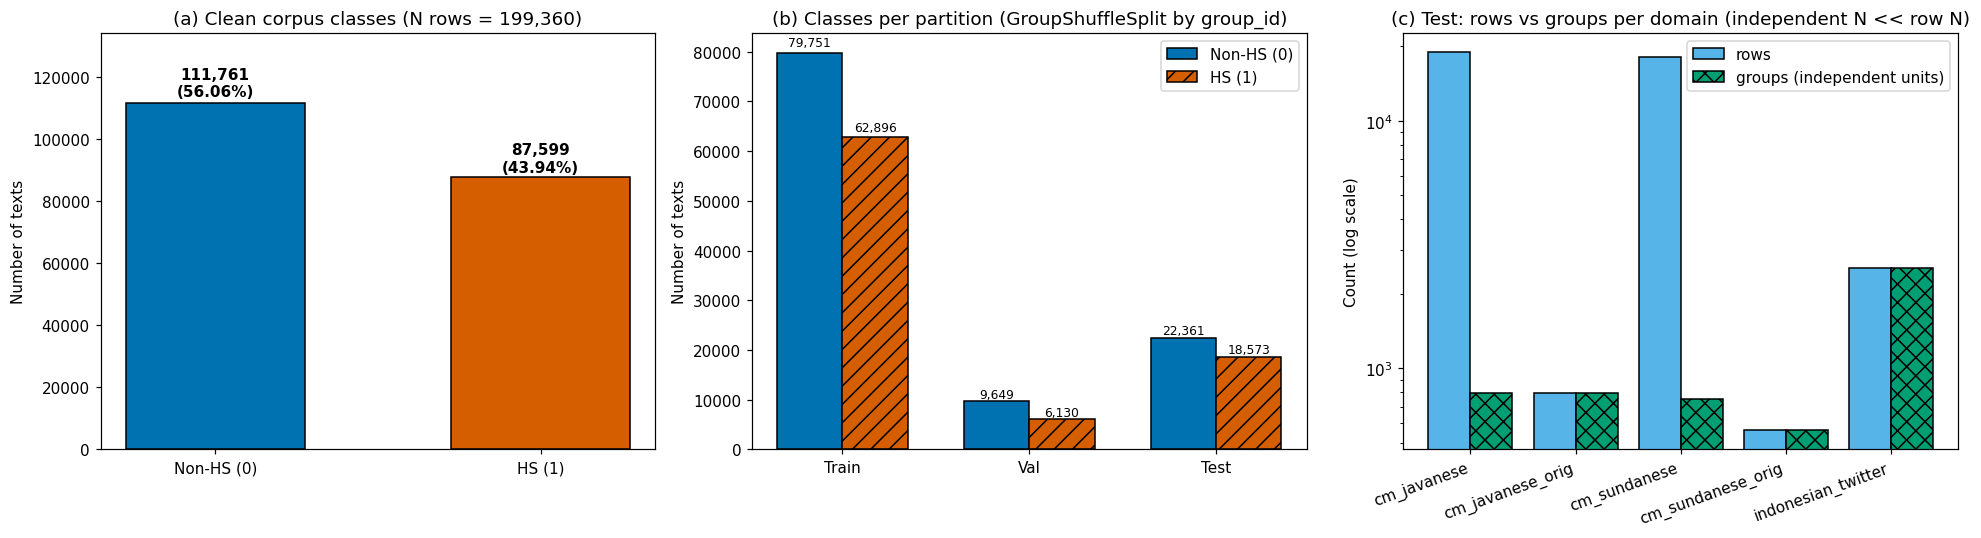

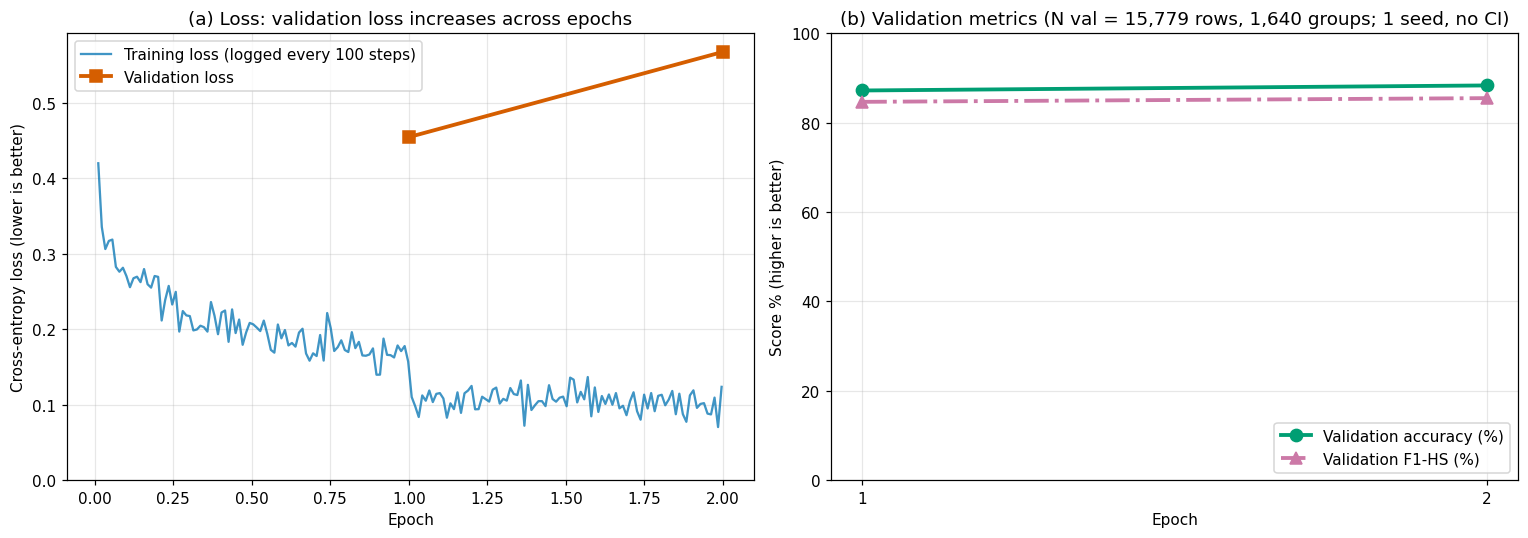

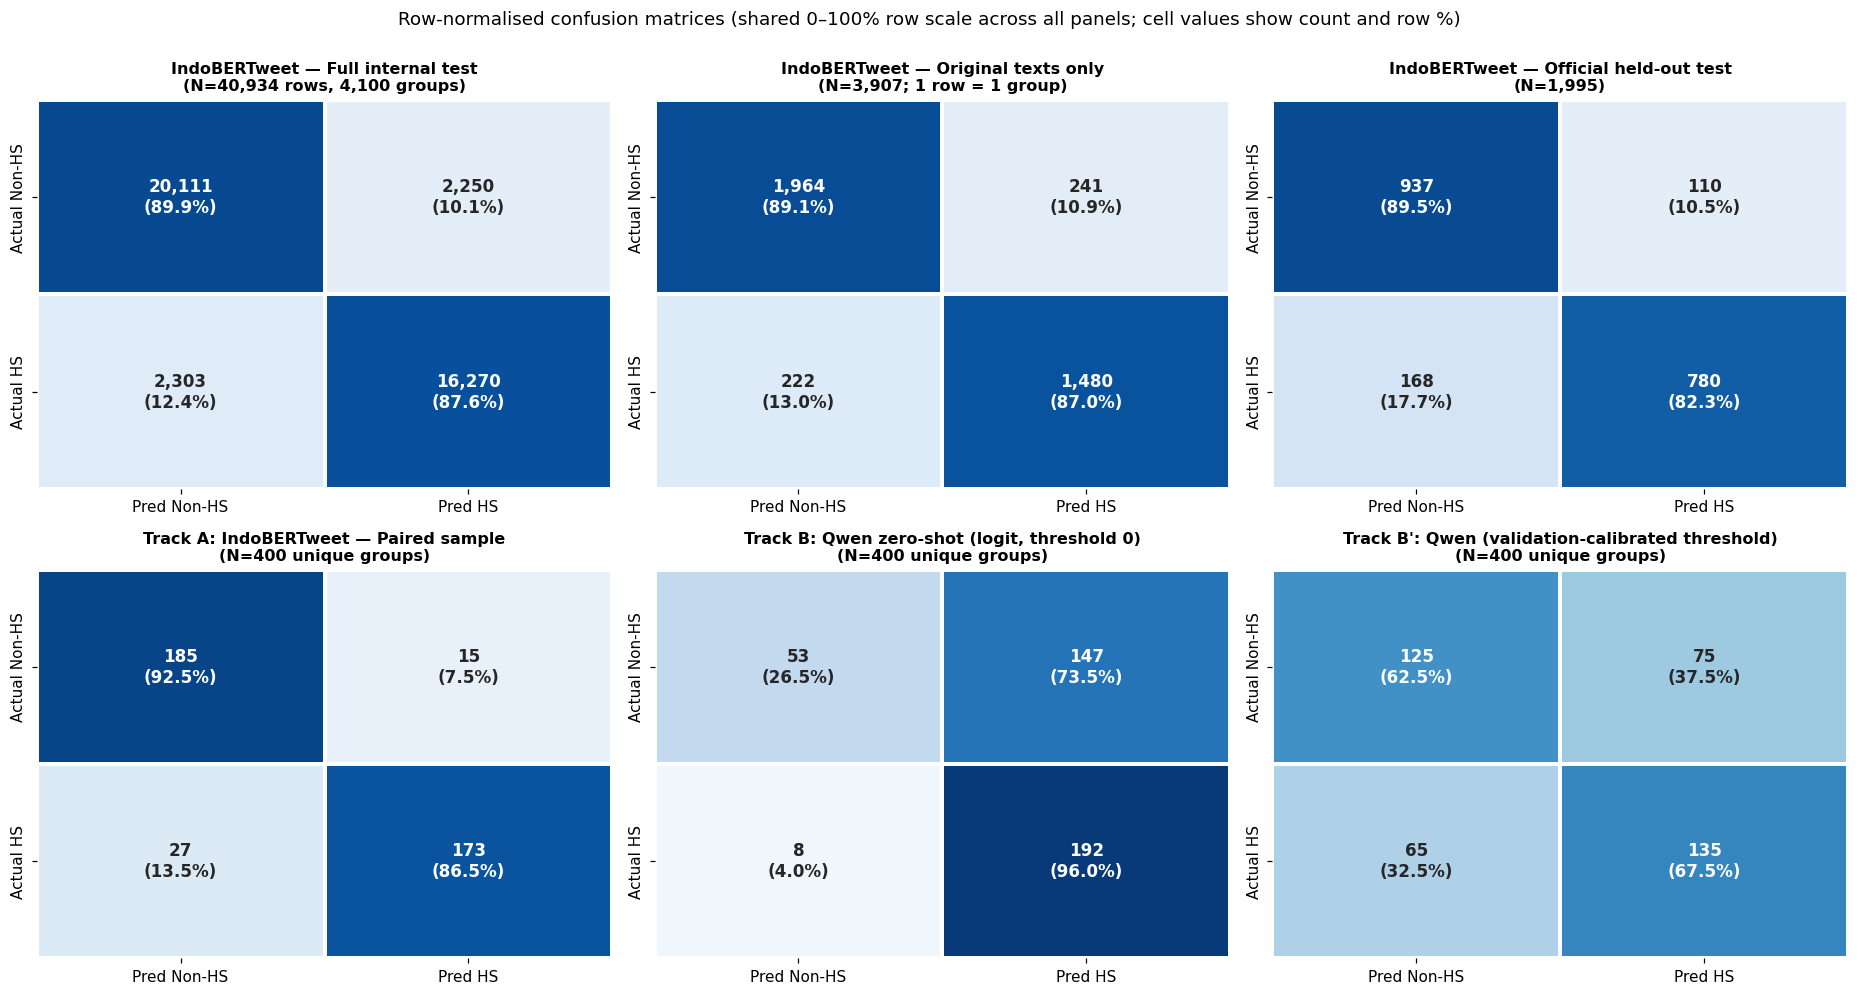

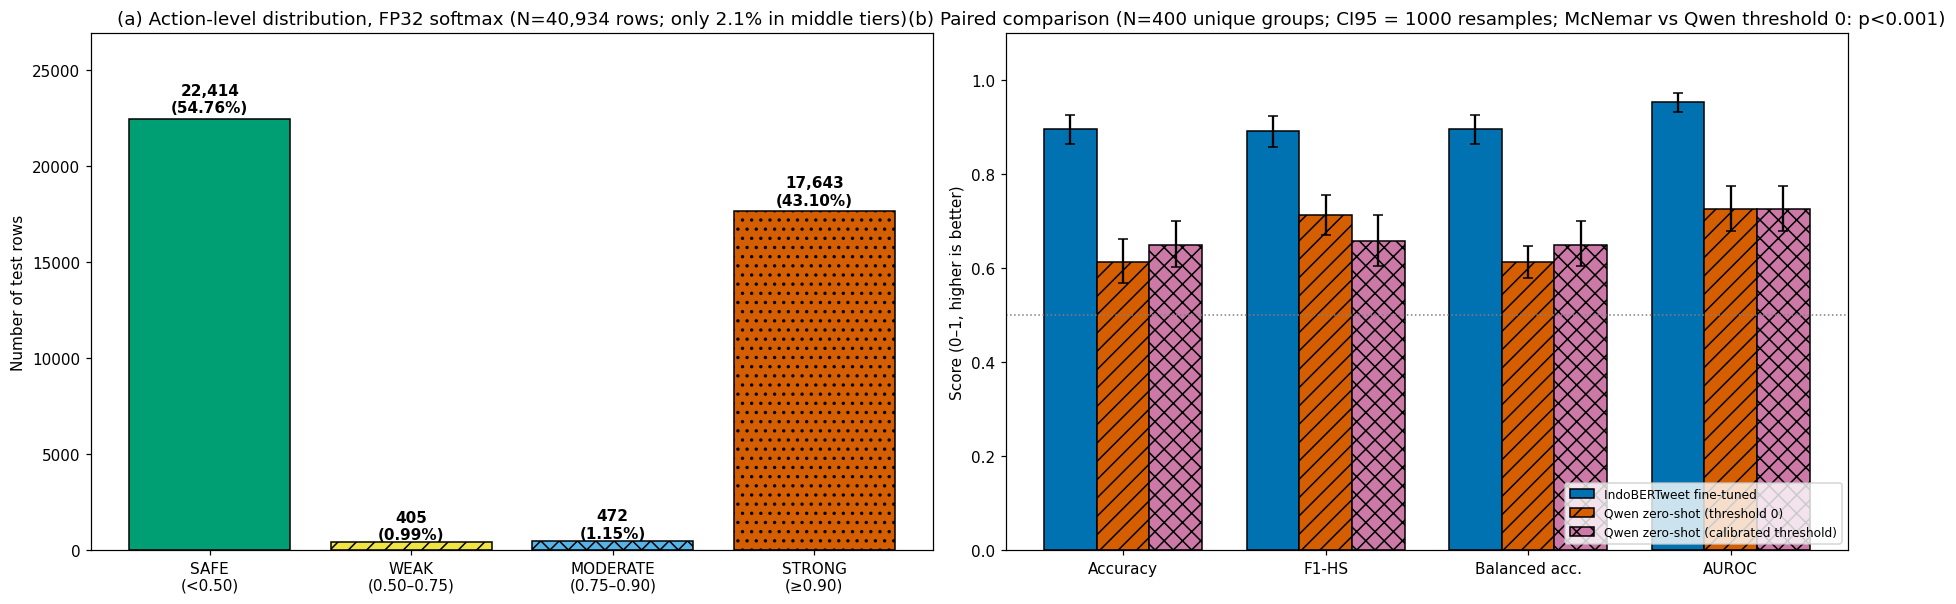

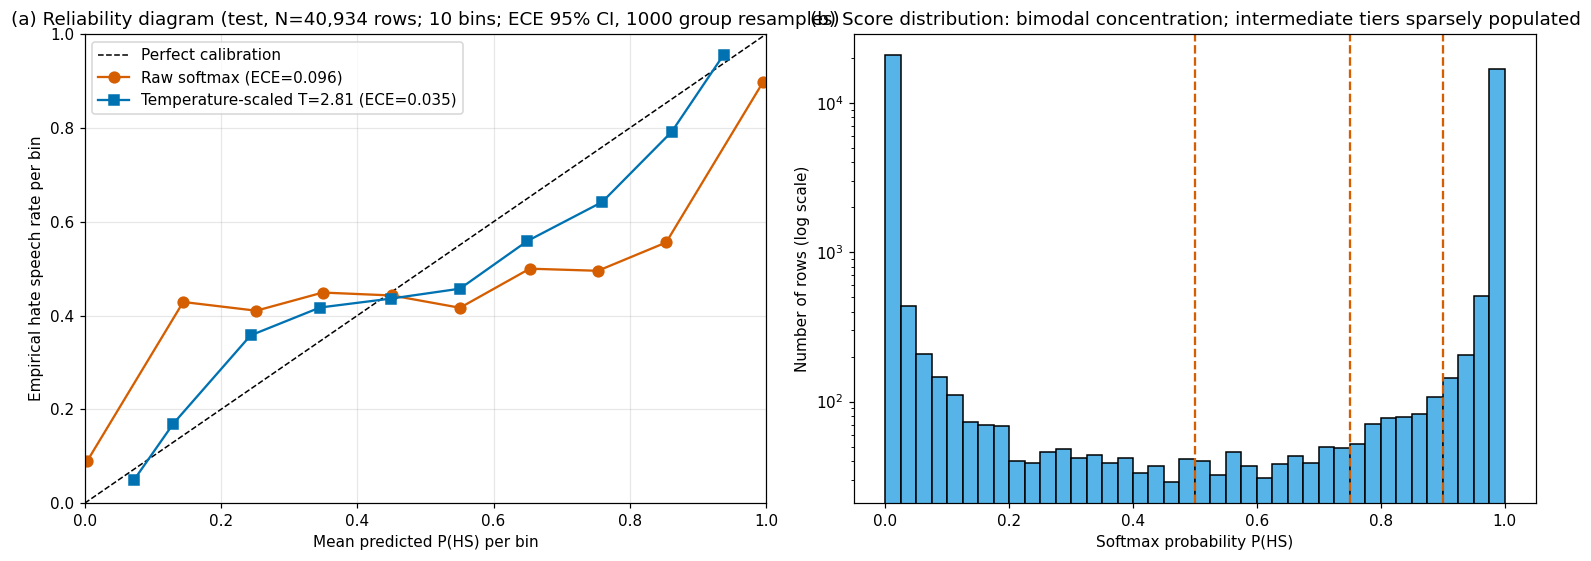

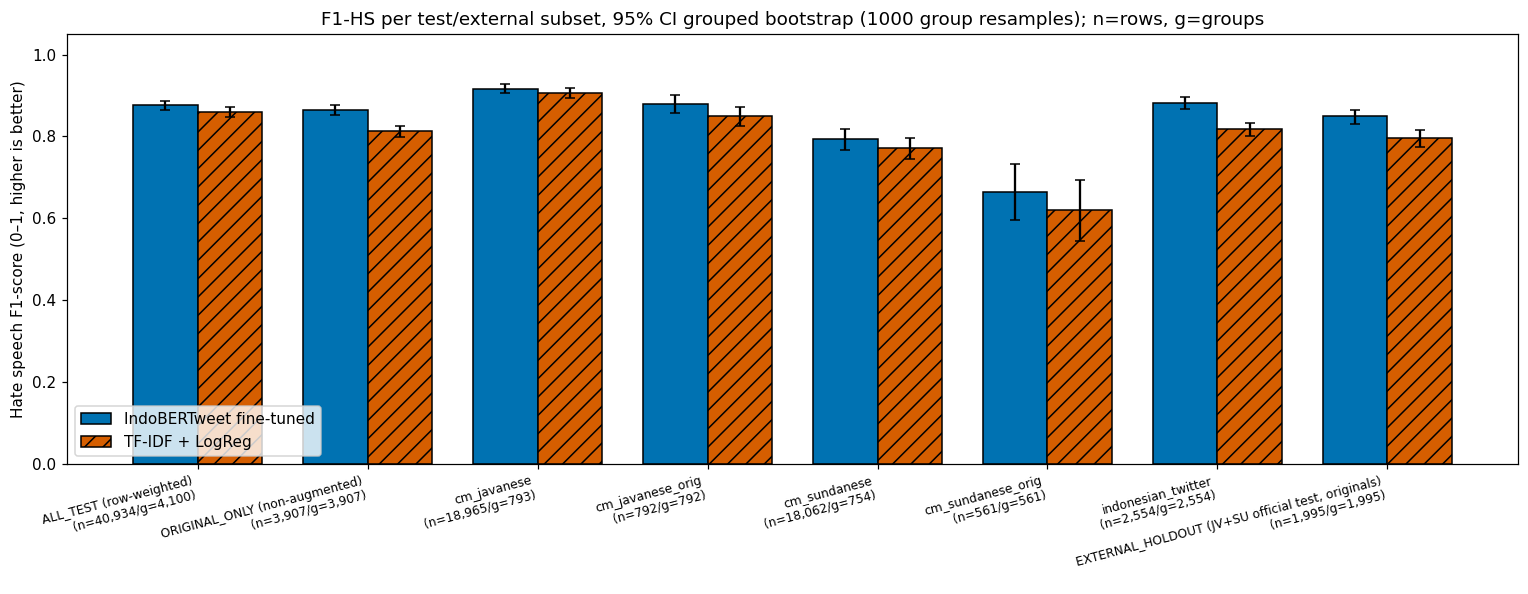

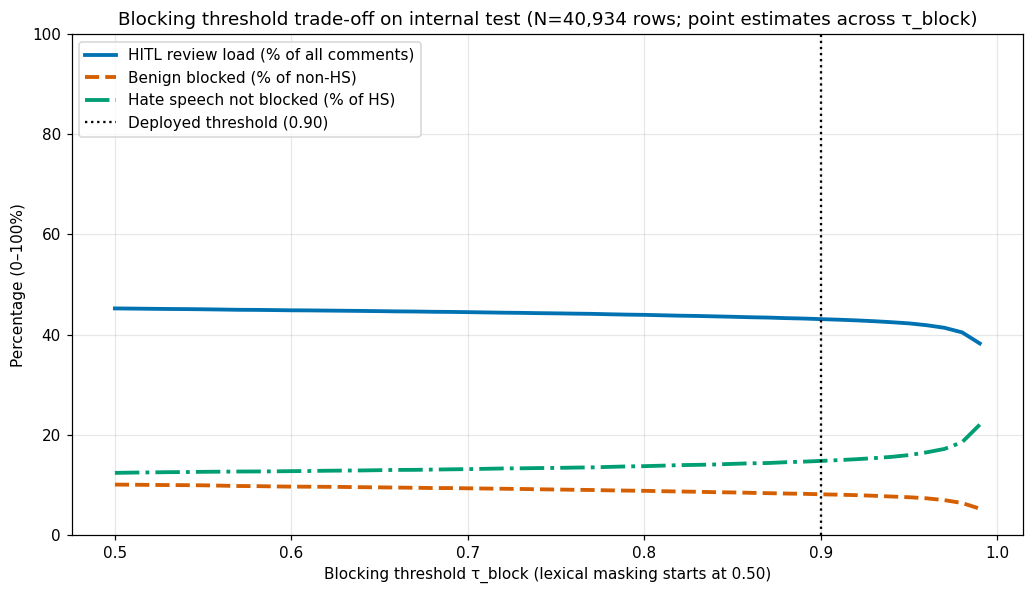

In [12]:
# CELL 12 — FIGURES 1–7 (values are taken directly from result objects; no hardcoded numbers)

import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams.update({"font.family": "sans-serif", "figure.dpi": 110, "savefig.dpi": 300})
OI = {"blue": "#0072B2", "orange": "#D55E00", "green": "#009E73", "pink": "#CC79A7", "yellow": "#F0E442", "sky": "#56B4E9"}
HATCH = ["", "//", "xx", ".."]
NB, NBA = EVAL_CONFIG["n_bootstrap"], EVAL_CONFIG["n_bootstrap_auc"]

def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight"); plt.show()

# Fig 1: class distribution, per partition, and row-vs-group comparison (N inflation)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
cc = df_all["HS"].value_counts().sort_index()
b = ax[0].bar(["Non-HS (0)", "HS (1)"], cc.values, color=[OI["blue"], OI["orange"]], edgecolor="black", width=0.55)
for r_, v in zip(b, cc.values): ax[0].text(r_.get_x()+r_.get_width()/2, v*1.01, f"{v:,}\n({v/cc.sum()*100:.2f}%)", ha="center", va="bottom", fontweight="bold")
ax[0].set_title(f"(a) Clean corpus classes (N rows = {len(df_all):,})"); ax[0].set_ylabel("Number of texts"); ax[0].set_ylim(0, cc.max()*1.2)
sp = {"Train": df_train, "Val": df_val, "Test": df_test}
x = np.arange(3); w = 0.35
for j, (lab, c, h) in enumerate([("Non-HS (0)", 0, ""), ("HS (1)", 1, "//")]):
    vals = [int((d["HS"] == c).sum()) for d in sp.values()]
    bb = ax[1].bar(x + (j-0.5)*w, vals, w, label=lab, color=[OI["blue"], OI["orange"]][j], edgecolor="black", hatch=h)
    for r_, v in zip(bb, vals): ax[1].text(r_.get_x()+r_.get_width()/2, v*1.01, f"{v:,}", ha="center", va="bottom", fontsize=8)
ax[1].set_xticks(x); ax[1].set_xticklabels(sp.keys()); ax[1].legend(); ax[1].set_ylabel("Number of texts")
ax[1].set_title("(b) Classes per partition (GroupShuffleSplit by group_id)")
ct = composition_table[composition_table["split"] == "test"].set_index("source_domain")
xx = np.arange(len(ct))
ax[2].bar(xx-0.2, ct["rows"], 0.4, label="rows", color=OI["sky"], edgecolor="black")
ax[2].bar(xx+0.2, ct["groups"], 0.4, label="groups (independent units)", color=OI["green"], edgecolor="black", hatch="xx")
ax[2].set_yscale("log"); ax[2].set_xticks(xx); ax[2].set_xticklabels([s.replace("codemixed_", "cm_") for s in ct.index], rotation=20, ha="right")
ax[2].set_ylabel("Count (log scale)"); ax[2].legend(); ax[2].set_title("(c) Test: rows vs groups per domain (independent N << row N)")
savefig("fig1_class_distribution_and_effective_n.png")

# Fig 2: training/validation curves (score axis 0–100, not cropped)
ev = [l for l in training_history_records if "eval_loss" in l]; tr = [l for l in training_history_records if "loss" in l and "eval_loss" not in l]
if len(ev) >= 1:
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    if tr: ax[0].plot([l["epoch"] for l in tr], [l["loss"] for l in tr], color=OI["blue"], alpha=.75, label="Training loss (logged every 100 steps)")
    ax[0].plot([l["epoch"] for l in ev], [l["eval_loss"] for l in ev], "s-", color=OI["orange"], ms=8, lw=2.5, label="Validation loss")
    ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Cross-entropy loss (lower is better)"); ax[0].set_ylim(bottom=0); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[0].set_title("(a) Loss: validation loss increases across epochs")
    ax[1].plot([l["epoch"] for l in ev], [l["eval_accuracy"]*100 for l in ev], "o-", color=OI["green"], lw=2.5, ms=8, label="Validation accuracy (%)")
    ax[1].plot([l["epoch"] for l in ev], [l["eval_f1"]*100 for l in ev], "^-.", color=OI["pink"], lw=2.5, ms=8, label="Validation F1-HS (%)")
    ax[1].set_ylim(0, 100); ax[1].set_xticks([l["epoch"] for l in ev]); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Score % (higher is better)")
    ax[1].legend(loc="lower right"); ax[1].grid(alpha=.3)
    ax[1].set_title(f"(b) Validation metrics (N val = {len(df_val):,} rows, {df_val['group_id'].nunique():,} groups; 1 seed, no CI)")
    savefig("fig2_training_validation_trends.png")

# Fig 3: confusion matrix (row percentages, same 0–100 scale)
def cm_panel(a, cm, title):
    pct = cm / np.maximum(cm.sum(1, keepdims=True), 1) * 100
    ann = np.array([[f"{cm[i,j]:,}\n({pct[i,j]:.1f}%)" for j in range(2)] for i in range(2)])
    sns.heatmap(pct, annot=ann, fmt="", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=a, linewidths=1.5, linecolor="white",
                xticklabels=["Pred Non-HS", "Pred HS"], yticklabels=["Actual Non-HS", "Actual HS"], annot_kws={"size": 11, "weight": "bold"})
    a.set_title(title, fontsize=10.5, fontweight="bold")
orig_d = df_test_eval[df_test_eval["is_original"]]
S = paired_primary["systems"]
fig, ax = plt.subplots(2, 3, figsize=(17, 9)); ax = ax.ravel()
cm_panel(ax[0], confusion_matrix(df_test_eval["y_true"], df_test_eval["y_pred_binary"], labels=[0, 1]), f"IndoBERTweet — Full internal test\n(N={len(df_test_eval):,} rows, {df_test_eval['group_id'].nunique():,} groups)")
cm_panel(ax[1], confusion_matrix(orig_d["y_true"], orig_d["y_pred_binary"], labels=[0, 1]), f"IndoBERTweet — Original texts only\n(N={len(orig_d):,}; 1 row = 1 group)")
cm_panel(ax[2], confusion_matrix(df_external_eval["y_true"], df_external_eval["y_pred_binary"], labels=[0, 1]), f"IndoBERTweet — Official held-out test\n(N={len(df_external_eval):,})")
cm_panel(ax[3], np.array(S["IndoBERTweet (fine-tuned)"]["confusion_matrix"]), f"Track A: IndoBERTweet — Paired sample\n(N={paired_primary['n']} unique groups)")
cm_panel(ax[4], np.array(S["Qwen zero-shot (logit, threshold 0)"]["confusion_matrix"]), f"Track B: Qwen zero-shot (logit, threshold 0)\n(N={paired_primary['n']} unique groups)")
cm_panel(ax[5], np.array(S["Qwen zero-shot (logit, calibrated validation threshold)"]["confusion_matrix"]), f"Track B': Qwen (validation-calibrated threshold)\n(N={paired_primary['n']} unique groups)")
fig.suptitle("Row-normalised confusion matrices (shared 0–100% row scale across all panels; cell values show count and row %)", y=1.0)
savefig("fig3_confusion_matrices.png")

# Fig 4: tier distribution + paired comparison (CI error bars)
fig, ax = plt.subplots(1, 2, figsize=(17, 5.6))
tiers = ["safe", "weak", "moderate", "strong"]
cnt = [int((df_test_eval["guardrail_level"] == t).sum()) for t in tiers]
bars = ax[0].bar([f"SAFE\n(<0.50)", "WEAK\n(0.50–0.75)", "MODERATE\n(0.75–0.90)", "STRONG\n(≥0.90)"], cnt,
                 color=[OI["green"], OI["yellow"], OI["sky"], OI["orange"]], edgecolor="black", hatch=None)
for bar_, h_, v in zip(bars, HATCH, cnt): bar_.set_hatch(h_); ax[0].text(bar_.get_x()+bar_.get_width()/2, v*1.01, f"{v:,}\n({v/len(df_test_eval)*100:.2f}%)", ha="center", va="bottom", fontweight="bold")
ax[0].set_ylim(0, max(cnt)*1.2); ax[0].set_ylabel("Number of test rows")
ax[0].set_title(f"(a) Action-level distribution, FP32 softmax (N={len(df_test_eval):,} rows; only {(cnt[1]+cnt[2])/len(df_test_eval)*100:.1f}% in middle tiers)")
sysn = ["IndoBERTweet (fine-tuned)", "Qwen zero-shot (logit, threshold 0)", "Qwen zero-shot (logit, calibrated validation threshold)"]
labs = ["IndoBERTweet\nfine-tuned", "Qwen zero-shot\n(threshold 0)", "Qwen zero-shot\n(calibrated threshold)"]
mets = [("accuracy", "Accuracy"), ("f1", "F1-HS"), ("balanced_accuracy", "Balanced acc."), ("auroc", "AUROC")]
w = 0.26
for i, (sn, col, h) in enumerate(zip(sysn, [OI["blue"], OI["orange"], OI["pink"]], HATCH)):
    vals = [S[sn][k]["point"] for k, _ in mets]
    err = [[S[sn][k]["point"]-S[sn][k]["lo"] for k, _ in mets], [S[sn][k]["hi"]-S[sn][k]["point"] for k, _ in mets]]
    ax[1].bar(np.arange(4)+(i-1)*w, vals, w, yerr=err, capsize=3, label=labs[i].replace("\n", " "), color=col, edgecolor="black", hatch=h)
ax[1].set_xticks(np.arange(4)); ax[1].set_xticklabels([m[1] for m in mets]); ax[1].set_ylim(0, 1.1); ax[1].axhline(0.5, color="gray", ls=":", lw=1)
ax[1].set_ylabel("Score (0–1, higher is better)"); ax[1].legend(loc="lower right", fontsize=8)
pv = paired_primary["vs_indobertweet"]["Qwen zero-shot (logit, threshold 0)"]["p_value_formatted"]
ax[1].set_title(f"(b) Paired comparison (N={paired_primary['n']} unique groups; CI95 = {NB} resamples; McNemar vs Qwen threshold 0: p{'' if pv.startswith('<') else '='}{pv})")
savefig("fig4_guardrail_tiers_and_llm_comparison.png")

# Fig 5: reliability + score histogram
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
for rt, col, mk, lab in [(reliab_raw, OI["orange"], "o", f"Raw softmax (ECE={CALIBRATION['raw']['ece']['point']:.3f})"),
                         (reliab_ts, OI["blue"], "s", f"Temperature-scaled T={T_OPT:.2f} (ECE={CALIBRATION['temperature_scaled']['ece']['point']:.3f})")]:
    ax[0].plot(rt["mean_confidence"], rt["empirical_hs_rate"], mk + "-", color=col, label=lab, ms=7)
ax[0].set_xlim(0, 1); ax[0].set_ylim(0, 1); ax[0].set_xlabel("Mean predicted P(HS) per bin"); ax[0].set_ylabel("Empirical hate speech rate per bin"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[0].set_title(f"(a) Reliability diagram (test, N={len(y_te):,} rows; 10 bins; ECE 95% CI, {NB} group resamples)")
ax[1].hist(p_raw, bins=40, color=OI["sky"], edgecolor="black"); ax[1].set_yscale("log")
for t_ in [0.5, 0.75, 0.9]: ax[1].axvline(t_, color=OI["orange"], ls="--")
ax[1].set_xlabel("Softmax probability P(HS)"); ax[1].set_ylabel("Number of rows (log scale)"); ax[1].set_title("(b) Score distribution: bimodal concentration; intermediate tiers sparsely populated")
savefig("fig5_calibration_and_score_distribution.png")

# Fig 6: F1 per subset, IndoBERTweet vs TF-IDF (CI95)
sub = main_df[main_df["subset"].isin(baseline_df["subset"]) & (main_df["weighting"] == "row")].reset_index(drop=True)
sub = sub.drop_duplicates("subset").set_index("subset").loc[baseline_df["subset"]]
fig, ax = plt.subplots(figsize=(14, 5.5)); xx = np.arange(len(sub)); w = 0.38
for i, (dfm, lab, col, h) in enumerate([(sub, "IndoBERTweet fine-tuned", OI["blue"], ""), (baseline_df.set_index("subset"), "TF-IDF + LogReg", OI["orange"], "//")]):
    v = dfm["f1"].to_numpy(); lo = dfm["f1_lo"].to_numpy(); hi = dfm["f1_hi"].to_numpy()
    ax.bar(xx+(i-.5)*w, v, w, yerr=[v-lo, hi-v], capsize=3, label=lab, color=col, edgecolor="black", hatch=h)
ax.set_xticks(xx); ax[1 if False else 0 if False else None] if False else None
ax.set_xticklabels([f"{s_.replace('domain:','').replace('codemixed_','cm_')}\n(n={int(sub.loc[s_,'n_rows']):,}/g={int(sub.loc[s_,'n_groups']):,})" for s_ in sub.index], fontsize=8, rotation=15, ha="right")
ax.set_ylim(0, 1.05); ax.set_ylabel("Hate speech F1-score (0–1, higher is better)"); ax.legend(loc="lower left")
ax.set_title(f"F1-HS per test/external subset, 95% CI grouped bootstrap ({NB} group resamples); n=rows, g=groups")
savefig("fig6_f1_by_subset_vs_baseline.png")

# Fig 7: block-threshold trade-off
fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.plot(sweep_df["tau_block"], sweep_df["HITL_load_pct"], "-", color=OI["blue"], lw=2.5, label="HITL review load (% of all comments)")
ax.plot(sweep_df["tau_block"], sweep_df["benign_blocked_pct"], "--", color=OI["orange"], lw=2.5, label="Benign blocked (% of non-HS)")
ax.plot(sweep_df["tau_block"], sweep_df["hs_not_blocked_pct"], "-.", color=OI["green"], lw=2.5, label="Hate speech not blocked (% of HS)")
ax.axvline(0.90, color="black", ls=":", label="Deployed threshold (0.90)"); ax.set_ylim(0, 100)
ax.set_xlabel("Blocking threshold τ_block (lexical masking starts at 0.50)"); ax.set_ylabel("Percentage (0–100%)"); ax.grid(alpha=.3); ax.legend()
ax.set_title(f"Blocking threshold trade-off on internal test (N={len(y_te):,} rows; point estimates across τ_block)")
savefig("fig7_block_threshold_tradeoff.png")

## **11. Artifact Freezing, Parity Reference, Separate-Process Smoke Test, and Single Source of Truth**



This cell is used to ensure all experimental artifacts are in a final, documented state and can be consistently reproduced.



In `verify_frozen` mode, the system conducts artifact integrity verification using SHA-256 and generates supporting documentation necessary for experiment reproducibility. This process includes creating `experiment_manifest_addendum.json`, which contains supplementary information such as SHA-256 hashes of shared modules and bundles, checksums of all output files, library versions used, data provenance, model details, Hub licenses, numerical parity check results, and an audit summary.



As a reference for inference validation, this cell generates `inference_parity_reference.csv`, containing 200 stratified text samples based on tier alongside reference FP32 probabilities. This file serves as a baseline to verify the consistency of inference results across the application and components utilizing the same artifacts.



To ensure artifacts can operate independently, `smoke_test_standalone.py` is executed in a fresh Python process on CPU without relying on the notebook state. This test verifies that the model and all supporting components can be loaded and executed directly from artifacts saved on disk.



All final numbers used in the paper are consolidated into `RESULTS_SINGLE_SOURCE.json` as the single source of truth for experimental results. This file acts as the central hub for documenting metrics, tables, and evaluation outputs produced during the experiment.



After all verification processes are complete, artifacts are synchronized to Drive, making all experiment result files available for reproduction, validation, and research documentation purposes.



> To run verification in another environment, install dependencies via `pip install -r requirements_frozen.txt`, then run `python smoke_test_standalone.py <artifact_dir>` according to the instructions provided in the README.

In [13]:
# CELL 13 — ARTIFACT FREEZING, MANIFEST ADDENDUM, PARITY REFERENCE, SMOKE TEST, SINGLE SOURCE OF TRUTH

def sanitize(o):
    """Convert numpy/pandas → pure JSON; NaN/inf → None."""
    if isinstance(o, dict):   return {str(k): sanitize(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [sanitize(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)):
        return None if (np.isnan(o) or np.isinf(o)) else float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, (pd.Timestamp,)): return str(o)
    return o

def dump_json(obj, path):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(sanitize(obj), f, indent=2, ensure_ascii=False)

local_model_dir = os.path.join(OUTPUT_DIR, "model_hate_speech_final")
run_ts = datetime.now(ZoneInfo("Asia/Jakarta")).isoformat()

# 1. Model/manifest/bundle artifacts
if not RETRAIN:
    src_parent = os.path.dirname(EXISTING_CHECKPOINT)
    if os.path.abspath(src_parent) != os.path.abspath(OUTPUT_DIR):
        shutil.copytree(EXISTING_CHECKPOINT, local_model_dir, dirs_exist_ok=True)          # copy byte-for-byte, DO NOT re-save
        for fn in ["experiment_manifest.json", "config.json", "preprocessing_bundle.joblib", "training_history.json"]:
            if os.path.isfile(os.path.join(src_parent, fn)):
                shutil.copy2(os.path.join(src_parent, fn), os.path.join(OUTPUT_DIR, fn))
        for fn in ["test_predictions.csv", "external_test_predictions.csv"]:                # archive original run predictions
            if os.path.isfile(os.path.join(src_parent, fn)):
                shutil.copy2(os.path.join(src_parent, fn), os.path.join(OUTPUT_DIR, fn.replace(".csv", "_legacy_trainer.csv")))
    wf = "model.safetensors" if os.path.isfile(os.path.join(local_model_dir, "model.safetensors")) else "pytorch_model.bin"
    with open(os.path.join(OUTPUT_DIR, "experiment_manifest.json"), "r", encoding="utf-8") as f:
        frozen_manifest = json.load(f)
    trusted_sha256 = frozen_manifest["trusted_model_sha256"]
    assert sha256_file(os.path.join(local_model_dir, wf)) == trusted_sha256, "FATAL: copied weights != trusted_model_sha256!"
    print(f"✅ Frozen artifacts copied & verified byte-for-byte. Model weights SHA-256 = {trusted_sha256}")
else:
    os.makedirs(local_model_dir, exist_ok=True)
    model.to(torch.float32); model.save_pretrained(local_model_dir); tokenizer.save_pretrained(local_model_dir)
    wf = "model.safetensors" if os.path.isfile(os.path.join(local_model_dir, "model.safetensors")) else "pytorch_model.bin"
    trusted_sha256 = sha256_file(os.path.join(local_model_dir, wf))
    CONFIG["trusted_model_sha256"] = trusted_sha256
    CONFIG["preprocessing_parity_hash"] = PREPROCESSING_PARITY_HASH
    CONFIG["preprocessing_parity_samples"] = PREPROCESSING_PARITY_SAMPLES
    joblib.dump({"kamus_gabungan": kamus_gabungan, "lexicon_sensitif": LEXICON_SENSITIF_4_BAHASA, "config": CONFIG},
                os.path.join(OUTPUT_DIR, "preprocessing_bundle.joblib"))
    dump_json(CONFIG, os.path.join(OUTPUT_DIR, "config.json"))
    dump_json(training_history_records, os.path.join(OUTPUT_DIR, "training_history.json"))
    frozen_manifest = {
        "run_id": datetime.now(ZoneInfo("Asia/Jakarta")).strftime("run_%Y%m%d_%H%M%S"), "timestamp_wib": run_ts,
        "trained_in_this_run": True, "model_checkpoint_base": CONFIG["model_checkpoint"],
        "training_config": {k: CONFIG.get(k) for k in ["model_checkpoint", "max_length", "padding_strategy", "seed", "num_epochs", "batch_size", "learning_rate", "weight_decay"]},
        "weight_filename": wf, "trusted_model_sha256": trusted_sha256, "preprocessing_parity_hash": PREPROCESSING_PARITY_HASH,
        "split_fingerprints": SPLIT_FINGERPRINTS, "library_versions": ENVIRONMENT}
    dump_json(frozen_manifest, os.path.join(OUTPUT_DIR, "experiment_manifest.json"))

# 2. Official FP32 predictions & tables
df_val_eval.to_csv(os.path.join(OUTPUT_DIR, "val_predictions.csv"), index=False)
df_test_eval.to_csv(os.path.join(OUTPUT_DIR, "test_predictions.csv"), index=False)
df_external_eval.to_csv(os.path.join(OUTPUT_DIR, "external_test_predictions.csv"), index=False)
dump_json(uncertainty_report, os.path.join(OUTPUT_DIR, "test_metrics_summary.json"))
thr_rows = []
for tau in (0.50, 0.75, 0.90):
    yh = (p_raw >= tau).astype(int); pr, rc, f1_, _ = precision_recall_fscore_support(y_te, yh, average="binary", zero_division=0)
    thr_rows.append({"threshold_tau": tau, "accuracy": accuracy_score(y_te, yh), "precision_hs": pr, "recall_hs": rc, "f1_hs": f1_,
                     "false_positive_count": int(((y_te == 0) & (yh == 1)).sum()), "false_negative_count": int(((y_te == 1) & (yh == 0)).sum())})
pd.DataFrame(thr_rows).to_csv(os.path.join(OUTPUT_DIR, "threshold_analysis_results.csv"), index=False)
dump_json(training_history_records, os.path.join(OUTPUT_DIR, "training_history.json")) if RETRAIN else None

# 3. Parity reference for the App (200 raw texts, stratified by tier, FP32 reference)
rng_ref = np.random.default_rng(CONFIG["seed"])
ref_parts = []
for t in ["safe", "weak", "moderate", "strong"]:
    pool = df_test_eval[df_test_eval["guardrail_level"] == t]
    ref_parts.append(pool.iloc[rng_ref.choice(len(pool), size=min(50, len(pool)), replace=False)])
ref_df = pd.concat(ref_parts)[["Tweet", "source_domain", "y_true", "p_hate_speech", "guardrail_level"]].reset_index(drop=True)
ref_df["reference_device"] = str(device); ref_df["reference_torch"] = torch.__version__
ref_df.to_csv(os.path.join(OUTPUT_DIR, "inference_parity_reference.csv"), index=False)

# 4. Standalone smoke test (separate Python process, independent of notebook state)
SMOKE_SOURCE = r'''
"""smoke_test_standalone.py — loads artifacts ONLY from files; does not depend on notebook state.
Usage: python smoke_test_standalone.py <artifact_dir> [cpu|cuda]   (exit code 0 = PASS)"""
import sys, os, json, hashlib, importlib.util
import numpy as np, pandas as pd, joblib, torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

ART = sys.argv[1]; DEV = sys.argv[2] if len(sys.argv) > 2 else "cpu"
TOL = 1e-3   # cross-device numerical tolerance (GPU FP32 vs CPU FP32)
def sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for c in iter(lambda: f.read(8 * 1024 * 1024), b""): h.update(c)
    return h.hexdigest()
def fail(msg): print("❌ SMOKE TEST FAILED:", msg); sys.exit(1)

add = json.load(open(os.path.join(ART, "experiment_manifest_addendum.json"), encoding="utf-8"))
man = json.load(open(os.path.join(ART, "experiment_manifest.json"), encoding="utf-8"))
core_path = os.path.join(ART, "hateguard_core.py")
if sha(core_path) != add["core_sha256"]: fail("hateguard_core.py SHA-256 does not match the addendum")
spec = importlib.util.spec_from_file_location("hateguard_core", core_path); core = importlib.util.module_from_spec(spec); sys.modules["hateguard_core"] = core; spec.loader.exec_module(core)
mdir = os.path.join(ART, "model_hate_speech_final")
wf = "model.safetensors" if os.path.isfile(os.path.join(mdir, "model.safetensors")) else "pytorch_model.bin"
if sha(os.path.join(mdir, wf)) != man["trusted_model_sha256"]: fail("Model weights SHA-256 does not match trusted_model_sha256")
bpath = os.path.join(ART, "preprocessing_bundle.joblib")
if sha(bpath) != add["bundle_sha256"]: fail("Bundle SHA-256 does not match the addendum (do not joblib.load an unverified file)")
bundle = joblib.load(bpath); cfg = bundle["config"]; kamus = bundle["kamus_gabungan"]
ph = hashlib.sha256("||".join(core.clean_text(s, kamus) for s in cfg["preprocessing_parity_samples"]).encode("utf-8")).hexdigest()
if ph != cfg["preprocessing_parity_hash"]: fail("Preprocessing parity hash mismatch")
tok = AutoTokenizer.from_pretrained(mdir); model = AutoModelForSequenceClassification.from_pretrained(mdir).to(DEV, dtype=torch.float32).eval()
ref = pd.read_csv(os.path.join(ART, "inference_parity_reference.csv"))
texts = [core.clean_text(t, kamus) for t in ref["Tweet"].astype(str)]
run = lambda: core.softmax_hs(core.logits_fp32(texts, tok, model, torch.device(DEV), cfg["max_length"], cfg["padding_strategy"]))
p1, p2 = run(), run()
if not np.array_equal(p1, p2): fail("Inference is not deterministic")
diff = np.abs(p1 - ref["p_hate_speech"].to_numpy()); thr = cfg["guardrail_thresholds"]
lv_new = np.array([core.prob_to_level(float(p), thr) for p in p1]); lv_ref = ref["guardrail_level"].to_numpy()
near = np.min(np.abs(p1[:, None] - np.array([thr["safe_max"], thr["weak_max"], thr["moderate_max"]])[None, :]), axis=1) < TOL
bad_flips = int(((lv_new != lv_ref) & ~near).sum())
if diff.max() > TOL: fail(f"Maximum probability difference {diff.max():.2e} > {TOL}")
if bad_flips: fail(f"{bad_flips} tier flips outside the threshold tolerance zone")
out = {"status": "PASS", "device": DEV, "n": int(len(ref)), "max_abs_diff": float(diff.max()), "mean_abs_diff": float(diff.mean()),
       "tier_flips_within_tolerance_zone": int((lv_new != lv_ref).sum()), "tolerance": TOL}
print("✅ SMOKE TEST PASSED:", json.dumps(out)); json.dump(out, open(os.path.join(ART, "smoke_test_result.json"), "w"))
'''
SMOKE_PATH = os.path.join(OUTPUT_DIR, "smoke_test_standalone.py")
with open(SMOKE_PATH, "w", encoding="utf-8") as f:
    f.write(SMOKE_SOURCE)

# 5. requirements_frozen.txt
with open(os.path.join(OUTPUT_DIR, "requirements_frozen.txt"), "w", encoding="utf-8") as f:
    f.write(subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout)

# 6. RESULTS_SINGLE_SOURCE.json: the single source of truth for all paper figures
def row_of(df, name, w="row"):
    r = df[(df["subset"] == name) & (df["weighting"] == w)].iloc[0].to_dict(); return r
LIMITATIONS = [
    "Augmentation (±90% of test rows) is LLM/automatically generated and assumed to preserve labels; it has not been human-verified.",
    "The independent test unit consists of only 4,100 groups (3,907 original texts); the number of rows inflates the sample size. Use ORIGINAL_ONLY figures & group-based CIs.",
    "External hold-out = official test split from the same code-mixed dataset (same generation process), JV/SU only, original texts only; not a new domain. No external data is available for Indonesian Twitter.",
    "Contradictory text cleaning uses labels from the entire corpus before splitting (which may make the test set 'cleaner' than real-world data).",
    "One seed, one hyperparameter configuration, no tuning: variation across seeds has not been measured.",
    "Normalization ablation is performed during inference on frozen weights; training-time ablation was not conducted.",
    "The corpus HS prevalence ≈45% is far above real-world prevalence; prevalence projections depend on the pure prior-shift assumption.",
    "Softmax scores are poorly calibrated (overconfident; validation loss increases); thresholds of 0.50/0.75/0.90 are operational thresholds, not linguistic severity levels.",
    "LLM comparison includes one 1.5B model, one prompt, no few-shot; it does not represent the general zero-shot capabilities of LLMs. Qwen HITL draft quality was not evaluated.",
    "Texts > max_length (128 tokens) are truncated; the remaining text is not evaluated (see truncation_audit).",
    "Exploratory near-duplicate audit (distinctive-token cosine); not proof of the absence of semantic leakage.",
    "Language coverage: Indonesian, informal English, Javanese, Sundanese; no evidence for other languages/dialects/platforms. Labels come from source dataset annotations; annotator bias was not audited.",
]
RESULTS = {
    "generated_at_wib": run_ts, "run_mode": RUN_MODE, "trained_in_this_run": TRAINED_IN_THIS_RUN,
    "n_bootstrap_groups_resamples": EVAL_CONFIG["n_bootstrap"], "precision_mode": "fp32 (hateguard_core.logits_fp32)",
    "data": {"corpus_rows": len(df_all), "train_rows": len(df_train), "val_rows": len(df_val), "test_rows": len(df_test),
             "test_groups": int(df_test["group_id"].nunique()), "external_rows": len(df_external_test),
             "class_balance_corpus_hs": float(df_all["HS"].mean()), "composition": composition_table.to_dict(orient="records"),
             "contradictory_rows_removed_by_domain": contra_removed_by_domain, "fingerprints": SPLIT_FINGERPRINTS},
    "main_table": main_df.to_dict(orient="records"),
    "baseline_tfidf": baseline_df.to_dict(orient="records"), "paired_delta_vs_tfidf": delta_df.to_dict(orient="records"),
    "headline_original_only": row_of(main_df, "ORIGINAL_ONLY (non-augmented)"),
    "headline_all_test_row_weighted": row_of(main_df, "ALL_TEST (row-weighted)"),
    "headline_all_test_group_weighted": row_of(main_df, "ALL_TEST (group-weighted)", "group"),
    "calibration": CALIBRATION, "tier_composition": tier_df.to_dict(orient="records"),
    "policy_ablation": policy_df.to_dict(orient="records"), "prevalence_projection": prevalence_df.to_dict(orient="records"),
    "ablation_inference_normalization": ablation_norm_df.to_dict(orient="records"),
    "error_rates_by_domain": domain_err_df.to_dict(orient="records"), "lexicon_associated_fp": lexicon_df.to_dict(orient="records"),
    "error_by_length": length_df.to_dict(orient="records"),
    "llm_comparison_primary": paired_primary, "llm_comparison_legacy_n50": paired_legacy, "llm_calibration": LLM_CALIB,
    "numerical_parity_vs_legacy_trainer": PARITY_LEGACY, "truncation_audit": TRUNCATION_AUDIT, "near_duplicate_audit": NEAR_DUP_AUDIT,
    "limitations": LIMITATIONS}
dump_json(RESULTS, os.path.join(OUTPUT_DIR, "RESULTS_SINGLE_SOURCE.json"))

# 7. Manifest addendum (non-destructive)
def file_hashes(root, subdirs=("", "results", "figures")):
    out = {}
    for sd in subdirs:
        d = os.path.join(root, sd)
        for fn in sorted(os.listdir(d)):
            p = os.path.join(d, fn)
            if os.path.isfile(p) and fn not in ("experiment_manifest_addendum.json", "smoke_test_result.json"):
                out[os.path.join(sd, fn) if sd else fn] = sha256_file(p)
    return out

def write_addendum(smoke=None):
    add = {
        "schema_version": "addendum-1", "created_at_wib": run_ts, "run_mode": RUN_MODE, "trained_in_this_run": TRAINED_IN_THIS_RUN,
        "frozen_manifest_sha256": sha256_file(os.path.join(OUTPUT_DIR, "experiment_manifest.json")),
        "trusted_model_sha256": trusted_sha256, "weight_filename": wf,
        "bundle_sha256": sha256_file(os.path.join(OUTPUT_DIR, "preprocessing_bundle.joblib")),
        "core_sha256": CORE_SHA256, "core_version": core.CORE_VERSION, "policy_version": core.POLICY_VERSION,
        "preprocessing_parity_hash": PREPROCESSING_PARITY_HASH,
        "provenance_check_message": PROVENANCE_MESSAGE,
        "training_config_documented": {k: CONFIG.get(k) for k in ["model_checkpoint", "max_length", "padding_strategy", "seed", "num_epochs", "batch_size", "learning_rate", "weight_decay"]},
        "training_config_note": ("The frozen manifest does not contain training_config; these values are matched against the config.json frozen artifact "
                                 "(verified in Cell 4) and have NOT been proven by raw training logs." if not RETRAIN else "Trained in this run."),
        "eval_config": EVAL_CONFIG, "environment": ENVIRONMENT, "provenance_meta": PROVENANCE_META,
        "split_fingerprints": SPLIT_FINGERPRINTS, "numerical_parity_vs_legacy_trainer": PARITY_LEGACY,
        "temperature_T_validation_fit": T_OPT, "output_files_sha256": file_hashes(OUTPUT_DIR), "smoke_test": smoke}
    dump_json(add, os.path.join(OUTPUT_DIR, "experiment_manifest_addendum.json"))
write_addendum()

proc = subprocess.run([sys.executable, SMOKE_PATH, OUTPUT_DIR, "cpu"], capture_output=True, text=True)
print(proc.stdout[-1500:], proc.stderr[-800:])
assert proc.returncode == 0, "Standalone smoke test FAILED — artifacts must not be frozen."
SMOKE_RESULT = json.load(open(os.path.join(OUTPUT_DIR, "smoke_test_result.json")))
write_addendum(SMOKE_RESULT)

# 8. Final verification & freezing invariants
add_final = json.load(open(os.path.join(OUTPUT_DIR, "experiment_manifest_addendum.json")))
assert sha256_file(os.path.join(local_model_dir, wf)) == trusted_sha256
if not RETRAIN:
    assert add_final["frozen_manifest_sha256"] == sha256_file(os.path.join(os.path.dirname(EXISTING_CHECKPOINT), "experiment_manifest.json")) \
        or os.path.abspath(os.path.dirname(EXISTING_CHECKPOINT)) == os.path.abspath(OUTPUT_DIR), "FATAL: frozen manifest has changed!"
print(f"✅ Freezing invariants passed | model weights SHA-256 = {trusted_sha256}")

# 9. Sync to Drive without touching frozen artifacts
if os.path.exists("/content/drive/MyDrive"):
    ign = ["hf_checkpoints"] + ([] if RETRAIN else ["model_hate_speech_final", "experiment_manifest.json", "preprocessing_bundle.joblib", "config.json"])
    shutil.copytree(OUTPUT_DIR, CONFIG["drive_artifact_dir"], dirs_exist_ok=True, ignore=shutil.ignore_patterns(*ign))
    print(f"✅ Evaluation results synced to Drive: {CONFIG['drive_artifact_dir']} (frozen artifacts were not overwritten)")
else:
    print(f"⚠️ Drive is not mounted; complete artifacts are available at {os.path.abspath(OUTPUT_DIR)}")

✅ Frozen artifacts copied & verified byte-for-byte. Model weights SHA-256 = 3ec22197cb5248be993782d490cc080efb9f2d0f341ba7884f1b7d99ff31e0df
✅ SMOKE TEST PASSED: {"status": "PASS", "device": "cpu", "n": 200, "max_abs_diff": 1.55204751085547e-05, "mean_abs_diff": 1.0998039144585206e-06, "tier_flips_within_tolerance_zone": 0, "tolerance": 0.001}
 
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 3904.44it/s]

✅ Freezing invariants passed | model weights SHA-256 = 3ec22197cb5248be993782d490cc080efb9f2d0f341ba7884f1b7d99ff31e0df
✅ Evaluation results synced to Drive: /content/drive/MyDrive/HateGuard/hateguard_artifacts (frozen artifacts were not overwritten)


In [14]:
# CELL 14 — SUMMARY OF NUMBERS FOR THE PAPER

R = json.load(open(os.path.join(OUTPUT_DIR, "RESULTS_SINGLE_SOURCE.json"), encoding="utf-8"))
def f4(r, k): return f"{r[k]:.4f} [{r[k+'_lo']:.4f}, {r[k+'_hi']:.4f}]"
print("HEADLINE METRICS (CI95 grouped bootstrap, %d group resamples)" % R["n_bootstrap_groups_resamples"])
for key, lab in [("headline_original_only", "ORIGINAL texts only"), ("headline_all_test_row_weighted", "Entire test set (row-weighted)"),
                 ("headline_all_test_group_weighted", "Entire test set (group-weighted)")]:
    r = R[key]; print(f"{lab:32s} n={r['n_rows']:,} groups={r['n_groups']:,} | acc {f4(r,'accuracy')} | F1 {f4(r,'f1')} | bal.acc {f4(r,'balanced_accuracy')} | AUROC {f4(r,'auroc')}")
ext = [r for r in R["main_table"] if r["subset"].startswith("EXTERNAL")][0]
print(f"{'External hold-out':32s} n={ext['n_rows']:,} | acc {f4(ext,'accuracy')} | F1 {f4(ext,'f1')} | AUROC {f4(ext,'auroc')}")
print("\nCalibration:", {k: (round(v['ece']['point'], 4), round(v['brier']['point'], 4)) for k, v in R['calibration'].items() if isinstance(v, dict) and 'ece' in v}, "| T =", round(R['calibration']['temperature_T_fit_on_validation'], 3))
print("FP32 parity vs old Trainer.predict:", R["numerical_parity_vs_legacy_trainer"])
print("Standalone smoke test:", SMOKE_RESULT)
print("\nLIMITATIONS:")
for i, l in enumerate(R["limitations"], 1): print(f" {i:2d}. {l}")

HEADLINE METRICS (CI95 grouped bootstrap, 1000 group resamples)
ORIGINAL texts only              n=3,907 groups=3,907 | acc 0.8815 [0.8707, 0.8915] | F1 0.8647 [0.8518, 0.8763] | bal.acc 0.8801 [0.8694, 0.8902] | AUROC 0.9391 [0.9310, 0.9458]
Entire test set (row-weighted)   n=40,934 groups=4,100 | acc 0.8888 [0.8793, 0.8968] | F1 0.8773 [0.8655, 0.8876] | bal.acc 0.8877 [0.8782, 0.8958] | AUROC 0.9460 [0.9388, 0.9521]
Entire test set (group-weighted) n=40,934 groups=4,100 | acc 0.8940 [0.8856, 0.9028] | F1 0.8794 [0.8695, 0.8894] | bal.acc 0.8923 [0.8841, 0.9009] | AUROC 0.9460 [0.9388, 0.9521]
External hold-out                n=1,995 | acc 0.8607 [0.8446, 0.8747] | F1 0.8487 [0.8302, 0.8656] | AUROC 0.9172 [0.9057, 0.9294]

Calibration: {'raw': (0.0964, 0.1022), 'temperature_scaled': (0.0348, 0.0874)} | T = 2.809
FP32 parity vs old Trainer.predict: {'available': True, 'n_compared': 40934, 'max_abs_diff': 0.01877943621210415, 'mean_abs_diff': 6.98325689488252e-05, 'p99_abs_diff': 0.00

## **12. Limitations and Result Interpretation Guidelines**

The list of research limitations is stored in `RESULTS_SINGLE_SOURCE.json["limitations"]` and displayed in the previous cell.

### **Result Interpretation Guidelines**

- **Research findings:** The fine-tuned model achieves the metrics reported in the main table with group-based confidence intervals, and shows superior performance compared to both the TF-IDF + Logistic Regression baseline and zero-shot Qwen2.5-1.5B based on the evaluation results and statistical testing conducted.

- **Scope of results:** All reported results and metrics apply specifically to the corpus, experimental configuration, and evaluation conditions used in this study.

- **Calibration and guardrails:** Guardrail analysis evaluates the distribution of moderation actions (`publish`, `mask`, and `block`) across various model confidence levels as well as the characteristics of the tiers used during the moderation process.

- **Text normalization:** Normalization evaluation is conducted across inference path variations to observe changes in model performance under different text input conditions.

### **Ethics and Data Governance**

The dataset used contains examples of social media hate speech and is intended solely for research purposes in content detection and moderation.

Application logs store processed text according to the mechanism described in the **Data Security** section of the README.

Dataset license details, model information, and provenance metadata are collected and documented through `PROVENANCE_META` as part of experiment documentation and research reproducibility.

---

## **Closing**

This notebook provides the complete workflow for training, evaluation, analysis, visualization, and experiment documentation used in the research **"Implementation of Guardrails for Moderating Code-Mixed Hate Speech on Indonesian Social Media"**.

All generated artifacts, evaluation metrics, analysis results, visualizations, and experiment metadata have been consolidated to support reproducibility, transparency, and consistency in reporting research findings.

`RESULTS_SINGLE_SOURCE.json` serves as the primary reference source for all figures, tables, and results used in the paper, while model artifacts and other supporting components are provided for validation and further usage needs.

---